In [1]:
# ============================================================
# CELL 1 — Environment setup (Kaggle Version)
# ============================================================

import os
import sys
import subprocess

MODEL_SEED = 42

os.environ["PYTHONHASHSEED"] = str(MODEL_SEED)
os.environ["TF_DETERMINISTIC_OPS"] = "1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

# Removed pre-installed kaggle dependency to prevent execution crashes
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "mne", "eeglabio"],
    check=True,
)

print("Packages installed. Continue without running older notebook cells.")


Packages installed. Continue without running older notebook cells.


In [2]:
# ============================================================
# CELL 2 — Imports and global configuration (Kaggle Version)
# ============================================================

import gc
import json
import math
import random
import shutil
import hashlib
import zipfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mne
from scipy import signal

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

import tensorflow as tf
from tensorflow.keras import Model, layers
from tensorflow.keras.callbacks import Callback, CSVLogger, EarlyStopping, TerminateOnNaN
from tensorflow.keras.optimizers.schedules import LearningRateSchedule

warnings.filterwarnings("ignore")
mne.set_log_level("ERROR")
sns.set_style("whitegrid")

random.seed(MODEL_SEED)
np.random.seed(MODEL_SEED)
tf.keras.utils.set_random_seed(MODEL_SEED)

try:
    tf.config.experimental.enable_op_determinism()
    print("TensorFlow deterministic operations: enabled")
except Exception as error:
    print("Determinism warning:", error)

tf.keras.mixed_precision.set_global_policy("float32")

# Project structure redirected from /content to /kaggle/working
PROJECT_ROOT = Path("/kaggle/working/eeg_multiclass_final")
DOWNLOAD_ROOT = Path("/kaggle/working/openneuro_ds004504")
BOUNDARY_ROOT = PROJECT_ROOT / "boundary_clean"
SUBJECT_ARRAY_DIR = BOUNDARY_ROOT / "subject_arrays"
BOUNDARY_METADATA_PATH = BOUNDARY_ROOT / "segment_metadata_boundary_clean.csv"
SUBJECT_SUMMARY_PATH = BOUNDARY_ROOT / "subject_segmentation_summary.csv"
SPLIT_ROOT = PROJECT_ROOT / "splits"
FEATURE_ROOT = PROJECT_ROOT / "features"
RUNS_ROOT = PROJECT_ROOT / "runs"

for directory in [PROJECT_ROOT, SPLIT_ROOT, FEATURE_ROOT, RUNS_ROOT]:
    directory.mkdir(parents=True, exist_ok=True)

# Dataset
TARGET_SFREQ = 256
WINDOW_SECONDS = 5
WINDOW_SAMPLES = TARGET_SFREQ * WINDOW_SECONDS
BOUNDARY_BUFFER_SECONDS = 0.5

TARGET_CHANNELS = [
    "Fp1", "Fp2", "F7", "F3", "Fz", "F4", "F8",
    "T3", "C3", "Cz", "C4", "T4",
    "T5", "P3", "Pz", "P4", "T6", "O1", "O2",
]
N_CHANNELS = len(TARGET_CHANNELS)

CLASS_NAMES = ["HC", "AD", "FTD"]
LABEL_MAP = {"HC": 0, "AD": 1, "FTD": 2}
N_CLASSES = 3

EXPECTED_SUBJECT_COUNTS = {"HC": 29, "AD": 36, "FTD": 23}
EXPECTED_TOTAL_SUBJECTS = 88
EXPECTED_CLEAN_SEGMENTS = 13293
EXPECTED_CLEAN_CLASS_COUNTS = {"HC": 4572, "AD": 5553, "FTD": 3168}

# Frozen split
OUTER_SPLIT_SEED = 2026
INNER_SPLIT_SEED = 2027
TEST_FRACTION = 0.20
VALIDATION_FRACTION_OF_DEVELOPMENT = 0.125

SPLIT_NAME = f"paper_segment_holdout_outer{OUTER_SPLIT_SEED}_inner{INNER_SPLIT_SEED}"
FROZEN_METADATA_PATH = SPLIT_ROOT / f"segment_metadata_{SPLIT_NAME}.csv"
FROZEN_SPLIT_SUMMARY_PATH = SPLIT_ROOT / f"split_summary_{SPLIT_NAME}.csv"
FROZEN_SUBJECT_SUMMARY_PATH = SPLIT_ROOT / f"subject_split_summary_{SPLIT_NAME}.csv"
FROZEN_MANIFEST_PATH = SPLIT_ROOT / f"split_manifest_{SPLIT_NAME}.json"

EXPECTED_SPLIT_SHA256 = (
    "0f5061e47ba1b5da4bd3a4715bae70ce"
    "8259f16145ce170627ce0581853e4be7"
)

# Training
BATCH_SIZE = 32
MAX_EPOCHS = 50
WARMUP_EPOCHS = 3
PEAK_LEARNING_RATE = 2e-4
MIN_LEARNING_RATE = 2e-6
WEIGHT_DECAY = 1e-4
GRADIENT_CLIP_NORM = 1.0
LABEL_SMOOTHING = 0.02
USE_CLASS_WEIGHTS = False

RUN_DIR = RUNS_ROOT / f"corrected_multibranch_seed_{MODEL_SEED}"
RUN_DIR.mkdir(parents=True, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("Project root:", PROJECT_ROOT)

2026-06-16 04:58:35.804822: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1781585916.017658      23 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1781585916.079655      23 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1781585916.581612      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1781585916.581651      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1781585916.581654      23 computation_placer.cc:177] computation placer alr

TensorFlow deterministic operations: enabled
TensorFlow: 2.19.0
Project root: /kaggle/working/eeg_multiclass_final


In [3]:
# ============================================================
# CELL 3 — Download dataset and define loading helpers (Kaggle Final Audited)
# ============================================================

KAGGLE_DATASET = "thngdngvn/openneuro-ds004504"

def configure_kaggle():
    os.environ['KAGGLE_USERNAME'] = "souravdatto"
    os.environ['KAGGLE_KEY'] = "99ec29fe0ab60fb2f8c92e23368a37f6"

    destination = Path("/root/.kaggle/kaggle.json")
    destination.parent.mkdir(parents=True, exist_ok=True)

    with open(destination, "w") as f:
        f.write('{"username":"souravdatto","key":"99ec29fe0ab60fb2f8c92e23368a37f6"}')

    os.chmod(destination, 0o600)
    return destination


def find_dataset_root(root):
    preferred = root / "ds004504"
    if (preferred / "participants.tsv").exists() and (preferred / "derivatives").exists():
        return preferred

    matches = [
        p.parent
        for p in root.rglob("participants.tsv")
        if (p.parent / "derivatives").exists()
    ]
    if not matches:
        return None
    return sorted(matches, key=lambda p: len(p.parts))[0]


DATA_ROOT = find_dataset_root(DOWNLOAD_ROOT)

if DATA_ROOT is None:
    configure_kaggle()
    DOWNLOAD_ROOT.mkdir(parents=True, exist_ok=True)

    subprocess.run(
        [
            "kaggle", "datasets", "download",
            "-d", KAGGLE_DATASET,
            "-p", str(DOWNLOAD_ROOT),
            "--force",
        ],
        check=True,
    )

    zip_files = sorted(DOWNLOAD_ROOT.glob("*.zip"))
    if not zip_files:
        raise FileNotFoundError("Dataset ZIP was not downloaded.")

    with zipfile.ZipFile(zip_files[0], "r") as archive:
        archive.extractall(DOWNLOAD_ROOT)

    DATA_ROOT = find_dataset_root(DOWNLOAD_ROOT)

if DATA_ROOT is None:
    raise RuntimeError("Could not locate ds004504 after extraction.")

PARTICIPANTS_PATH = DATA_ROOT / "participants.tsv"
DERIVATIVES_ROOT = DATA_ROOT / "derivatives"

GROUP_MAP = {
    "A": "AD", "AD": "AD", "ALZHEIMER": "AD", "ALZHEIMERS": "AD",
    "C": "HC", "CN": "HC", "HC": "HC", "CONTROL": "HC",
    "HEALTHY": "HC", "COGNITIVELY NORMAL": "HC",
    "F": "FTD", "FTD": "FTD", "FRONTOTEMPORAL DEMENTIA": "FTD",
}

CHANNEL_ALIASES = {
    "FP1": "Fp1", "FP2": "Fp2", "F7": "F7", "F3": "F3",
    "FZ": "Fz", "F4": "F4", "F8": "F8",
    "T3": "T3", "T7": "T3", "C3": "C3", "CZ": "Cz",
    "C4": "C4", "T4": "T4", "T8": "T4",
    "T5": "T5", "P7": "T5", "P3": "P3", "PZ": "Pz",
    "P4": "P4", "T6": "T6", "P8": "T6", "O1": "O1", "O2": "O2",
}

def normalize_group(value):
    text = str(value).strip().upper().replace("_", " ").replace("-", " ")
    text = " ".join(text.split())
    if text not in GROUP_MAP:
        raise ValueError(f"Unknown group value: {value!r}")
    return GROUP_MAP[text]


def load_participants():
    participants = pd.read_csv(
        PARTICIPANTS_PATH,
        sep="\t",
        na_values=["n/a", "N/A", "NA", "nan", ""],
    )
    participants["participant_id"] = participants["participant_id"].astype(str).str.strip()

    group_column = next(
        (c for c in participants.columns if c.lower() in {"group", "diagnosis", "label"}),
        None,
    )
    if group_column is None:
        raise RuntimeError("No group/diagnosis column found.")

    participants["group"] = participants[group_column].apply(normalize_group)
    participants["label"] = participants["group"].map(LABEL_MAP).astype(np.int32)
    participants = participants[["participant_id", "group", "label"]].copy()

    observed = participants["group"].value_counts().to_dict()
    for group_name, expected in EXPECTED_SUBJECT_COUNTS.items():
        assert int(observed.get(group_name, 0)) == expected
    assert len(participants) == EXPECTED_TOTAL_SUBJECTS
    assert participants["participant_id"].is_unique
    return participants

def canonicalize_channels(raw):
    renames = {}
    for channel in raw.ch_names:
        key = str(channel).strip().upper().replace(" ", "")
        canonical = CHANNEL_ALIASES.get(key, channel)
        if canonical != channel:
            renames[channel] = canonical
    if renames:
        raw.rename_channels(renames)
    return raw

def find_derivative_file(participant_id):
    eeg_dir = DERIVATIVES_ROOT / participant_id / "eeg"
    preferred = eeg_dir / f"{participant_id}_task-eyesclosed_eeg.set"
    if preferred.exists():
        return preferred
    matches = sorted(eeg_dir.glob("*task-eyesclosed*_eeg.set"))
    if matches:
        return matches[0] # Fixed Bug 1: Explicitly return file path element
    raise FileNotFoundError(f"No derivative EEG file for {participant_id}")

def get_boundary_intervals(raw, buffer_seconds=0.5):
    duration = raw.n_times / float(raw.info["sfreq"])
    intervals = []
    for onset, annotation_duration, description in zip(
        raw.annotations.onset,
        raw.annotations.duration,
        raw.annotations.description,
    ):
        if "boundary" not in str(description).lower():
            continue
        relative_onset = float(onset) - float(raw.first_time)
        if relative_onset < -1.0 or relative_onset > duration + 1.0:
            relative_onset = float(onset)
        start = max(0.0, relative_onset - buffer_seconds)
        end = min(
            duration,
            relative_onset + max(0.0, float(annotation_duration)) + buffer_seconds,
        )
        if end <= start:
            end = min(duration, start + 2.0 * buffer_seconds)
        intervals.append((start, end))
    return sorted(intervals)

def segment_overlaps_boundary(start_seconds, end_seconds, intervals):
    return any(
        start_seconds < boundary_end and end_seconds > boundary_start
        for boundary_start, boundary_end in intervals
    )

def load_and_prepare_subject(participant_id):
    file_path = find_derivative_file(participant_id)
    raw = mne.io.read_raw_eeglab(
        str(file_path),
        preload=True,
        verbose=False,
    )
    original_sfreq = float(raw.info["sfreq"])
    boundary_intervals = get_boundary_intervals(
        raw,
        buffer_seconds=BOUNDARY_BUFFER_SECONDS,
    )
    raw = canonicalize_channels(raw)
    missing = [ch for ch in TARGET_CHANNELS if ch not in raw.ch_names]
    if missing:
        raise RuntimeError(f"{participant_id}: missing channels {missing}")
    raw.pick(TARGET_CHANNELS)
    raw.reorder_channels(TARGET_CHANNELS)
    if int(round(raw.info["sfreq"])) != TARGET_SFREQ:
        raw.resample(TARGET_SFREQ, npad="auto", verbose=False)
    data_uv = (raw.get_data().T * 1e6).astype(np.float32)

    # Fixed Bug 2: Evaluate 2D index shape column count correctly
    if data_uv.shape[1] != N_CHANNELS or not np.isfinite(data_uv).all():
        raise RuntimeError(f"{participant_id}: invalid prepared EEG array")
    return data_uv, boundary_intervals, file_path, original_sfreq

def calculate_segment_quality(segment_uv):
    channel_ptp = np.ptp(segment_uv, axis=0)
    channel_std = np.std(segment_uv, axis=0)
    return {
        "max_abs_uv": float(np.max(np.abs(segment_uv))),
        "max_ptp_uv": float(np.max(channel_ptp)),
        "median_ptp_uv": float(np.median(channel_ptp)),
        "min_channel_std_uv": float(np.min(channel_std)),
        "median_channel_std_uv": float(np.median(channel_std)),
    }

participants_df = load_participants()
print("Dataset root located successfully:", DATA_ROOT)


Dataset URL: https://www.kaggle.com/datasets/thngdngvn/openneuro-ds004504
License(s): apache-2.0


100%|██████████| 2.37G/2.37G [00:20<00:00, 122MB/s]



Dataset root located successfully: /kaggle/working/openneuro_ds004504/ds004504


In [4]:

# ============================================================
# CELL 4 — Build or reuse the boundary-clean 5-second dataset
# ============================================================

REBUILD_BOUNDARY_DATASET = False

dataset_exists = (
    BOUNDARY_METADATA_PATH.exists()
    and SUBJECT_SUMMARY_PATH.exists()
    and SUBJECT_ARRAY_DIR.exists()
)

if REBUILD_BOUNDARY_DATASET or not dataset_exists:
    if BOUNDARY_ROOT.exists():
        shutil.rmtree(BOUNDARY_ROOT)

    # A boundary rebuild invalidates every downstream artifact.
    for downstream in [SPLIT_ROOT, FEATURE_ROOT, RUNS_ROOT]:
        if downstream.exists():
            shutil.rmtree(downstream)

    SUBJECT_ARRAY_DIR.mkdir(parents=True, exist_ok=True)
    SPLIT_ROOT.mkdir(parents=True, exist_ok=True)
    FEATURE_ROOT.mkdir(parents=True, exist_ok=True)
    RUNS_ROOT.mkdir(parents=True, exist_ok=True)
    RUN_DIR.mkdir(parents=True, exist_ok=True)

    metadata_rows = []
    subject_rows = []

    for subject_number, row in participants_df.iterrows():
        participant_id = row["participant_id"]
        group = row["group"]
        label = int(row["label"])

        data_uv, intervals, file_path, original_sfreq = load_and_prepare_subject(participant_id)
        total_complete = data_uv.shape[0] // WINDOW_SAMPLES

        clean_segments = []
        rejected = 0
        metadata_start = len(metadata_rows)

        for original_segment_index in range(total_complete):
            start_sample = original_segment_index * WINDOW_SAMPLES
            end_sample = start_sample + WINDOW_SAMPLES
            start_sec = start_sample / TARGET_SFREQ
            end_sec = end_sample / TARGET_SFREQ

            if segment_overlaps_boundary(start_sec, end_sec, intervals):
                rejected += 1
                continue

            segment = data_uv[start_sample:end_sample]
            if segment.shape != (WINDOW_SAMPLES, N_CHANNELS):
                continue

            local_index = len(clean_segments)
            clean_segments.append(segment)

            metadata_rows.append(
                {
                    "participant_id": participant_id,
                    "group": group,
                    "label": label,
                    "local_segment_index": local_index,
                    "original_segment_index": original_segment_index,
                    "start_sec": float(start_sec),
                    "end_sec": float(end_sec),
                    **calculate_segment_quality(segment),
                }
            )

        subject_array = np.stack(clean_segments, axis=0).astype(np.float32)
        subject_array_path = SUBJECT_ARRAY_DIR / f"{participant_id}_5s_boundary_clean.npy"
        np.save(subject_array_path, subject_array)

        for metadata_index in range(metadata_start, len(metadata_rows)):
            metadata_rows[metadata_index]["subject_array_path"] = str(subject_array_path)

        subject_rows.append(
            {
                "participant_id": participant_id,
                "group": group,
                "label": label,
                "file_path": str(file_path),
                "original_sfreq": original_sfreq,
                "boundary_annotation_count": len(intervals),
                "total_complete_5s_segments": total_complete,
                "rejected_boundary_segments": rejected,
                "kept_clean_segments": len(subject_array),
                "boundary_rejection_fraction": rejected / max(1, total_complete),
            }
        )

        print(
            f"[{subject_number + 1:02d}/{len(participants_df)}] "
            f"{participant_id} | {group} | total={total_complete} | "
            f"boundaries={len(intervals)} | rejected={rejected} | kept={len(subject_array)}"
        )

        del data_uv, clean_segments, subject_array
        gc.collect()

    boundary_metadata_df = pd.DataFrame(metadata_rows)
    subject_summary_df = pd.DataFrame(subject_rows)
    boundary_metadata_df.to_csv(BOUNDARY_METADATA_PATH, index=False)
    subject_summary_df.to_csv(SUBJECT_SUMMARY_PATH, index=False)

else:
    boundary_metadata_df = pd.read_csv(BOUNDARY_METADATA_PATH)
    subject_summary_df = pd.read_csv(SUBJECT_SUMMARY_PATH)
    print("Using existing boundary-clean dataset.")

assert len(boundary_metadata_df) == EXPECTED_CLEAN_SEGMENTS
assert boundary_metadata_df["participant_id"].nunique() == 88

counts = boundary_metadata_df["group"].value_counts().to_dict()
for group_name, expected in EXPECTED_CLEAN_CLASS_COUNTS.items():
    assert int(counts.get(group_name, 0)) == expected

display(
    boundary_metadata_df["group"].value_counts().reindex(CLASS_NAMES).rename("clean_segments").to_frame()
)

display(
    subject_summary_df[subject_summary_df["participant_id"] == "sub-086"]
)


[01/88] sub-001 | AD | total=119 | boundaries=0 | rejected=0 | kept=119
[02/88] sub-002 | AD | total=158 | boundaries=0 | rejected=0 | kept=158
[03/88] sub-003 | AD | total=61 | boundaries=1 | rejected=1 | kept=60
[04/88] sub-004 | AD | total=141 | boundaries=1 | rejected=2 | kept=139
[05/88] sub-005 | AD | total=160 | boundaries=0 | rejected=0 | kept=160
[06/88] sub-006 | AD | total=126 | boundaries=3 | rejected=5 | kept=121
[07/88] sub-007 | AD | total=153 | boundaries=2 | rejected=3 | kept=150
[08/88] sub-008 | AD | total=158 | boundaries=4 | rejected=5 | kept=153
[09/88] sub-009 | AD | total=122 | boundaries=1 | rejected=2 | kept=120
[10/88] sub-010 | AD | total=256 | boundaries=7 | rejected=10 | kept=246
[11/88] sub-011 | AD | total=153 | boundaries=1 | rejected=1 | kept=152
[12/88] sub-012 | AD | total=176 | boundaries=9 | rejected=11 | kept=165
[13/88] sub-013 | AD | total=167 | boundaries=2 | rejected=3 | kept=164
[14/88] sub-014 | AD | total=186 | boundaries=6 | rejected=9 | k

,clean_segments
group,
HC,4572
AD,5553
FTD,3168


,participant_id,group,label,file_path,original_sfreq,boundary_annotation_count,total_complete_5s_segments,rejected_boundary_segments,kept_clean_segments,boundary_rejection_fraction
85,sub-086,FTD,2,/kaggle/working/openneuro_ds004504/ds004504/de...,500.0,53,115,55,60,0.478261


In [5]:

# ============================================================
# CELL 5 — Create or verify the frozen 70/10/20 split
# ============================================================

REBUILD_FROZEN_SPLIT = False

split_exists = all(
    path.exists()
    for path in [
        FROZEN_METADATA_PATH,
        FROZEN_SPLIT_SUMMARY_PATH,
        FROZEN_SUBJECT_SUMMARY_PATH,
        FROZEN_MANIFEST_PATH,
    ]
)

if REBUILD_FROZEN_SPLIT or not split_exists:
    SPLIT_ROOT.mkdir(parents=True, exist_ok=True)

    split_metadata_df = boundary_metadata_df.copy().reset_index(drop=True)
    split_metadata_df["segment_uid"] = (
        split_metadata_df["participant_id"].astype(str)
        + "__clean_"
        + split_metadata_df["local_segment_index"].astype(int).astype(str).str.zfill(4)
    )
    assert split_metadata_df["segment_uid"].is_unique

    all_indices = np.arange(len(split_metadata_df), dtype=np.int64)
    subject_strata = split_metadata_df["participant_id"].astype(str).to_numpy()

    development_indices, test_indices = train_test_split(
        all_indices,
        test_size=TEST_FRACTION,
        stratify=subject_strata,
        random_state=OUTER_SPLIT_SEED,
        shuffle=True,
    )

    train_indices, validation_indices = train_test_split(
        development_indices,
        test_size=VALIDATION_FRACTION_OF_DEVELOPMENT,
        stratify=subject_strata[development_indices],
        random_state=INNER_SPLIT_SEED,
        shuffle=True,
    )

    split_metadata_df["split"] = "unassigned"
    split_metadata_df.loc[train_indices, "split"] = "train"
    split_metadata_df.loc[validation_indices, "split"] = "validation"
    split_metadata_df.loc[test_indices, "split"] = "test"

    assert (split_metadata_df["split"] != "unassigned").all()

    split_summary = (
        split_metadata_df.groupby(["split", "group"]).size().unstack(fill_value=0)
        .reindex(index=["train", "validation", "test"], columns=CLASS_NAMES)
    )
    split_summary["Total"] = split_summary.sum(axis=1)
    split_summary["Percentage"] = split_summary["Total"] / len(split_metadata_df) * 100

    subject_split_summary = (
        split_metadata_df.groupby(["participant_id", "group", "split"]).size()
        .unstack(fill_value=0)
        .reindex(columns=["train", "validation", "test"], fill_value=0)
        .reset_index()
    )
    subject_split_summary["total"] = subject_split_summary[
        ["train", "validation", "test"]
    ].sum(axis=1)
    for name in ["train", "validation", "test"]:
        subject_split_summary[f"{name}_fraction"] = (
            subject_split_summary[name] / subject_split_summary["total"]
        )

    fingerprint_table = split_metadata_df[["segment_uid", "split"]].sort_values("segment_uid")
    split_sha256 = hashlib.sha256(
        fingerprint_table.to_csv(index=False).encode("utf-8")
    ).hexdigest()

    split_metadata_df.to_csv(FROZEN_METADATA_PATH, index=False)
    split_summary.to_csv(FROZEN_SPLIT_SUMMARY_PATH)
    subject_split_summary.to_csv(FROZEN_SUBJECT_SUMMARY_PATH, index=False)

    with open(FROZEN_MANIFEST_PATH, "w") as file:
        json.dump(
            {
                "split_name": SPLIT_NAME,
                "outer_split_seed": OUTER_SPLIT_SEED,
                "inner_split_seed": INNER_SPLIT_SEED,
                "split_sha256": split_sha256,
                "train_segments": int((split_metadata_df["split"] == "train").sum()),
                "validation_segments": int((split_metadata_df["split"] == "validation").sum()),
                "test_segments": int((split_metadata_df["split"] == "test").sum()),
            },
            file,
            indent=2,
        )

else:
    split_metadata_df = pd.read_csv(FROZEN_METADATA_PATH)
    split_summary = pd.read_csv(FROZEN_SPLIT_SUMMARY_PATH, index_col=0)
    subject_split_summary = pd.read_csv(FROZEN_SUBJECT_SUMMARY_PATH)
    with open(FROZEN_MANIFEST_PATH, "r") as file:
        split_sha256 = json.load(file)["split_sha256"]

fingerprint_table = split_metadata_df[["segment_uid", "split"]].sort_values("segment_uid")
calculated_fingerprint = hashlib.sha256(
    fingerprint_table.to_csv(index=False).encode("utf-8")
).hexdigest()

assert calculated_fingerprint == split_sha256
assert calculated_fingerprint == EXPECTED_SPLIT_SHA256

train_df = split_metadata_df[split_metadata_df["split"] == "train"].copy().reset_index(drop=True)
validation_df = split_metadata_df[split_metadata_df["split"] == "validation"].copy().reset_index(drop=True)
locked_test_df = split_metadata_df[split_metadata_df["split"] == "test"].copy().reset_index(drop=True)

assert len(train_df) == 9304
assert len(validation_df) == 1330
assert len(locked_test_df) == 2659

for frame in [train_df, validation_df, locked_test_df]:
    assert frame["participant_id"].nunique() == 88

print("Split fingerprint:", calculated_fingerprint)
display(split_summary)


Split fingerprint: 0f5061e47ba1b5da4bd3a4715bae70ce8259f16145ce170627ce0581853e4be7


group,HC,AD,FTD,Total,Percentage
split,,,,,
train,3200,3887,2217,9304,69.991725
validation,458,555,317,1330,10.005266
test,914,1111,634,2659,20.003009


In [6]:

# ============================================================
# CELL 6 — Welch PSD and biomarker generation
# ============================================================

RAW_WELCH_PATH = FEATURE_ROOT / "welch_raw_log_features.npy"
STANDARDIZED_WELCH_PATH = FEATURE_ROOT / "welch_standardized_features.npy"
RAW_BIOMARKER_PATH = FEATURE_ROOT / "biomarkers_raw.npy"
STANDARDIZED_BIOMARKER_PATH = FEATURE_ROOT / "biomarkers_standardized.npy"
FEATURE_METADATA_PATH = FEATURE_ROOT / "segment_metadata_with_features.csv"
NORMALIZATION_STATS_PATH = FEATURE_ROOT / "training_normalization_statistics.npz"
FEATURE_MANIFEST_PATH = FEATURE_ROOT / "feature_manifest.json"

WELCH_WINDOW_SAMPLES = 512
WELCH_OVERLAP_SAMPLES = 256
WELCH_NFFT = 512
WELCH_FMIN = 1.0
WELCH_FMAX = 45.0
WELCH_N_FREQUENCIES = 89
WELCH_N_REPRESENTATIONS = 2
N_BIOMARKERS = 10
FEATURE_BUILD_BATCH_SIZE = 32  # Safe default for a T4; GroupNorm does not require a large batch.
NORMALIZATION_BATCH_SIZE = 256
WELCH_CLIP_VALUE = 5.0
BIOMARKER_CLIP_VALUE = 5.0
PSD_EPSILON = 1e-12
STD_EPSILON = 1e-6

POSTERIOR_INDICES = np.array([TARGET_CHANNELS.index(x) for x in ["T5", "P3", "Pz", "P4", "T6", "O1", "O2"]])
ANTERIOR_INDICES = np.array([TARGET_CHANNELS.index(x) for x in ["Fp1", "Fp2", "F7", "F3", "Fz", "F4", "F8"]])
OCCIPITAL_INDICES = np.array([TARGET_CHANNELS.index(x) for x in ["O1", "O2"]])
TEMPORAL_INDICES = np.array([TARGET_CHANNELS.index(x) for x in ["T3", "T4", "T5", "T6"]])

BIOMARKER_NAMES = [
    "posterior_relative_alpha",
    "log_posterior_anterior_alpha_ratio",
    "posterior_alpha_peak_hz",
    "log_global_theta_alpha_ratio",
    "log_global_slowing_ratio",
    "frontal_relative_theta",
    "occipital_relative_alpha",
    "temporal_relative_alpha",
    "log_global_total_power",
    "log_posterior_total_power",
]

def integrate_band(psd, frequencies, low, high, include_high=False):
    mask = (
        (frequencies >= low) & (frequencies <= high)
        if include_high
        else (frequencies >= low) & (frequencies < high)
    )
    if mask.sum() < 2:
        raise RuntimeError(f"Insufficient bins for {low}-{high} Hz")
    if hasattr(np, "trapezoid"):
        return np.trapezoid(psd[:, mask, :], frequencies[mask], axis=1)
    return np.trapz(psd[:, mask, :], frequencies[mask], axis=1)


def compute_features(segments_uv):
    segments_uv = np.asarray(segments_uv, dtype=np.float32)
    assert segments_uv.shape[1:] == (WINDOW_SAMPLES, N_CHANNELS)

    frequencies, psd = signal.welch(
        segments_uv,
        fs=TARGET_SFREQ,
        window="hann",
        nperseg=WELCH_WINDOW_SAMPLES,
        noverlap=WELCH_OVERLAP_SAMPLES,
        nfft=WELCH_NFFT,
        detrend="constant",
        return_onesided=True,
        scaling="density",
        axis=1,
        average="mean",
    )

    mask = (frequencies >= WELCH_FMIN) & (frequencies <= WELCH_FMAX)
    frequencies = frequencies[mask].astype(np.float32)
    psd = psd[:, mask, :].astype(np.float64)

    assert len(frequencies) == WELCH_N_FREQUENCIES

    log_abs = np.log(psd + PSD_EPSILON)
    rel_psd = psd / (np.sum(psd, axis=1, keepdims=True) + PSD_EPSILON)
    log_rel = np.log(rel_psd + PSD_EPSILON)
    welch_maps = np.stack([log_abs, log_rel], axis=-1).astype(np.float32)

    delta = integrate_band(psd, frequencies, 1.0, 4.0)
    theta = integrate_band(psd, frequencies, 4.0, 8.0)
    alpha = integrate_band(psd, frequencies, 8.0, 13.0)
    beta = integrate_band(psd, frequencies, 13.0, 30.0)
    total = integrate_band(psd, frequencies, 1.0, 45.0, include_high=True)

    rel_theta = theta / (total + PSD_EPSILON)
    rel_alpha = alpha / (total + PSD_EPSILON)

    posterior_alpha = np.mean(alpha[:, POSTERIOR_INDICES], axis=1)
    anterior_alpha = np.mean(alpha[:, ANTERIOR_INDICES], axis=1)

    posterior_psd = np.mean(psd[:, :, POSTERIOR_INDICES], axis=2)
    peak_mask = (frequencies >= 7.0) & (frequencies <= 13.0)
    peak_frequencies = frequencies[peak_mask]
    peak_hz = peak_frequencies[np.argmax(posterior_psd[:, peak_mask], axis=1)]

    global_delta = np.mean(delta, axis=1)
    global_theta = np.mean(theta, axis=1)
    global_alpha = np.mean(alpha, axis=1)
    global_beta = np.mean(beta, axis=1)
    global_total = np.mean(total, axis=1)
    posterior_total = np.mean(total[:, POSTERIOR_INDICES], axis=1)

    biomarkers = np.column_stack(
        [
            np.mean(rel_alpha[:, POSTERIOR_INDICES], axis=1),
            np.log((posterior_alpha + PSD_EPSILON) / (anterior_alpha + PSD_EPSILON)),
            peak_hz,
            np.log((global_theta + PSD_EPSILON) / (global_alpha + PSD_EPSILON)),
            np.log(
                (global_delta + global_theta + PSD_EPSILON)
                / (global_alpha + global_beta + PSD_EPSILON)
            ),
            np.mean(rel_theta[:, ANTERIOR_INDICES], axis=1),
            np.mean(rel_alpha[:, OCCIPITAL_INDICES], axis=1),
            np.mean(rel_alpha[:, TEMPORAL_INDICES], axis=1),
            np.log(global_total + PSD_EPSILON),
            np.log(posterior_total + PSD_EPSILON),
        ]
    ).astype(np.float32)

    assert np.isfinite(welch_maps).all()
    assert np.isfinite(biomarkers).all()
    return welch_maps, biomarkers, frequencies


def training_stats(array, indices, batch_size=256):
    shape = array.shape[1:]
    total = np.zeros(shape, dtype=np.float64)
    total_sq = np.zeros(shape, dtype=np.float64)
    count = 0

    for start in range(0, len(indices), batch_size):
        batch = np.asarray(array[indices[start:start + batch_size]], dtype=np.float64)
        total += np.sum(batch, axis=0)
        total_sq += np.sum(np.square(batch), axis=0)
        count += len(batch)

    mean = total / count
    variance = np.maximum(total_sq / count - np.square(mean), STD_EPSILON ** 2)
    return mean.astype(np.float32), np.sqrt(variance).astype(np.float32)


REBUILD_FEATURES = False
required_paths = [
    RAW_WELCH_PATH,
    STANDARDIZED_WELCH_PATH,
    RAW_BIOMARKER_PATH,
    STANDARDIZED_BIOMARKER_PATH,
    FEATURE_METADATA_PATH,
    NORMALIZATION_STATS_PATH,
    FEATURE_MANIFEST_PATH,
]
features_exist = all(path.exists() for path in required_paths)

if REBUILD_FEATURES or not features_exist:
    if FEATURE_ROOT.exists():
        shutil.rmtree(FEATURE_ROOT)
    FEATURE_ROOT.mkdir(parents=True, exist_ok=True)

    feature_metadata_df = split_metadata_df.copy().reset_index(drop=True)
    feature_metadata_df["feature_index"] = np.arange(len(feature_metadata_df), dtype=np.int64)
    n = len(feature_metadata_df)

    raw_welch_mm = np.lib.format.open_memmap(
        RAW_WELCH_PATH,
        mode="w+",
        dtype=np.float32,
        shape=(n, WELCH_N_FREQUENCIES, N_CHANNELS, WELCH_N_REPRESENTATIONS),
    )
    raw_biomarker_mm = np.lib.format.open_memmap(
        RAW_BIOMARKER_PATH,
        mode="w+",
        dtype=np.float32,
        shape=(n, N_BIOMARKERS),
    )

    frequency_vector = None

    groups = list(feature_metadata_df.groupby("subject_array_path", sort=False))
    for subject_number, (array_path, rows) in enumerate(groups, start=1):
        subject_array = np.load(array_path, mmap_mode="r")
        positions = rows.index.to_numpy(dtype=np.int64)
        local_indices = rows["local_segment_index"].to_numpy(dtype=np.int64)

        for start in range(0, len(rows), FEATURE_BUILD_BATCH_SIZE):
            stop = min(start + FEATURE_BUILD_BATCH_SIZE, len(rows))
            segment_batch = np.asarray(
                subject_array[local_indices[start:stop]],
                dtype=np.float32,
            )
            welch_batch, biomarker_batch, freqs = compute_features(segment_batch)
            raw_welch_mm[positions[start:stop]] = welch_batch
            raw_biomarker_mm[positions[start:stop]] = biomarker_batch
            frequency_vector = freqs if frequency_vector is None else frequency_vector

        print(
            f"[{subject_number:02d}/{len(groups)}] "
            f"{rows['participant_id'].iloc[0]} | segments={len(rows)}"
        )
        del subject_array
        gc.collect()

    raw_welch_mm.flush()
    raw_biomarker_mm.flush()
    del raw_welch_mm, raw_biomarker_mm
    gc.collect()

    raw_welch = np.load(RAW_WELCH_PATH, mmap_mode="r")
    raw_biomarkers = np.load(RAW_BIOMARKER_PATH, mmap_mode="r")

    train_feature_indices = feature_metadata_df.loc[
        feature_metadata_df["split"] == "train",
        "feature_index",
    ].to_numpy(dtype=np.int64)

    welch_mean, welch_std = training_stats(raw_welch, train_feature_indices, NORMALIZATION_BATCH_SIZE)
    biomarker_mean, biomarker_std = training_stats(raw_biomarkers, train_feature_indices, NORMALIZATION_BATCH_SIZE)

    np.savez(
        NORMALIZATION_STATS_PATH,
        welch_mean=welch_mean,
        welch_std=welch_std,
        biomarker_mean=biomarker_mean,
        biomarker_std=biomarker_std,
        frequencies=frequency_vector,
        biomarker_names=np.array(BIOMARKER_NAMES, dtype=str),
        training_indices=train_feature_indices,
    )

    standardized_welch_mm = np.lib.format.open_memmap(
        STANDARDIZED_WELCH_PATH,
        mode="w+",
        dtype=np.float32,
        shape=raw_welch.shape,
    )
    standardized_biomarker_mm = np.lib.format.open_memmap(
        STANDARDIZED_BIOMARKER_PATH,
        mode="w+",
        dtype=np.float32,
        shape=raw_biomarkers.shape,
    )

    for start in range(0, n, NORMALIZATION_BATCH_SIZE):
        stop = min(start + NORMALIZATION_BATCH_SIZE, n)
        w = (np.asarray(raw_welch[start:stop], dtype=np.float32) - welch_mean) / welch_std
        b = (np.asarray(raw_biomarkers[start:stop], dtype=np.float32) - biomarker_mean) / biomarker_std
        standardized_welch_mm[start:stop] = np.clip(w, -WELCH_CLIP_VALUE, WELCH_CLIP_VALUE)
        standardized_biomarker_mm[start:stop] = np.clip(b, -BIOMARKER_CLIP_VALUE, BIOMARKER_CLIP_VALUE)

    standardized_welch_mm.flush()
    standardized_biomarker_mm.flush()
    del standardized_welch_mm, standardized_biomarker_mm

    feature_metadata_df.to_csv(FEATURE_METADATA_PATH, index=False)
    with open(FEATURE_MANIFEST_PATH, "w") as file:
        json.dump(
            {
                "split_sha256": EXPECTED_SPLIT_SHA256,
                "total_segments": n,
                "frequency_bins": WELCH_N_FREQUENCIES,
                "biomarker_names": BIOMARKER_NAMES,
                "normalization_source": "training split only",
            },
            file,
            indent=2,
        )
else:
    feature_metadata_df = pd.read_csv(FEATURE_METADATA_PATH)
    with open(FEATURE_MANIFEST_PATH, "r") as file:
        assert json.load(file)["split_sha256"] == EXPECTED_SPLIT_SHA256
    print("Using existing feature files.")

standardized_welch_array = np.load(STANDARDIZED_WELCH_PATH, mmap_mode="r")
standardized_biomarker_array = np.load(STANDARDIZED_BIOMARKER_PATH, mmap_mode="r")

assert standardized_welch_array.shape == (13293, 89, 19, 2)
assert standardized_biomarker_array.shape == (13293, 10)
assert feature_metadata_df["feature_index"].is_unique

print("Welch:", standardized_welch_array.shape)
print("Biomarkers:", standardized_biomarker_array.shape)


[01/88] sub-001 | segments=119
[02/88] sub-002 | segments=158
[03/88] sub-003 | segments=60
[04/88] sub-004 | segments=139
[05/88] sub-005 | segments=160
[06/88] sub-006 | segments=121
[07/88] sub-007 | segments=150
[08/88] sub-008 | segments=153
[09/88] sub-009 | segments=120
[10/88] sub-010 | segments=246
[11/88] sub-011 | segments=152
[12/88] sub-012 | segments=165
[13/88] sub-013 | segments=164
[14/88] sub-014 | segments=177
[15/88] sub-015 | segments=169
[16/88] sub-016 | segments=183
[17/88] sub-017 | segments=164
[18/88] sub-018 | segments=166
[19/88] sub-019 | segments=181
[20/88] sub-020 | segments=173
[21/88] sub-021 | segments=181
[22/88] sub-022 | segments=162
[23/88] sub-023 | segments=143
[24/88] sub-024 | segments=142
[25/88] sub-025 | segments=121
[26/88] sub-026 | segments=158
[27/88] sub-027 | segments=161
[28/88] sub-028 | segments=153
[29/88] sub-029 | segments=145
[30/88] sub-030 | segments=106
[31/88] sub-031 | segments=225
[32/88] sub-032 | segments=120
[33/88] s

In [7]:

# ============================================================
# CELL 7 — Three-input loader and development sequences
# ============================================================

BaseDataset = getattr(tf.keras.utils, "PyDataset", tf.keras.utils.Sequence)

class EEGMultiInputSequence(BaseDataset):
    def __init__(
        self,
        dataframe,
        welch_path,
        biomarker_path,
        batch_size,
        shuffle=False,
        seed=42,
        **kwargs,
    ):
        try:
            super().__init__(**kwargs)
        except TypeError:
            super().__init__()

        self.dataframe = dataframe.reset_index(drop=True).copy()
        self.batch_size = int(batch_size)
        self.shuffle = bool(shuffle)
        self.rng = np.random.default_rng(seed)
        self.indices = np.arange(len(self.dataframe), dtype=np.int64)

        self.array_paths = self.dataframe["subject_array_path"].astype(str).to_numpy()
        self.local_indices = self.dataframe["local_segment_index"].to_numpy(dtype=np.int64)
        self.feature_indices = self.dataframe["feature_index"].to_numpy(dtype=np.int64)
        self.labels = self.dataframe["label"].to_numpy(dtype=np.int32)
        self.segment_uids = self.dataframe["segment_uid"].astype(str).to_numpy()

        self.welch = np.load(welch_path, mmap_mode="r")
        self.biomarkers = np.load(biomarker_path, mmap_mode="r")
        self.raw_cache = {}

        self.on_epoch_end()

    def __len__(self):
        return (len(self.indices) + self.batch_size - 1) // self.batch_size

    def _raw_array(self, path):
        path = str(path)
        if path not in self.raw_cache:
            array = np.load(path, mmap_mode="r")
            if array.ndim != 3 or array.shape[1:] != (WINDOW_SAMPLES, N_CHANNELS):
                raise RuntimeError(f"Unexpected raw array shape: {array.shape}")
            self.raw_cache[path] = array
        return self.raw_cache[path]

    def __getitem__(self, batch_index):
        start = batch_index * self.batch_size
        stop = min(start + self.batch_size, len(self.indices))
        metadata_indices = self.indices[start:stop]

        raw_batch = np.empty(
            (len(metadata_indices), WINDOW_SAMPLES, N_CHANNELS, 1),
            dtype=np.float32,
        )

        for batch_position, metadata_index in enumerate(metadata_indices):
            subject_array = self._raw_array(self.array_paths[metadata_index])
            local_index = int(self.local_indices[metadata_index])
            segment = np.asarray(subject_array[local_index], dtype=np.float32)
            if not np.isfinite(segment).all():
                raise RuntimeError(f"Non-finite segment: {self.segment_uids[metadata_index]}")
            raw_batch[batch_position, :, :, 0] = segment

        feature_indices = self.feature_indices[metadata_indices]
        welch_batch = np.asarray(self.welch[feature_indices], dtype=np.float32)
        biomarker_batch = np.asarray(self.biomarkers[feature_indices], dtype=np.float32)
        labels = self.labels[metadata_indices].copy()

        return (
            {
                "raw_eeg_microvolts": raw_batch,
                "welch_absolute_relative_psd": welch_batch,
                "spectral_biomarkers": biomarker_batch,
            },
            labels,
        )

    def on_epoch_end(self):
        if self.shuffle:
            self.rng.shuffle(self.indices)


train_df = feature_metadata_df[feature_metadata_df["split"] == "train"].copy().reset_index(drop=True)
validation_df = feature_metadata_df[feature_metadata_df["split"] == "validation"].copy().reset_index(drop=True)
locked_test_df = feature_metadata_df[feature_metadata_df["split"] == "test"].copy().reset_index(drop=True)

train_sequence = EEGMultiInputSequence(
    train_df,
    STANDARDIZED_WELCH_PATH,
    STANDARDIZED_BIOMARKER_PATH,
    BATCH_SIZE,
    shuffle=True,
    seed=MODEL_SEED,
)
validation_sequence = EEGMultiInputSequence(
    validation_df,
    STANDARDIZED_WELCH_PATH,
    STANDARDIZED_BIOMARKER_PATH,
    BATCH_SIZE,
    shuffle=False,
    seed=MODEL_SEED,
)

import math

expected_train_batches = math.ceil(
    len(train_df) / BATCH_SIZE
)

expected_validation_batches = math.ceil(
    len(validation_df) / BATCH_SIZE
)

print("Batch size:", BATCH_SIZE)
print("Training segments:", len(train_df))
print("Validation segments:", len(validation_df))

print("Expected training batches:", expected_train_batches)
print("Actual training batches:", len(train_sequence))

print("Expected validation batches:", expected_validation_batches)
print("Actual validation batches:", len(validation_sequence))

assert len(train_sequence) == expected_train_batches, (
    f"Expected {expected_train_batches} training batches, "
    f"found {len(train_sequence)}."
)

assert len(validation_sequence) == expected_validation_batches, (
    f"Expected {expected_validation_batches} validation batches, "
    f"found {len(validation_sequence)}."
)
audit_inputs, audit_labels = train_sequence[0]
assert audit_inputs["raw_eeg_microvolts"].shape == (BATCH_SIZE, 1280, 19, 1)
assert audit_inputs["welch_absolute_relative_psd"].shape == (BATCH_SIZE, 89, 19, 2)
assert audit_inputs["spectral_biomarkers"].shape == (BATCH_SIZE, 10)
assert audit_labels.shape == (BATCH_SIZE,)

for name, values in audit_inputs.items():
    assert values.dtype == np.float32 and np.isfinite(values).all()

print("Raw:", audit_inputs["raw_eeg_microvolts"].shape)
print("Welch:", audit_inputs["welch_absolute_relative_psd"].shape)
print("Biomarkers:", audit_inputs["spectral_biomarkers"].shape)
print("Loader audit passed.")


Batch size: 32
Training segments: 9304
Validation segments: 1330
Expected training batches: 291
Actual training batches: 291
Expected validation batches: 42
Actual validation batches: 42
Raw: (32, 1280, 19, 1)
Welch: (32, 89, 19, 2)
Biomarkers: (32, 10)
Loader audit passed.


In [8]:

# ============================================================
# CELL 8 — Model definition
# ============================================================

if not hasattr(layers, "GroupNormalization"):
    raise RuntimeError("Current Keras GroupNormalization is required.")

@tf.keras.utils.register_keras_serializable(package="EEG")
class ChannelSegmentZScoreClip(layers.Layer):
    def __init__(self, clip_value=6.0, epsilon=1e-6, **kwargs):
        super().__init__(**kwargs)
        self.clip_value = float(clip_value)
        self.epsilon = float(epsilon)

    def call(self, inputs):
        mean = tf.reduce_mean(inputs, axis=1, keepdims=True)
        variance = tf.reduce_mean(tf.square(inputs - mean), axis=1, keepdims=True)
        normalized = (inputs - mean) / tf.sqrt(variance + self.epsilon)
        return tf.clip_by_value(normalized, -self.clip_value, self.clip_value)

    def get_config(self):
        config = super().get_config()
        config.update({"clip_value": self.clip_value, "epsilon": self.epsilon})
        return config


@tf.keras.utils.register_keras_serializable(package="EEG")
class SparseLabelSmoothedCrossentropy(tf.keras.losses.Loss):
    def __init__(self, num_classes=3, label_smoothing=0.02, **kwargs):
        super().__init__(**kwargs)
        self.num_classes = int(num_classes)
        self.label_smoothing = float(label_smoothing)

    def call(self, y_true, y_pred):
        y_true = tf.cast(tf.reshape(y_true, [-1]), tf.int32)
        one_hot = tf.one_hot(y_true, depth=self.num_classes)
        return tf.keras.losses.categorical_crossentropy(
            one_hot,
            y_pred,
            label_smoothing=self.label_smoothing,
        )

    def get_config(self):
        config = super().get_config()
        config.update(
            {"num_classes": self.num_classes, "label_smoothing": self.label_smoothing}
        )
        return config


@tf.keras.utils.register_keras_serializable(package="EEG")
class WarmupCosineDecay(LearningRateSchedule):
    def __init__(self, peak_lr, min_lr, warmup_steps, total_steps, **kwargs):
        super().__init__()
        self.peak_lr = float(peak_lr)
        self.min_lr = float(min_lr)
        self.warmup_steps = int(warmup_steps)
        self.total_steps = int(total_steps)

    def __call__(self, step):
        step = tf.cast(step, tf.float32)
        warmup_steps = tf.cast(max(self.warmup_steps, 1), tf.float32)
        total_steps = tf.cast(max(self.total_steps, self.warmup_steps + 1), tf.float32)
        warmup_lr = self.peak_lr * step / warmup_steps
        progress = tf.clip_by_value(
            (step - warmup_steps) / (total_steps - warmup_steps),
            0.0,
            1.0,
        )
        cosine_lr = self.min_lr + (self.peak_lr - self.min_lr) * 0.5 * (
            1.0 + tf.cos(tf.constant(np.pi, tf.float32) * progress)
        )
        return tf.where(step < warmup_steps, warmup_lr, cosine_lr)

    def get_config(self):
        return {
            "peak_lr": self.peak_lr,
            "min_lr": self.min_lr,
            "warmup_steps": self.warmup_steps,
            "total_steps": self.total_steps,
        }


def se_block(x, ratio, prefix):
    channels = int(x.shape[-1])
    a = layers.GlobalAveragePooling2D(name=f"{prefix}_gap")(x)
    a = layers.Dense(max(channels // ratio, 8), activation="gelu", name=f"{prefix}_fc1")(a)
    a = layers.Dense(channels, activation="sigmoid", name=f"{prefix}_fc2")(a)
    a = layers.Reshape((1, 1, channels), name=f"{prefix}_reshape")(a)
    return layers.Multiply(name=f"{prefix}_scale")([x, a])


def cgn(x, filters, kernel, groups, name, separable=False):
    conv = layers.SeparableConv2D if separable else layers.Conv2D
    x = conv(
        filters,
        kernel,
        padding="same",
        use_bias=False,
        name=f"{name}_conv",
    )(x)
    x = layers.GroupNormalization(
        groups=groups,
        axis=-1,
        epsilon=1e-5,
        name=f"{name}_gn",
    )(x)
    return layers.Activation("elu", name=f"{name}_elu")(x)


def build_model():
    raw_input = layers.Input((1280, 19, 1), name="raw_eeg_microvolts")
    welch_input = layers.Input((89, 19, 2), name="welch_absolute_relative_psd")
    biomarker_input = layers.Input((10,), name="spectral_biomarkers")

    # Temporal branch
    t0 = ChannelSegmentZScoreClip(name="temporal_zscore")(raw_input)
    t1 = cgn(t0, 32, (32, 1), 8, "time32")
    t2 = cgn(t0, 32, (64, 1), 8, "time64")
    t3 = cgn(t0, 32, (128, 1), 8, "time128")
    t = layers.Concatenate(name="time_concat")([t1, t2, t3])
    t = layers.DepthwiseConv2D((1, 19), depth_multiplier=2, use_bias=False, name="time_spatial")(t)
    t = layers.GroupNormalization(groups=16, name="time_spatial_gn")(t)
    t = layers.Activation("elu")(t)
    t = se_block(t, 8, "time_se1")
    t = layers.AveragePooling2D((4, 1))(t)
    t = layers.SpatialDropout2D(0.15)(t)
    t = cgn(t, 192, (16, 1), 16, "time_sep1", separable=True)
    t = layers.AveragePooling2D((4, 1))(t)
    t = layers.SpatialDropout2D(0.20)(t)
    t = cgn(t, 256, (8, 1), 16, "time_sep2", separable=True)
    t = se_block(t, 8, "time_se2")
    t = layers.AveragePooling2D((2, 1))(t)
    t = layers.SpatialDropout2D(0.25)(t)
    t = layers.GlobalAveragePooling2D(name="time_embedding")(t)

    # Welch branch
    f = cgn(welch_input, 32, (7, 1), 8, "freq1")
    f = cgn(f, 48, (5, 1), 8, "freq2")
    f = layers.DepthwiseConv2D((1, 19), depth_multiplier=2, use_bias=False, name="freq_spatial")(f)
    f = layers.GroupNormalization(groups=16, name="freq_spatial_gn")(f)
    f = layers.Activation("elu")(f)
    f = se_block(f, 8, "freq_se1")
    f = layers.AveragePooling2D((2, 1))(f)
    f = layers.SpatialDropout2D(0.15)(f)
    f = cgn(f, 128, (5, 1), 16, "freq_sep1", separable=True)
    f = layers.AveragePooling2D((2, 1))(f)
    f = layers.SpatialDropout2D(0.20)(f)
    f = cgn(f, 192, (3, 1), 16, "freq_sep2", separable=True)
    f = se_block(f, 8, "freq_se2")
    f = layers.SpatialDropout2D(0.25)(f)
    f = layers.GlobalAveragePooling2D(name="freq_embedding")(f)

    # Biomarkers
    b = layers.Dense(32, activation="gelu", name="bio_dense1")(biomarker_input)
    b = layers.Dropout(0.15)(b)
    b = layers.Dense(32, activation="gelu", name="bio_embedding")(b)

    # Fusion
    z = layers.Concatenate(name="fusion")([t, f, b])
    z = layers.Dense(256, activation="gelu", name="fusion_dense1")(z)
    z = layers.LayerNormalization(name="fusion_ln1")(z)
    z = layers.Dropout(0.30)(z)
    z = layers.Dense(96, activation="gelu", name="fusion_dense2")(z)
    z = layers.LayerNormalization(name="fusion_ln2")(z)
    z = layers.Dropout(0.20)(z)
    output = layers.Dense(3, activation="softmax", name="multiclass_output")(z)

    return Model(
        inputs={
            "raw_eeg_microvolts": raw_input,
            "welch_absolute_relative_psd": welch_input,
            "spectral_biomarkers": biomarker_input,
        },
        outputs=output,
    )


tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(MODEL_SEED)

steps_per_epoch = math.ceil(len(train_df) / BATCH_SIZE)
schedule = WarmupCosineDecay(
    peak_lr=PEAK_LEARNING_RATE,
    min_lr=MIN_LEARNING_RATE,
    warmup_steps=steps_per_epoch * WARMUP_EPOCHS,
    total_steps=steps_per_epoch * MAX_EPOCHS,
)

model = build_model()
model.compile(
    optimizer=tf.keras.optimizers.AdamW(
        learning_rate=schedule,
        weight_decay=WEIGHT_DECAY,
        clipnorm=GRADIENT_CLIP_NORM,
    ),
    loss=SparseLabelSmoothedCrossentropy(
        num_classes=3,
        label_smoothing=LABEL_SMOOTHING,
    ),
    metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
)

actual_names = {str(x.name).split(":")[0].split("/")[-1] for x in model.inputs}
assert actual_names == {
    "raw_eeg_microvolts",
    "welch_absolute_relative_psd",
    "spectral_biomarkers",
}

print("Parameters:", model.count_params())
model.summary()


I0000 00:00:1781586121.697549      23 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1781586121.703539      23 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Parameters: 339743


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ raw_eeg_microvolts  │ (None, 1280, 19,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ welch_absolute_rel… │ (None, 89, 19, 2) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporal_zscore     │ (None, 1280, 19,  │          0 │ raw_eeg_microvol… │
│ (ChannelSegmentZSc… │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ freq1_conv (Conv2D) │ (None, 89, 19,    │        448 │ welch_absolute_r… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time32_conv         │ (None, 1280, 19,  │      1,024 │ temporal_zscore[… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time64_conv         │ (None, 1280, 19,  │      2,048 │ temporal_zscore[… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time128_conv        │ (None, 1280, 19,  │      4,096 │ temporal_zscore[… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ freq1_gn            │ (None, 89, 19,    │         64 │ freq1_conv[0][0]  │
│ (GroupNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time32_gn           │ (None, 1280, 19,  │         64 │ time32_conv[0][0] │
│ (GroupNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time64_gn           │ (None, 1280, 19,  │         64 │ time64_conv[0][0] │
│ (GroupNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time128_gn          │ (None, 1280, 19,  │         64 │ time128_conv[0][… │
│ (GroupNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ freq1_elu           │ (None, 89, 19,    │          0 │ freq1_gn[0][0]    │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time32_elu          │ (None, 1280, 19,  │          0 │ time32_gn[0][0]   │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time64_elu          │ (None, 1280, 19,  │          0 │ time64_gn[0][0]   │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time128_elu         │ (None, 1280, 19,  │          0 │ time128_gn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ freq2_conv (Conv2D) │ (None, 89, 19,    │      7,680 │ freq1_elu[0][0]   │
│                     │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time_concat         │ (None, 1280, 19,  │          0 │ time32_elu[0][0]

 Total params: 339,743 (1.30 MB)

 Trainable params: 339,743 (1.30 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50


E0000 00:00:1781586137.813538      23 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1/spatial_dropout2d_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer
I0000 00:00:1781586139.471045      75 cuda_dnn.cc:529] Loaded cuDNN version 91002


291/291 ━━━━━━━━━━━━━━━━━━━━ 0s 155ms/step - accuracy: 0.3722 - loss: 1.4893
val_macro_f1=0.5604 | val_balanced=0.5636 | recall HC/AD/FTD=0.7271/0.6703/0.2934 | lr=0.00006667
Saved best checkpoint at epoch 1: F1=0.560422, acc=0.600000, loss=0.883865
291/291 ━━━━━━━━━━━━━━━━━━━━ 72s 180ms/step - accuracy: 0.4064 - loss: 1.3561 - val_accuracy: 0.6000 - val_loss: 0.8839 - val_macro_f1: 0.5604 - val_balanced_accuracy: 0.5636 - val_recall_HC: 0.7271 - val_recall_AD: 0.6703 - val_recall_FTD: 0.2934 - learning_rate: 6.6667e-05
Epoch 2/50
291/291 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step - accuracy: 0.5003 - loss: 1.0650
val_macro_f1=0.6430 | val_balanced=0.6352 | recall HC/AD/FTD=0.6900/0.7802/0.4353 | lr=0.00013333
Saved best checkpoint at epoch 2: F1=0.643036, acc=0.666917, loss=0.777965
291/291 ━━━━━━━━━━━━━━━━━━━━ 51s 176ms/step - accuracy: 0.5368 - loss: 0.9986 - val_accuracy: 0.6669 - val_loss: 0.7780 - val_macro_f1: 0.6430 - val_balanced_accuracy: 0.6352 - val_recall_HC: 0.6900 - val_recall_A

,value
epoch,43.000000
loss,0.124342
accuracy,0.985383
val_loss,0.133005
val_accuracy,0.983459
val_macro_f1,0.982969
val_balanced_accuracy,0.982092
val_recall_HC,0.989083
val_recall_AD,0.985586
val_recall_FTD,0.971609


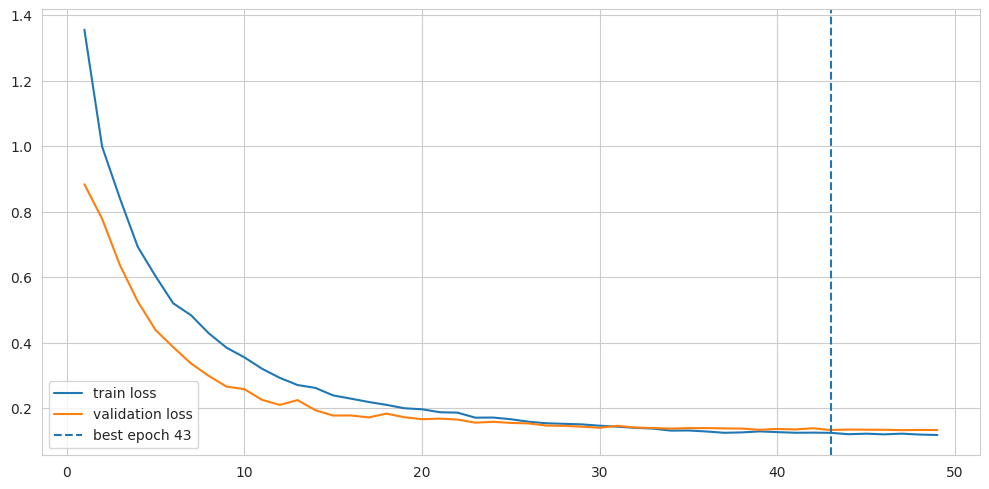

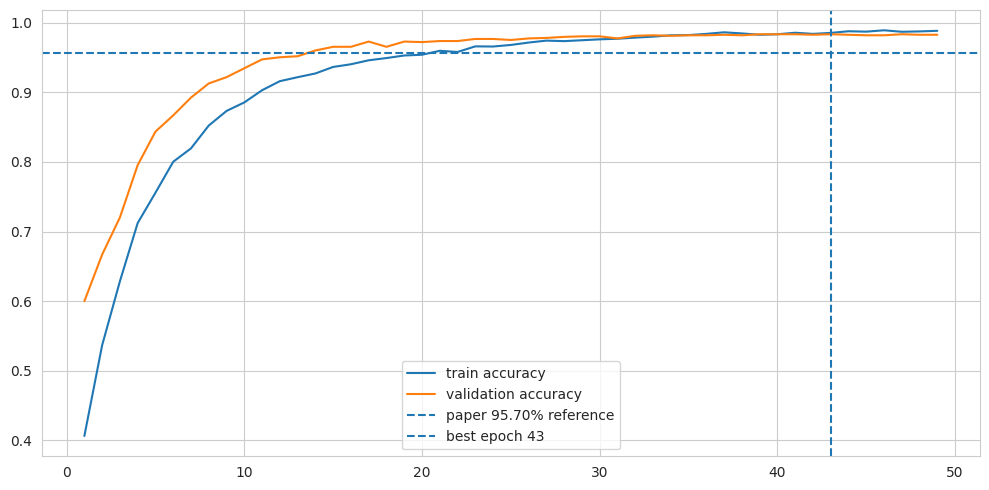

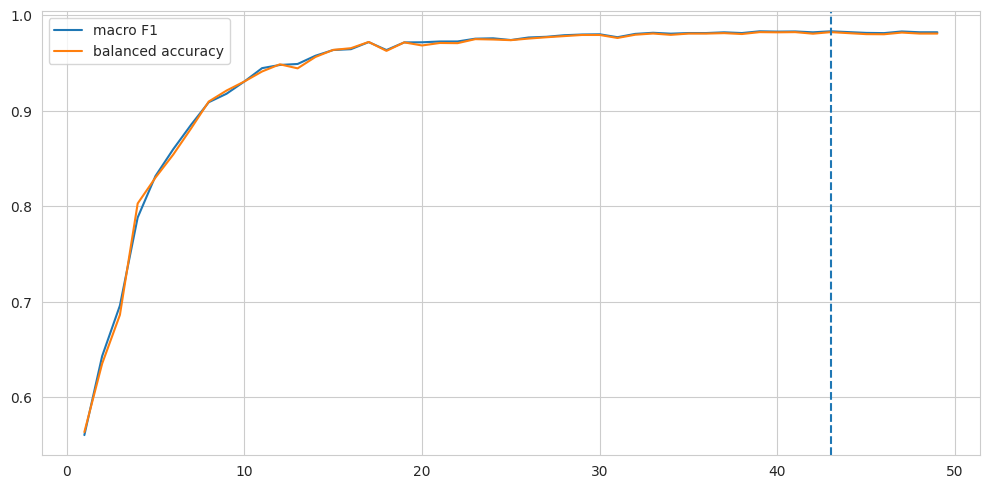

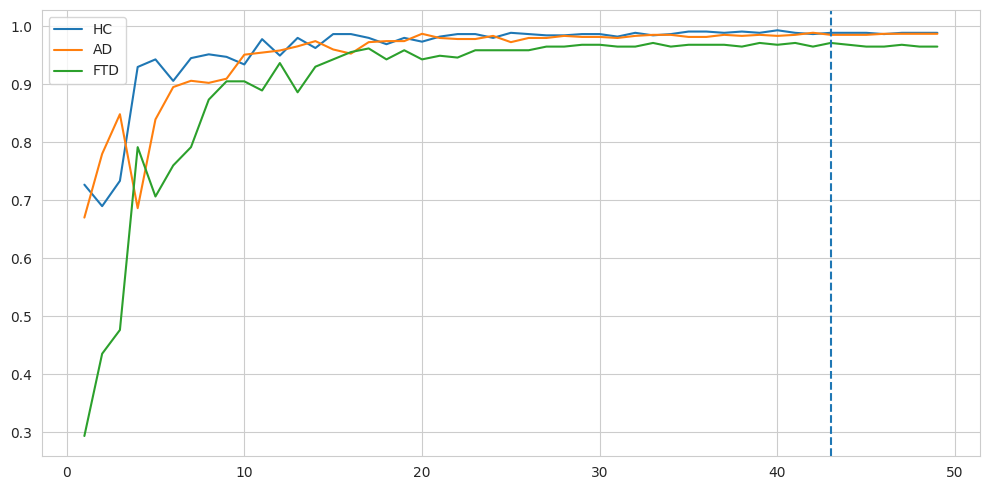

In [9]:
# ============================================================
# CELL 9 — Callbacks and training (Kaggle Version)
# ============================================================
RUN_DIR.mkdir(parents=True, exist_ok=True)

def current_lr(optimizer):
    try:
        # Compatibility fix for reading LearningRateSchedules across Keras 2 & 3
        obj = optimizer.learning_rate
        if callable(obj):
            return float(obj(optimizer.iterations))
        return float(tf.keras.backend.get_value(obj))
    except Exception:
        return np.nan

class ValidationMetrics(Callback):
    def __init__(self, sequence, labels):
        super().__init__()
        self.sequence = sequence
        self.labels = np.asarray(labels, dtype=np.int32)
        self.rows = []

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        probabilities = self.model.predict(self.sequence, verbose=0)
        predictions = np.argmax(probabilities, axis=1)

        macro_f1 = f1_score(self.labels, predictions, average="macro", zero_division=0)
        balanced = balanced_accuracy_score(self.labels, predictions)
        recalls = recall_score(
            self.labels,
            predictions,
            labels=[0, 1, 2],
            average=None,
            zero_division=0,
        )

        lr = current_lr(self.model.optimizer)
        logs["val_macro_f1"] = float(macro_f1)
        logs["val_balanced_accuracy"] = float(balanced)
        logs["val_recall_HC"] = float(recalls[0])
        logs["val_recall_AD"] = float(recalls[1])
        logs["val_recall_FTD"] = float(recalls[2])
        logs["learning_rate"] = float(lr)

        self.rows.append(
            {
                "epoch": epoch + 1,
                "loss": logs.get("loss", np.nan),
                "accuracy": logs.get("accuracy", np.nan),
                "val_loss": logs.get("val_loss", np.nan),
                "val_accuracy": logs.get("val_accuracy", np.nan),
                "val_macro_f1": macro_f1,
                "val_balanced_accuracy": balanced,
                "val_recall_HC": recalls[0],
                "val_recall_AD": recalls[1],
                "val_recall_FTD": recalls[2],
                "learning_rate": lr,
            }
        )
        print(
            f"\nval_macro_f1={macro_f1:.4f} | val_balanced={balanced:.4f} | "
            f"recall HC/AD/FTD={recalls[0]:.4f}/{recalls[1]:.4f}/{recalls[2]:.4f} | "
            f"lr={lr:.8f}"
        )

class BestCheckpoint(Callback):
    def __init__(self, path):
        super().__init__()
        self.path = Path(path)
        self.best = (-np.inf, -np.inf, np.inf)
        self.best_epoch = None

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        candidate = (
            float(logs["val_macro_f1"]),
            float(logs["val_accuracy"]),
            float(logs["val_loss"]),
        )
        better = (
            candidate[0] > self.best[0] + 1e-6
            or (
                np.isclose(candidate[0], self.best[0], atol=1e-6)
                and candidate[1] > self.best[1] + 1e-6
            )
            or (
                np.isclose(candidate[0], self.best[0], atol=1e-6)
                and np.isclose(candidate[1], self.best[1], atol=1e-6)
                and candidate[2] < self.best[2]
            )
        )
        if better:
            self.best = candidate
            self.best_epoch = epoch + 1
            # Fixed Bug 3: Save entire model in native Keras format to bypass tracking errors
            self.model.save(self.path)
            print(
                f"Saved best checkpoint at epoch {self.best_epoch}: "
                f"F1={candidate[0]:.6f}, acc={candidate[1]:.6f}, loss={candidate[2]:.6f}"
            )

# Fixed file naming conversion for unified model restoration structures
BEST_WEIGHTS_PATH = RUN_DIR / "best_validation_macro_f1.keras"
HISTORY_PATH = RUN_DIR / "training_history.csv"

for path in [BEST_WEIGHTS_PATH, HISTORY_PATH]:
    if path.exists():
        path.unlink()

validation_labels = validation_df["label"].to_numpy(dtype=np.int32)
validation_callback = ValidationMetrics(validation_sequence, validation_labels)
checkpoint_callback = BestCheckpoint(BEST_WEIGHTS_PATH)

history = model.fit(
    train_sequence,
    validation_data=validation_sequence,
    epochs=MAX_EPOCHS,
    callbacks=[
        TerminateOnNaN(),
        validation_callback,
        checkpoint_callback,
        EarlyStopping(
            monitor="val_macro_f1",
            mode="max",
            min_delta=0.001,
            patience=10,
            restore_best_weights=False,
            verbose=1,
        ),
        CSVLogger(str(RUN_DIR / "keras_log.csv"), append=False),
    ],
    verbose=1,
)

if not BEST_WEIGHTS_PATH.exists():
    raise RuntimeError("Best checkpoint was not created.")

# Re-loads the compiled configuration model directly via Keras 3 schema
model = tf.keras.models.load_model(BEST_WEIGHTS_PATH, custom_objects={
    'SparseLabelSmoothedCrossentropy': SparseLabelSmoothedCrossentropy,
    'ChannelSegmentZScoreClip': ChannelSegmentZScoreClip
})

history_df = pd.DataFrame(validation_callback.rows)
history_df.to_csv(HISTORY_PATH, index=False)
best_epoch = checkpoint_callback.best_epoch
best_row = history_df[history_df["epoch"] == best_epoch].iloc[0]

print("\nBest epoch:", best_epoch)
display(best_row.to_frame("value"))

plt.figure(figsize=(10, 5))
plt.plot(history_df["epoch"], history_df["loss"], label="train loss")
plt.plot(history_df["epoch"], history_df["val_loss"], label="validation loss")
plt.axvline(best_epoch, linestyle="--", label=f"best epoch {best_epoch}")
plt.legend(); plt.tight_layout(); plt.show()

plt.figure(figsize=(10, 5))
plt.plot(history_df["epoch"], history_df["accuracy"], label="train accuracy")
plt.plot(history_df["epoch"], history_df["val_accuracy"], label="validation accuracy")
plt.axhline(0.957, linestyle="--", label="paper 95.70% reference")
plt.axvline(best_epoch, linestyle="--", label=f"best epoch {best_epoch}")
plt.legend(); plt.tight_layout(); plt.show()

plt.figure(figsize=(10, 5))
plt.plot(history_df["epoch"], history_df["val_macro_f1"], label="macro F1")
plt.plot(history_df["epoch"], history_df["val_balanced_accuracy"], label="balanced accuracy")
plt.axvline(best_epoch, linestyle="--")
plt.legend(); plt.tight_layout(); plt.show()

plt.figure(figsize=(10, 5))
plt.plot(history_df["epoch"], history_df["val_recall_HC"], label="HC")
plt.plot(history_df["epoch"], history_df["val_recall_AD"], label="AD")
plt.plot(history_df["epoch"], history_df["val_recall_FTD"], label="FTD")
plt.axvline(best_epoch, linestyle="--")
plt.legend(); plt.tight_layout(); plt.show()


42/42 ━━━━━━━━━━━━━━━━━━━━ 4s 76ms/step


,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,macro_auc_ovr
0,0.983459,0.982092,0.983881,0.982092,0.982969,0.983452,0.998531


,precision,recall,f1-score,support
HC,0.989083,0.989083,0.989083,458.000000
AD,0.978533,0.985586,0.982047,555.000000
FTD,0.984026,0.971609,0.977778,317.000000
accuracy,0.983459,0.983459,0.983459,0.983459
macro avg,0.983881,0.982092,0.982969,1330.000000
weighted avg,0.983475,0.983459,0.983452,1330.000000


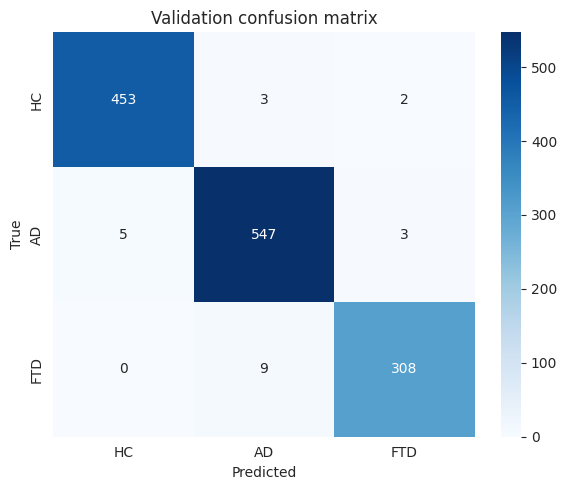

Inspect these results before unlocking the test set.


In [10]:

# ============================================================
# CELL 10 — Validation evaluation
# ============================================================

model.load_weights(BEST_WEIGHTS_PATH)

validation_probabilities = model.predict(validation_sequence, verbose=1)
validation_predictions = np.argmax(validation_probabilities, axis=1)

validation_metrics = pd.DataFrame(
    [
        {
            "accuracy": accuracy_score(validation_labels, validation_predictions),
            "balanced_accuracy": balanced_accuracy_score(validation_labels, validation_predictions),
            "macro_precision": precision_score(
                validation_labels, validation_predictions, average="macro", zero_division=0
            ),
            "macro_recall": recall_score(
                validation_labels, validation_predictions, average="macro", zero_division=0
            ),
            "macro_f1": f1_score(
                validation_labels, validation_predictions, average="macro", zero_division=0
            ),
            "weighted_f1": f1_score(
                validation_labels, validation_predictions, average="weighted", zero_division=0
            ),
            "macro_auc_ovr": roc_auc_score(
                validation_labels,
                validation_probabilities,
                multi_class="ovr",
                average="macro",
            ),
        }
    ]
)

display(validation_metrics)

validation_report = pd.DataFrame(
    classification_report(
        validation_labels,
        validation_predictions,
        labels=[0, 1, 2],
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0,
    )
).T
display(validation_report)

cm = confusion_matrix(validation_labels, validation_predictions, labels=[0, 1, 2])
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Validation confusion matrix")
plt.tight_layout(); plt.show()

validation_metrics.to_csv(RUN_DIR / "validation_metrics.csv", index=False)
validation_report.to_csv(RUN_DIR / "validation_report.csv")

print("Inspect these results before unlocking the test set.")


In [11]:
# ============================================================
# FINAL PRE-TEST INTEGRITY AUDIT
# ============================================================

from pathlib import Path
import numpy as np

# Correct split sizes
assert len(train_df) == 9304
assert len(validation_df) == 1330
assert len(locked_test_df) == 2659

# All subjects intentionally occur in every split
assert train_df["participant_id"].nunique() == 88
assert validation_df["participant_id"].nunique() == 88
assert locked_test_df["participant_id"].nunique() == 88

# No exact segment overlap
train_segment_ids = set(train_df["segment_uid"])
validation_segment_ids = set(validation_df["segment_uid"])
test_segment_ids = set(locked_test_df["segment_uid"])

assert train_segment_ids.isdisjoint(validation_segment_ids)
assert train_segment_ids.isdisjoint(test_segment_ids)
assert validation_segment_ids.isdisjoint(test_segment_ids)

# Best model checkpoint exists
assert BEST_WEIGHTS_PATH.exists(), (
    f"Checkpoint not found: {BEST_WEIGHTS_PATH}"
)

# Reload selected validation checkpoint
model.load_weights(BEST_WEIGHTS_PATH)

# Validation order must remain fixed
assert validation_sequence.shuffle is False

# Test class counts
expected_test_counts = {
    "HC": 914,
    "AD": 1111,
    "FTD": 634,
}

observed_test_counts = (
    locked_test_df["group"]
    .value_counts()
    .to_dict()
)

assert observed_test_counts == expected_test_counts, (
    f"Unexpected test counts: {observed_test_counts}"
)

print("Pre-test audit passed.")
print("Locked test segments:", len(locked_test_df))
print("Best checkpoint:", BEST_WEIGHTS_PATH)
print("The frozen test set is ready for one final evaluation.")

Pre-test audit passed.
Locked test segments: 2659
Best checkpoint: /kaggle/working/eeg_multiclass_final/runs/corrected_multibranch_seed_42/best_validation_macro_f1.keras
The frozen test set is ready for one final evaluation.


84/84 ━━━━━━━━━━━━━━━━━━━━ 5s 61ms/step


,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,macro_auc_ovr,correct_segments,beats_paper_95_70
0,0.985709,0.985791,0.984329,0.985791,0.985044,0.985721,0.999505,2621,True


,precision,recall,f1-score,support
HC,0.991209,0.986871,0.989035,914.000000
AD,0.988257,0.984698,0.986474,1111.000000
FTD,0.973520,0.985804,0.979624,634.000000
accuracy,0.985709,0.985709,0.985709,0.985709
macro avg,0.984329,0.985791,0.985044,2659.000000
weighted avg,0.985758,0.985709,0.985721,2659.000000


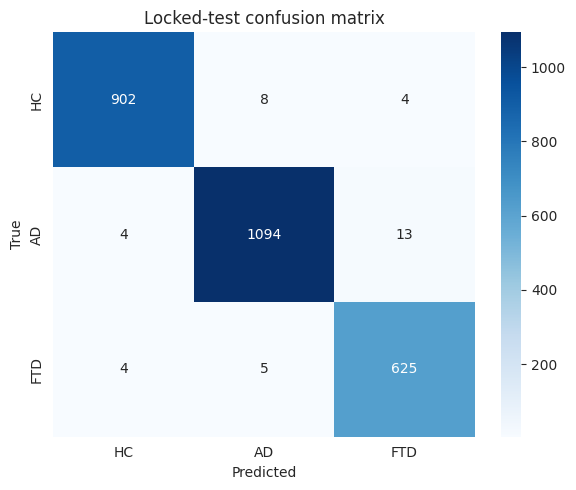

,accuracy,balanced_accuracy,macro_f1,correct_subjects,subjects,note
0,1.0,1.0,1.0,88,88,subject-aggregated under a subject-overlapping...


Saved final outputs in: /kaggle/working/eeg_multiclass_final/runs/corrected_multibranch_seed_42


In [12]:

# ============================================================
# CELL 11 — Locked test evaluation
# Change the flag only after the validation result is accepted.
# ============================================================

RUN_LOCKED_TEST_ONCE = True

if not RUN_LOCKED_TEST_ONCE:
    print("Locked test is protected. Set RUN_LOCKED_TEST_ONCE=True only for final evaluation.")

else:
    locked_test_sequence = EEGMultiInputSequence(
        locked_test_df,
        STANDARDIZED_WELCH_PATH,
        STANDARDIZED_BIOMARKER_PATH,
        BATCH_SIZE,
        shuffle=False,
        seed=MODEL_SEED,
    )

    model.load_weights(BEST_WEIGHTS_PATH)

    test_probabilities = model.predict(locked_test_sequence, verbose=1)
    test_labels = locked_test_df["label"].to_numpy(dtype=np.int32)
    test_predictions = np.argmax(test_probabilities, axis=1)

    test_metrics = pd.DataFrame(
        [
            {
                "accuracy": accuracy_score(test_labels, test_predictions),
                "balanced_accuracy": balanced_accuracy_score(test_labels, test_predictions),
                "macro_precision": precision_score(
                    test_labels, test_predictions, average="macro", zero_division=0
                ),
                "macro_recall": recall_score(
                    test_labels, test_predictions, average="macro", zero_division=0
                ),
                "macro_f1": f1_score(
                    test_labels, test_predictions, average="macro", zero_division=0
                ),
                "weighted_f1": f1_score(
                    test_labels, test_predictions, average="weighted", zero_division=0
                ),
                "macro_auc_ovr": roc_auc_score(
                    test_labels,
                    test_probabilities,
                    multi_class="ovr",
                    average="macro",
                ),
            }
        ]
    )
    test_metrics["correct_segments"] = (
        test_metrics["accuracy"] * len(test_labels)
    ).round().astype(int)
    test_metrics["beats_paper_95_70"] = test_metrics["accuracy"] > 0.9570

    display(test_metrics)

    test_report = pd.DataFrame(
        classification_report(
            test_labels,
            test_predictions,
            labels=[0, 1, 2],
            target_names=CLASS_NAMES,
            output_dict=True,
            zero_division=0,
        )
    ).T
    display(test_report)

    test_cm = confusion_matrix(test_labels, test_predictions, labels=[0, 1, 2])
    plt.figure(figsize=(6, 5))
    sns.heatmap(
        test_cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES,
    )
    plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Locked-test confusion matrix")
    plt.tight_layout(); plt.show()

    prediction_df = locked_test_df[
        [
            "participant_id",
            "group",
            "label",
            "segment_uid",
            "local_segment_index",
            "original_segment_index",
        ]
    ].copy()
    prediction_df["predicted_label"] = test_predictions
    prediction_df["prob_HC"] = test_probabilities[:, 0]
    prediction_df["prob_AD"] = test_probabilities[:, 1]
    prediction_df["prob_FTD"] = test_probabilities[:, 2]

    subject_df = (
        prediction_df.groupby("participant_id", as_index=False)
        .agg(
            true_label=("label", "first"),
            group=("group", "first"),
            probability_HC=("prob_HC", "mean"),
            probability_AD=("prob_AD", "mean"),
            probability_FTD=("prob_FTD", "mean"),
            test_segments=("label", "size"),
        )
    )
    subject_probabilities = subject_df[
        ["probability_HC", "probability_AD", "probability_FTD"]
    ].to_numpy()
    subject_labels = subject_df["true_label"].to_numpy(dtype=np.int32)
    subject_predictions = np.argmax(subject_probabilities, axis=1)
    subject_df["predicted_label"] = subject_predictions

    subject_metrics = pd.DataFrame(
        [
            {
                "accuracy": accuracy_score(subject_labels, subject_predictions),
                "balanced_accuracy": balanced_accuracy_score(subject_labels, subject_predictions),
                "macro_f1": f1_score(
                    subject_labels, subject_predictions, average="macro", zero_division=0
                ),
                "correct_subjects": int(np.sum(subject_labels == subject_predictions)),
                "subjects": len(subject_labels),
                "note": "subject-aggregated under a subject-overlapping segment split",
            }
        ]
    )
    display(subject_metrics)

    test_metrics.to_csv(RUN_DIR / "locked_test_segment_metrics.csv", index=False)
    test_report.to_csv(RUN_DIR / "locked_test_report.csv")
    prediction_df.to_csv(RUN_DIR / "locked_test_segment_predictions.csv", index=False)
    subject_metrics.to_csv(RUN_DIR / "locked_test_subject_metrics.csv", index=False)
    subject_df.to_csv(RUN_DIR / "locked_test_subject_predictions.csv", index=False)

    print("Saved final outputs in:", RUN_DIR)


Embedding layer: fusion_ln2
Embedding output shape: (None, 96)
Development segments: 10634
Locked-test segments: 2659
333/333 ━━━━━━━━━━━━━━━━━━━━ 21s 63ms/step
84/84 ━━━━━━━━━━━━━━━━━━━━ 5s 60ms/step

Development embedding shape: (10634, 96)
Test embedding shape: (2659, 96)

PCA components: 50
Cumulative explained variance: 0.979601
[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 2659 samples in 0.001s...
[t-SNE] Computed neighbors for 2659 samples in 0.188s...
[t-SNE] Computed conditional probabilities for sample 1000 / 2659
[t-SNE] Computed conditional probabilities for sample 2000 / 2659
[t-SNE] Computed conditional probabilities for sample 2659 / 2659
[t-SNE] Mean sigma: 1.877635
[t-SNE] KL divergence after 250 iterations with early exaggeration: 61.763130
[t-SNE] KL divergence after 1500 iterations: 0.667611


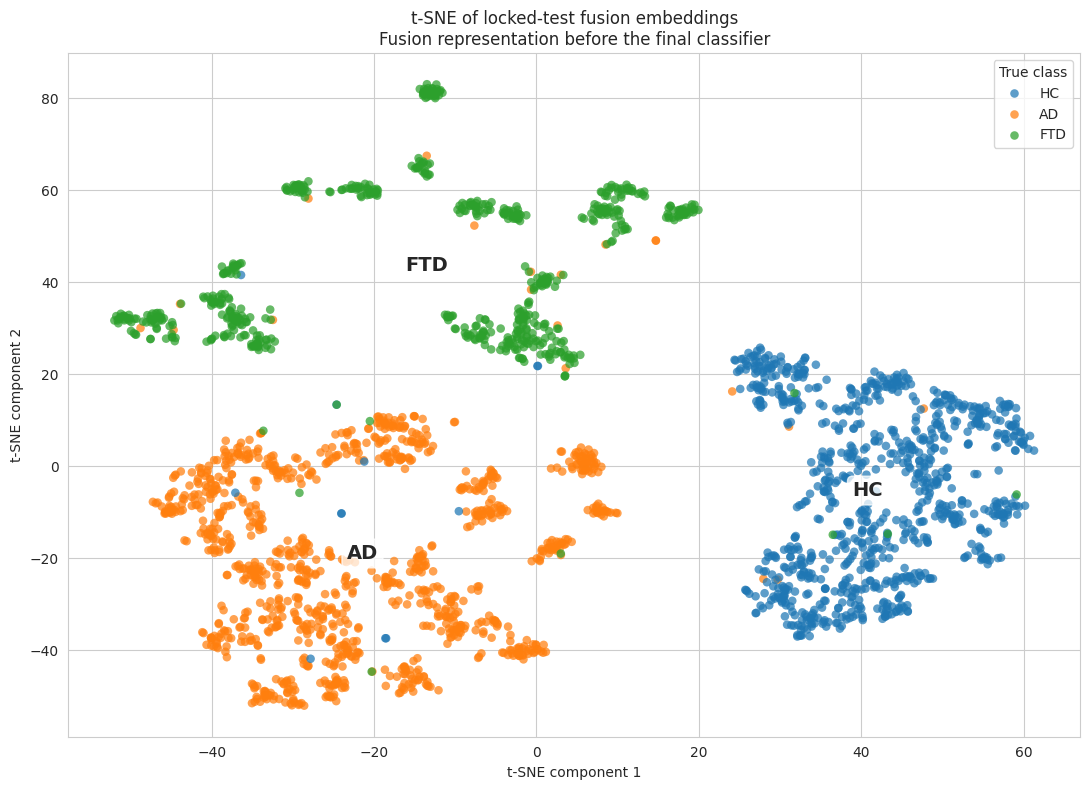

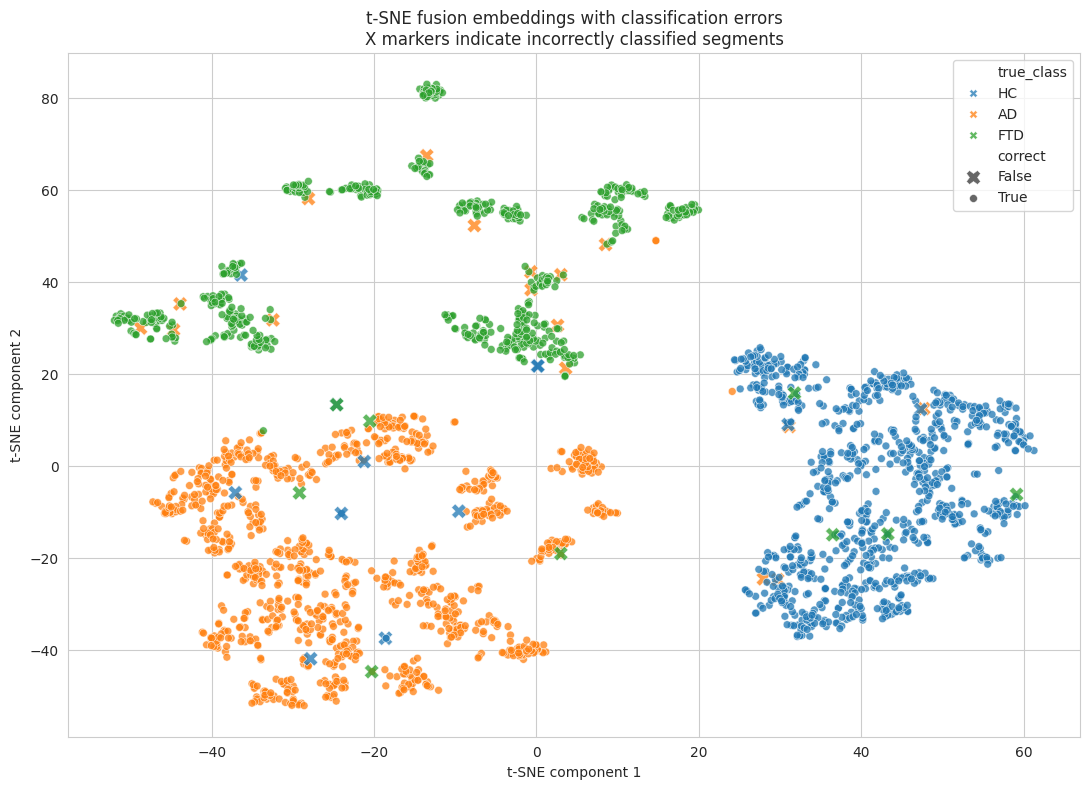


Embedding diagnostics:


,embedding_layer,embedding_dimensions,pca_dimensions,pca_explained_variance,class_silhouette_pca,predicted_class_silhouette_pca,subject_silhouette_pca,test_segments,test_errors
0,fusion_ln2,96,50,0.979601,0.294608,0.299015,0.099764,2659,38



Interpretation check:
True-class silhouette: 0.294608
Subject silhouette: 0.099764
Diagnostic-class separation is at least as strong as subject separation in PCA space.

Saved t-SNE outputs in:
/kaggle/working/eeg_multiclass_final/runs/corrected_multibranch_seed_42/explainability/tsne_fusion_features


In [13]:
import inspect
import json
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score


# ------------------------------------------------------------
# 1. Output directory
# ------------------------------------------------------------

TSNE_DIR = (
    Path(RUN_DIR)
    / "explainability"
    / "tsne_fusion_features"
)

TSNE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# 2. Configuration
# ------------------------------------------------------------

EMBEDDING_LAYER_NAME = (
    "fusion_ln2"
)

PCA_COMPONENTS = 50

TSNE_PERPLEXITY = 30.0
TSNE_ITERATIONS = 1500

TSNE_RANDOM_STATE = MODEL_SEED


# ------------------------------------------------------------
# 3. Verify and reload the selected model checkpoint
# ------------------------------------------------------------

assert Path(BEST_WEIGHTS_PATH).exists(), (
    f"Best checkpoint not found:\n"
    f"{BEST_WEIGHTS_PATH}"
)

model.load_weights(
    BEST_WEIGHTS_PATH
)

available_layer_names = [
    layer.name
    for layer in model.layers
]

assert (
    EMBEDDING_LAYER_NAME
    in available_layer_names
), (
    f"Layer {EMBEDDING_LAYER_NAME!r} was not found.\n"
    f"Available fusion-related layers:\n"
    + "\n".join(
        name
        for name in available_layer_names
        if "fusion" in name
    )
)

embedding_layer = model.get_layer(
    EMBEDDING_LAYER_NAME
)

print(
    "Embedding layer:",
    embedding_layer.name
)

print(
    "Embedding output shape:",
    embedding_layer.output.shape
)


# ------------------------------------------------------------
# 4. Create an intermediate feature-extraction model
#
# This model shares all weights with the trained classifier.
# ------------------------------------------------------------

feature_extractor = tf.keras.Model(
    inputs=model.inputs,
    outputs=embedding_layer.output,
    name="fusion_feature_extractor"
)


# ------------------------------------------------------------
# 5. Create an unshuffled development sequence
#
# PCA and feature scaling are fitted only on:
#   training + validation
# ------------------------------------------------------------

development_df = pd.concat(
    [
        train_df,
        validation_df,
    ],
    axis=0,
    ignore_index=True
)

development_sequence = EEGMultiInputSequence(
    dataframe=development_df,

    welch_path=(
        STANDARDIZED_WELCH_PATH
    ),

    biomarker_path=(
        STANDARDIZED_BIOMARKER_PATH
    ),

    batch_size=BATCH_SIZE,
    shuffle=False,
    seed=MODEL_SEED,
)


# ------------------------------------------------------------
# 6. Recreate the locked-test sequence when necessary
# ------------------------------------------------------------

if (
    "locked_test_sequence"
    not in globals()
):
    locked_test_sequence = EEGMultiInputSequence(
        dataframe=locked_test_df,

        welch_path=(
            STANDARDIZED_WELCH_PATH
        ),

        biomarker_path=(
            STANDARDIZED_BIOMARKER_PATH
        ),

        batch_size=BATCH_SIZE,
        shuffle=False,
        seed=MODEL_SEED,
    )

assert locked_test_sequence.shuffle is False

print(
    "Development segments:",
    len(development_df)
)

print(
    "Locked-test segments:",
    len(locked_test_df)
)


# ------------------------------------------------------------
# 7. Extract development and locked-test embeddings
# ------------------------------------------------------------

development_embeddings = (
    feature_extractor.predict(
        development_sequence,
        verbose=1
    )
)

test_embeddings = (
    feature_extractor.predict(
        locked_test_sequence,
        verbose=1
    )
)

development_embeddings = np.asarray(
    development_embeddings,
    dtype=np.float32
)

test_embeddings = np.asarray(
    test_embeddings,
    dtype=np.float32
)

assert development_embeddings.shape[0] == (
    len(development_df)
)

assert test_embeddings.shape[0] == (
    len(locked_test_df)
)

assert (
    development_embeddings.shape[1]
    ==
    test_embeddings.shape[1]
)

assert np.isfinite(
    development_embeddings
).all()

assert np.isfinite(
    test_embeddings
).all()

print(
    "\nDevelopment embedding shape:",
    development_embeddings.shape
)

print(
    "Test embedding shape:",
    test_embeddings.shape
)


# ------------------------------------------------------------
# 8. Standardize using development embeddings only
# ------------------------------------------------------------

embedding_scaler = StandardScaler()

development_embeddings_scaled = (
    embedding_scaler.fit_transform(
        development_embeddings
    )
)

test_embeddings_scaled = (
    embedding_scaler.transform(
        test_embeddings
    )
)


# ------------------------------------------------------------
# 9. Fit PCA on development embeddings only
# ------------------------------------------------------------

number_pca_components = min(
    PCA_COMPONENTS,
    development_embeddings_scaled.shape[1],
    development_embeddings_scaled.shape[0] - 1
)

pca_model = PCA(
    n_components=number_pca_components,
    random_state=MODEL_SEED
)

development_embeddings_pca = (
    pca_model.fit_transform(
        development_embeddings_scaled
    )
)

test_embeddings_pca = (
    pca_model.transform(
        test_embeddings_scaled
    )
)

cumulative_explained_variance = float(
    np.sum(
        pca_model.explained_variance_ratio_
    )
)

print(
    "\nPCA components:",
    number_pca_components
)

print(
    "Cumulative explained variance:",
    f"{cumulative_explained_variance:.6f}"
)


# ------------------------------------------------------------
# 10. Configure t-SNE compatibly across sklearn versions
# ------------------------------------------------------------

tsne_arguments = {
    "n_components": 2,
    "perplexity": TSNE_PERPLEXITY,
    "learning_rate": "auto",
    "init": "pca",
    "random_state": TSNE_RANDOM_STATE,
    "method": "barnes_hut",
    "angle": 0.5,
    "verbose": 1,
}

tsne_signature = inspect.signature(
    TSNE
)

if (
    "max_iter"
    in tsne_signature.parameters
):
    tsne_arguments[
        "max_iter"
    ] = TSNE_ITERATIONS

else:
    tsne_arguments[
        "n_iter"
    ] = TSNE_ITERATIONS


# ------------------------------------------------------------
# 11. Fit t-SNE only on locked-test PCA features
#
# Labels are not supplied to t-SNE.
# ------------------------------------------------------------

tsne_model = TSNE(
    **tsne_arguments
)

test_tsne_coordinates = (
    tsne_model.fit_transform(
        test_embeddings_pca
    )
)

assert test_tsne_coordinates.shape == (
    len(locked_test_df),
    2
)

assert np.isfinite(
    test_tsne_coordinates
).all()


# ------------------------------------------------------------
# 12. Obtain predictions
#
# Reuse existing predictions when available.
# ------------------------------------------------------------

use_existing_probabilities = (
    "test_probabilities"
    in globals()
    and
    np.asarray(
        test_probabilities
    ).shape
    ==
    (
        len(locked_test_df),
        N_CLASSES
    )
)

if use_existing_probabilities:

    analysis_test_probabilities = np.asarray(
        test_probabilities,
        dtype=np.float32
    )

else:

    analysis_test_probabilities = (
        model.predict(
            locked_test_sequence,
            verbose=1
        )
    )

test_true_labels = (
    locked_test_df[
        "label"
    ]
    .to_numpy(
        dtype=np.int32
    )
)

test_predicted_labels = np.argmax(
    analysis_test_probabilities,
    axis=1
)

test_confidence = np.max(
    analysis_test_probabilities,
    axis=1
)

test_correct = (
    test_predicted_labels
    ==
    test_true_labels
)


# ------------------------------------------------------------
# 13. Construct the t-SNE results table
# ------------------------------------------------------------

tsne_results_df = locked_test_df[
    [
        "participant_id",
        "group",
        "label",
        "segment_uid",
        "local_segment_index",
        "original_segment_index",
    ]
].copy()

tsne_results_df[
    "true_class"
] = [
    CLASS_NAMES[
        int(label)
    ]
    for label in test_true_labels
]

tsne_results_df[
    "predicted_label"
] = test_predicted_labels

tsne_results_df[
    "predicted_class"
] = [
    CLASS_NAMES[
        int(label)
    ]
    for label in test_predicted_labels
]

tsne_results_df[
    "correct"
] = test_correct

tsne_results_df[
    "confidence"
] = test_confidence

tsne_results_df[
    "tsne_1"
] = test_tsne_coordinates[
    :,
    0
]

tsne_results_df[
    "tsne_2"
] = test_tsne_coordinates[
    :,
    1
]


# ------------------------------------------------------------
# 14. Plot t-SNE coloured by the true diagnostic group
# ------------------------------------------------------------

plt.figure(
    figsize=(11, 8)
)

sns.scatterplot(
    data=tsne_results_df,
    x="tsne_1",
    y="tsne_2",
    hue="true_class",
    hue_order=CLASS_NAMES,
    s=38,
    alpha=0.72,
    linewidth=0
)

class_centroids = (
    tsne_results_df
    .groupby(
        "true_class"
    )[
        [
            "tsne_1",
            "tsne_2"
        ]
    ]
    .mean()
)

for class_name, centroid in (
    class_centroids.iterrows()
):
    plt.text(
        centroid["tsne_1"],
        centroid["tsne_2"],
        class_name,
        fontsize=14,
        fontweight="bold",
        ha="center",
        va="center",
        bbox={
            "boxstyle": "round,pad=0.25",
            "facecolor": "white",
            "alpha": 0.75,
        }
    )

plt.title(
    "t-SNE of locked-test fusion embeddings\n"
    "Fusion representation before the final classifier"
)

plt.xlabel("t-SNE component 1")
plt.ylabel("t-SNE component 2")

plt.legend(
    title="True class",
    loc="best"
)

plt.tight_layout()

CLASS_TSNE_FIGURE_PATH = (
    TSNE_DIR
    / "tsne_true_class.png"
)

plt.savefig(
    CLASS_TSNE_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 15. Plot errors within the t-SNE space
# ------------------------------------------------------------

plt.figure(
    figsize=(11, 8)
)

sns.scatterplot(
    data=tsne_results_df,
    x="tsne_1",
    y="tsne_2",
    hue="true_class",
    hue_order=CLASS_NAMES,
    style="correct",
    markers={
        True: "o",
        False: "X",
    },
    size="correct",
    sizes={
        True: 32,
        False: 110,
    },
    alpha=0.75
)

plt.title(
    "t-SNE fusion embeddings with classification errors\n"
    "X markers indicate incorrectly classified segments"
)

plt.xlabel("t-SNE component 1")
plt.ylabel("t-SNE component 2")

plt.tight_layout()

ERROR_TSNE_FIGURE_PATH = (
    TSNE_DIR
    / "tsne_classification_errors.png"
)

plt.savefig(
    ERROR_TSNE_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 16. Quantitative embedding-separation diagnostics
#
# These scores are calculated in PCA space, not t-SNE space,
# because t-SNE deliberately distorts global geometry.
# ------------------------------------------------------------

subject_codes = (
    locked_test_df[
        "participant_id"
    ]
    .astype("category")
    .cat.codes
    .to_numpy()
)

silhouette_sample_size = min(
    2000,
    len(locked_test_df)
)

class_silhouette = silhouette_score(
    test_embeddings_pca,
    test_true_labels,
    metric="euclidean",
    sample_size=silhouette_sample_size,
    random_state=MODEL_SEED
)

subject_silhouette = silhouette_score(
    test_embeddings_pca,
    subject_codes,
    metric="euclidean",
    sample_size=silhouette_sample_size,
    random_state=MODEL_SEED
)

predicted_class_silhouette = silhouette_score(
    test_embeddings_pca,
    test_predicted_labels,
    metric="euclidean",
    sample_size=silhouette_sample_size,
    random_state=MODEL_SEED
)

embedding_diagnostics_df = pd.DataFrame([
    {
        "embedding_layer": EMBEDDING_LAYER_NAME,
        "embedding_dimensions": int(
            test_embeddings.shape[1]
        ),
        "pca_dimensions": int(
            number_pca_components
        ),
        "pca_explained_variance": (
            cumulative_explained_variance
        ),
        "class_silhouette_pca": float(
            class_silhouette
        ),
        "predicted_class_silhouette_pca": float(
            predicted_class_silhouette
        ),
        "subject_silhouette_pca": float(
            subject_silhouette
        ),
        "test_segments": int(
            len(locked_test_df)
        ),
        "test_errors": int(
            np.sum(
                ~test_correct
            )
        ),
    }
])

print("\nEmbedding diagnostics:")

display(
    embedding_diagnostics_df
)

print(
    "\nInterpretation check:"
)

print(
    "True-class silhouette:",
    f"{class_silhouette:.6f}"
)

print(
    "Subject silhouette:",
    f"{subject_silhouette:.6f}"
)

if (
    subject_silhouette
    >
    class_silhouette
):
    print(
        "RED FLAG: subject separation is stronger than "
        "diagnostic-class separation in PCA space."
    )

else:
    print(
        "Diagnostic-class separation is at least as strong "
        "as subject separation in PCA space."
    )


# ------------------------------------------------------------
# 17. Save all results
# ------------------------------------------------------------

np.save(
    TSNE_DIR
    / "development_fusion_embeddings.npy",
    development_embeddings
)

np.save(
    TSNE_DIR
    / "locked_test_fusion_embeddings.npy",
    test_embeddings
)

np.save(
    TSNE_DIR
    / "locked_test_pca_embeddings.npy",
    test_embeddings_pca
)

np.save(
    TSNE_DIR
    / "locked_test_tsne_coordinates.npy",
    test_tsne_coordinates
)

tsne_results_df.to_csv(
    TSNE_DIR
    / "tsne_segment_results.csv",
    index=False
)

embedding_diagnostics_df.to_csv(
    TSNE_DIR
    / "embedding_diagnostics.csv",
    index=False
)

tsne_configuration = {
    "embedding_layer": EMBEDDING_LAYER_NAME,
    "model_seed": int(MODEL_SEED),
    "pca_components": int(
        number_pca_components
    ),
    "pca_explained_variance": float(
        cumulative_explained_variance
    ),
    "tsne_perplexity": float(
        TSNE_PERPLEXITY
    ),
    "tsne_iterations": int(
        TSNE_ITERATIONS
    ),
    "tsne_random_state": int(
        TSNE_RANDOM_STATE
    ),
    "scaler_fit_data": (
        "training plus validation embeddings only"
    ),
    "pca_fit_data": (
        "training plus validation embeddings only"
    ),
    "tsne_fit_data": (
        "locked test embeddings without labels"
    ),
}

with open(
    TSNE_DIR
    / "tsne_configuration.json",
    "w"
) as file:
    json.dump(
        tsne_configuration,
        file,
        indent=2
    )

print("\nSaved t-SNE outputs in:")
print(TSNE_DIR)

In [14]:
# ============================================================
# EXPLAINABILITY STEP 2A
# Grad-CAM-like temporal × channel saliency extractor
#
# Target layer:
#   temporal_multiscale_concat
#
# Output map:
#   time × EEG channel
#
# Important:
# - Model weights are not changed.
# - Correctly classified test segments are used for the
#   main class-specific channel-importance analysis.
# - Misclassified segments are analysed separately.
# ============================================================

import gc
import json
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf

import matplotlib.pyplot as plt
import seaborn as sns
import mne


# ------------------------------------------------------------
# 1. Output directory
# ------------------------------------------------------------

SALIENCY_DIR = (
    Path(RUN_DIR)
    / "explainability"
    / "gradcam_channel_saliency"
)

SALIENCY_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# 2. Configuration
# ------------------------------------------------------------

SALIENCY_LAYER_NAME = (
    "time_concat"
)

# The activation map is large:
# batch × 1280 × 19 × 96.
# A small batch prevents GPU out-of-memory errors.
SALIENCY_BATCH_SIZE = 4

# Use the same number of correctly classified segments
# from every class to prevent class-size imbalance.
MAX_CORRECT_SEGMENTS_PER_CLASS = 300

SALIENCY_RANDOM_SEED = MODEL_SEED
SALIENCY_EPSILON = 1e-8


# ------------------------------------------------------------
# 3. Reload the selected checkpoint
# ------------------------------------------------------------

assert Path(BEST_WEIGHTS_PATH).exists(), (
    f"Checkpoint was not found:\n"
    f"{BEST_WEIGHTS_PATH}"
)

model.load_weights(
    BEST_WEIGHTS_PATH
)


# ------------------------------------------------------------
# 4. Verify the target activation layer
# ------------------------------------------------------------

available_layer_names = [
    layer.name
    for layer in model.layers
]

assert (
    SALIENCY_LAYER_NAME
    in available_layer_names
), (
    f"Layer {SALIENCY_LAYER_NAME!r} was not found."
)

saliency_layer = model.get_layer(
    SALIENCY_LAYER_NAME
)

print("Saliency layer:", saliency_layer.name)
print("Activation shape:", saliency_layer.output.shape)

assert len(
    saliency_layer.output.shape
) == 4

assert int(
    saliency_layer.output.shape[1]
) == WINDOW_SAMPLES

assert int(
    saliency_layer.output.shape[2]
) == N_CHANNELS


# ------------------------------------------------------------
# 5. Create the Grad-CAM model
#
# Outputs:
# - pre-spatial temporal activations
# - final softmax probabilities
# ------------------------------------------------------------

gradcam_model = tf.keras.Model(
    inputs=model.inputs,
    outputs=[
        saliency_layer.output,
        model.output,
    ],
    name="temporal_channel_gradcam_model"
)


# ------------------------------------------------------------
# 6. Ensure locked-test probabilities are available
# ------------------------------------------------------------

if (
    "test_probabilities"
    not in globals()
    or np.asarray(
        test_probabilities
    ).shape != (
        len(locked_test_df),
        N_CLASSES
    )
):
    if (
        "locked_test_sequence"
        not in globals()
    ):
        locked_test_sequence = EEGMultiInputSequence(
            dataframe=locked_test_df,
            welch_path=STANDARDIZED_WELCH_PATH,
            biomarker_path=STANDARDIZED_BIOMARKER_PATH,
            batch_size=BATCH_SIZE,
            shuffle=False,
            seed=MODEL_SEED,
        )

    test_probabilities = model.predict(
        locked_test_sequence,
        verbose=1
    )


test_probabilities = np.asarray(
    test_probabilities,
    dtype=np.float32
)

test_true_labels = (
    locked_test_df[
        "label"
    ]
    .to_numpy(
        dtype=np.int32
    )
)

test_predicted_labels = np.argmax(
    test_probabilities,
    axis=1
).astype(np.int32)

test_prediction_confidence = np.max(
    test_probabilities,
    axis=1
)

test_correct = (
    test_predicted_labels
    ==
    test_true_labels
)


# ------------------------------------------------------------
# 7. Build the saliency metadata table
# ------------------------------------------------------------

saliency_test_df = (
    locked_test_df
    .copy()
    .reset_index(drop=True)
)

saliency_test_df[
    "test_row_index"
] = np.arange(
    len(saliency_test_df),
    dtype=np.int64
)

saliency_test_df[
    "predicted_label"
] = test_predicted_labels

saliency_test_df[
    "predicted_class"
] = [
    CLASS_NAMES[
        int(label)
    ]
    for label in test_predicted_labels
]

saliency_test_df[
    "confidence"
] = test_prediction_confidence

saliency_test_df[
    "correct"
] = test_correct


# ------------------------------------------------------------
# 8. Select a balanced deterministic subset of correct samples
#
# Random sampling is preferable to selecting only highly
# confident examples, which would bias the explanation.
# ------------------------------------------------------------

saliency_rng = np.random.default_rng(
    SALIENCY_RANDOM_SEED
)

selected_correct_frames = []

for class_label, class_name in enumerate(
    CLASS_NAMES
):
    class_correct_df = saliency_test_df[
        (
            saliency_test_df["label"]
            == class_label
        )
        &
        saliency_test_df["correct"]
    ].copy()

    number_to_select = min(
        MAX_CORRECT_SEGMENTS_PER_CLASS,
        len(class_correct_df)
    )

    selected_positions = saliency_rng.choice(
        class_correct_df.index.to_numpy(),
        size=number_to_select,
        replace=False
    )

    selected_class_df = (
        class_correct_df.loc[
            selected_positions
        ]
        .copy()
    )

    selected_correct_frames.append(
        selected_class_df
    )

    print(
        f"{class_name}: selected "
        f"{len(selected_class_df)} of "
        f"{len(class_correct_df)} correct segments"
    )


selected_correct_df = (
    pd.concat(
        selected_correct_frames,
        axis=0,
        ignore_index=True
    )
    .sort_values(
        [
            "label",
            "participant_id",
            "local_segment_index",
        ]
    )
    .reset_index(drop=True)
)

assert (
    selected_correct_df[
        "correct"
    ]
).all()

print(
    "\nTotal correct segments selected:",
    len(selected_correct_df)
)


# ------------------------------------------------------------
# 9. Grad-CAM calculation for one batch
#
# Output:
#   normalized CAM:
#       batch × 1280 × 19
# ------------------------------------------------------------

@tf.function(
    reduce_retracing=True
)
def calculate_temporal_channel_gradcam(
    input_dictionary,
    target_labels
):
    target_labels = tf.cast(
        target_labels,
        tf.int32
    )

    with tf.GradientTape() as tape:

        (
            activations,
            probabilities
        ) = gradcam_model(
            input_dictionary,
            training=False
        )

        # Explicitly watch the intermediate activations.
        tape.watch(
            activations
        )

        batch_indices = tf.range(
            tf.shape(
                probabilities
            )[0],
            dtype=tf.int32
        )

        gather_indices = tf.stack(
            [
                batch_indices,
                target_labels,
            ],
            axis=1
        )

        target_probabilities = tf.gather_nd(
            probabilities,
            gather_indices
        )

        # Log probability gives a stronger gradient than
        # raw softmax probability when confidence is high.
        target_scores = tf.math.log(
            tf.clip_by_value(
                target_probabilities,
                SALIENCY_EPSILON,
                1.0
            )
        )

    gradients = tape.gradient(
        target_scores,
        activations
    )

    if gradients is None:
        raise RuntimeError(
            "Could not calculate gradients for "
            "the selected activation layer."
        )

    # Grad-CAM weights:
    # average gradients over time and electrodes.
    feature_weights = tf.reduce_mean(
        gradients,
        axis=[
            1,
            2
        ],
        keepdims=True
    )

    raw_cam = tf.reduce_sum(
        feature_weights
        * activations,
        axis=-1
    )

    # Positive evidence for the target class.
    positive_cam = tf.nn.relu(
        raw_cam
    )

    maximum_value = tf.reduce_max(
        positive_cam,
        axis=[
            1,
            2
        ],
        keepdims=True
    )

    normalized_cam = (
        positive_cam
        / (
            maximum_value
            + SALIENCY_EPSILON
        )
    )

    return (
        normalized_cam,
        target_probabilities
    )


print(
    "\nGrad-CAM computation function created."
)


Saliency layer: time_concat
Activation shape: (None, 1280, 19, 96)
HC: selected 300 of 902 correct segments
AD: selected 300 of 1094 correct segments
FTD: selected 300 of 625 correct segments

Total correct segments selected: 900

Grad-CAM computation function created.


In [15]:
# ============================================================
# EXPLAINABILITY STEP 2B
# Calculate channel and temporal importance
# ============================================================

correct_saliency_sequence = EEGMultiInputSequence(
    dataframe=selected_correct_df,
    welch_path=STANDARDIZED_WELCH_PATH,
    biomarker_path=STANDARDIZED_BIOMARKER_PATH,
    batch_size=SALIENCY_BATCH_SIZE,
    shuffle=False,
    seed=MODEL_SEED,
)


all_channel_importance = []
all_temporal_importance = []
all_target_probabilities = []
all_zero_cam_flags = []


for batch_index in range(
    len(correct_saliency_sequence)
):

    (
        batch_inputs,
        batch_labels
    ) = correct_saliency_sequence[
        batch_index
    ]

    (
        batch_cam,
        batch_target_probability
    ) = calculate_temporal_channel_gradcam(
        {
            key: tf.convert_to_tensor(
                value,
                dtype=tf.float32
            )
            for key, value
            in batch_inputs.items()
        },
        tf.convert_to_tensor(
            batch_labels,
            dtype=tf.int32
        )
    )

    batch_cam = batch_cam.numpy().astype(
        np.float32
    )

    batch_target_probability = (
        batch_target_probability
        .numpy()
        .astype(
            np.float32
        )
    )

    # Mean saliency over time gives one value per channel.
    batch_channel_importance = np.mean(
        batch_cam,
        axis=1
    )

    # Mean saliency over channels gives one value per time point.
    batch_temporal_importance = np.mean(
        batch_cam,
        axis=2
    )

    # Normalize every segment's channel importance so that
    # its 19 channels sum to one.
    batch_channel_importance = (
        batch_channel_importance
        / (
            np.sum(
                batch_channel_importance,
                axis=1,
                keepdims=True
            )
            + SALIENCY_EPSILON
        )
    )

    zero_cam_flags = (
        np.max(
            batch_cam,
            axis=(
                1,
                2
            )
        )
        <= SALIENCY_EPSILON
    )

    all_channel_importance.append(
        batch_channel_importance
    )

    all_temporal_importance.append(
        batch_temporal_importance
    )

    all_target_probabilities.append(
        batch_target_probability
    )

    all_zero_cam_flags.append(
        zero_cam_flags
    )


channel_importance_array = np.concatenate(
    all_channel_importance,
    axis=0
)

temporal_importance_array = np.concatenate(
    all_temporal_importance,
    axis=0
)

saliency_target_probabilities = np.concatenate(
    all_target_probabilities,
    axis=0
)

zero_cam_flags = np.concatenate(
    all_zero_cam_flags,
    axis=0
)


assert channel_importance_array.shape == (
    len(selected_correct_df),
    N_CHANNELS
)

assert temporal_importance_array.shape == (
    len(selected_correct_df),
    WINDOW_SAMPLES
)

assert np.isfinite(
    channel_importance_array
).all()

assert np.isfinite(
    temporal_importance_array
).all()


print(
    "Channel importance shape:",
    channel_importance_array.shape
)

print(
    "Temporal importance shape:",
    temporal_importance_array.shape
)

print(
    "Zero-valued CAM maps:",
    int(
        np.sum(
            zero_cam_flags
        )
    )
)


# ------------------------------------------------------------
# Add per-channel values to the segment table
# ------------------------------------------------------------

segment_channel_importance_df = (
    selected_correct_df[
        [
            "participant_id",
            "group",
            "label",
            "predicted_label",
            "confidence",
            "segment_uid",
            "local_segment_index",
            "original_segment_index",
        ]
    ]
    .copy()
)

for channel_index, channel_name in enumerate(
    TARGET_CHANNELS
):
    segment_channel_importance_df[
        f"importance_{channel_name}"
    ] = channel_importance_array[
        :,
        channel_index
    ]

segment_channel_importance_df[
    "saliency_target_probability"
] = saliency_target_probabilities

segment_channel_importance_df[
    "zero_cam"
] = zero_cam_flags


# ------------------------------------------------------------
# Class-level channel summaries
# ------------------------------------------------------------

class_channel_rows = []

for class_label, class_name in enumerate(
    CLASS_NAMES
):

    class_mask = (
        selected_correct_df[
            "label"
        ].to_numpy()
        == class_label
    )

    class_values = channel_importance_array[
        class_mask
    ]

    for channel_index, channel_name in enumerate(
        TARGET_CHANNELS
    ):

        channel_values = class_values[
            :,
            channel_index
        ]

        class_channel_rows.append({
            "class_label": class_label,
            "class_name": class_name,
            "channel": channel_name,
            "mean_importance": float(
                np.mean(
                    channel_values
                )
            ),
            "std_importance": float(
                np.std(
                    channel_values,
                    ddof=1
                )
            ),
            "median_importance": float(
                np.median(
                    channel_values
                )
            ),
            "segments": int(
                len(
                    channel_values
                )
            ),
        })


class_channel_importance_df = pd.DataFrame(
    class_channel_rows
)


# ------------------------------------------------------------
# Global channel summaries
# ------------------------------------------------------------

global_channel_importance_df = pd.DataFrame({
    "channel": TARGET_CHANNELS,
    "mean_importance": np.mean(
        channel_importance_array,
        axis=0
    ),
    "std_importance": np.std(
        channel_importance_array,
        axis=0,
        ddof=1
    ),
    "median_importance": np.median(
        channel_importance_array,
        axis=0
    ),
})

global_channel_importance_df[
    "rank"
] = (
    global_channel_importance_df[
        "mean_importance"
    ]
    .rank(
        ascending=False,
        method="min"
    )
    .astype(int)
)

global_channel_importance_df = (
    global_channel_importance_df
    .sort_values(
        "mean_importance",
        ascending=False
    )
    .reset_index(drop=True)
)


print("\nGlobal channel ranking:")

display(
    global_channel_importance_df
)


print("\nTop five channels by class:")

for class_name in CLASS_NAMES:

    class_ranking = (
        class_channel_importance_df[
            class_channel_importance_df[
                "class_name"
            ]
            == class_name
        ]
        .sort_values(
            "mean_importance",
            ascending=False
        )
        .head(5)
    )

    print(f"\n{class_name}")

    display(
        class_ranking[
            [
                "channel",
                "mean_importance",
                "std_importance",
            ]
        ]
    )

Channel importance shape: (900, 19)
Temporal importance shape: (900, 1280)
Zero-valued CAM maps: 0

Global channel ranking:


,channel,mean_importance,std_importance,median_importance,rank
0,O2,0.056394,0.007926,0.054570,1
1,O1,0.055771,0.007419,0.054276,2
2,T5,0.055702,0.005767,0.054290,3
3,T6,0.055504,0.006094,0.054287,4
4,T3,0.053638,0.003996,0.053134,5
5,T4,0.053377,0.004300,0.052920,6
6,F7,0.053277,0.005179,0.052802,7
7,F8,0.052667,0.004527,0.052463,8
8,Fp1,0.052584,0.005201,0.052181,9
9,Fp2,0.052424,0.005041,0.051995,10



Top five channels by class:

HC


,channel,mean_importance,std_importance
18,O2,0.058465,0.006846
12,T5,0.057649,0.006025
17,O1,0.057340,0.007375
16,T6,0.055910,0.004617
13,P3,0.053574,0.002841



AD


,channel,mean_importance,std_importance
37,O2,0.055199,0.006768
35,T6,0.055030,0.004459
36,O1,0.054896,0.005601
31,T5,0.054788,0.005012
30,T4,0.054429,0.004681



FTD


,channel,mean_importance,std_importance
54,T6,0.055572,0.008370
56,O2,0.055517,0.009471
55,O1,0.055077,0.008719
50,T5,0.054668,0.005733
45,T3,0.054055,0.004707


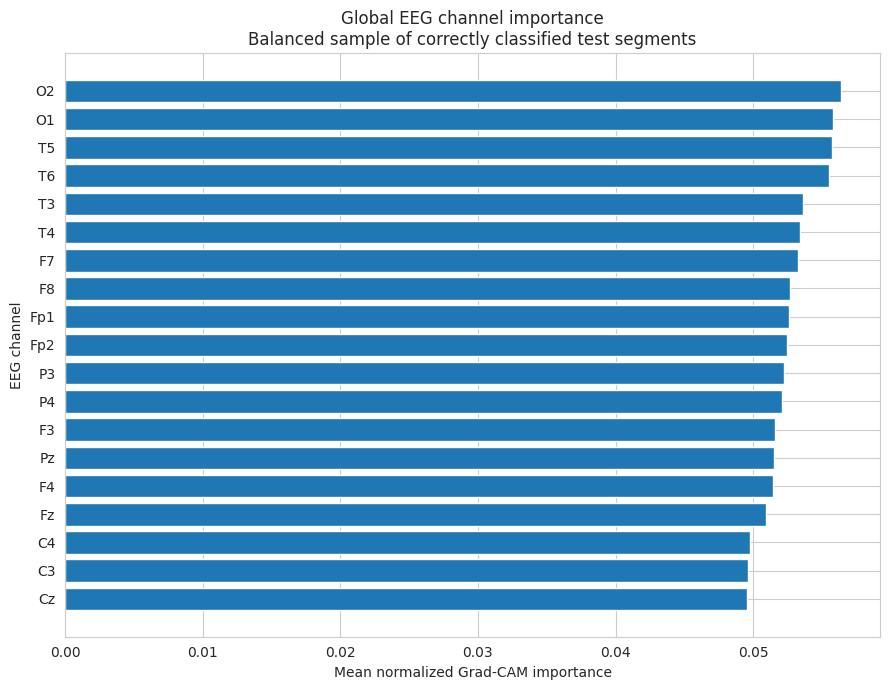

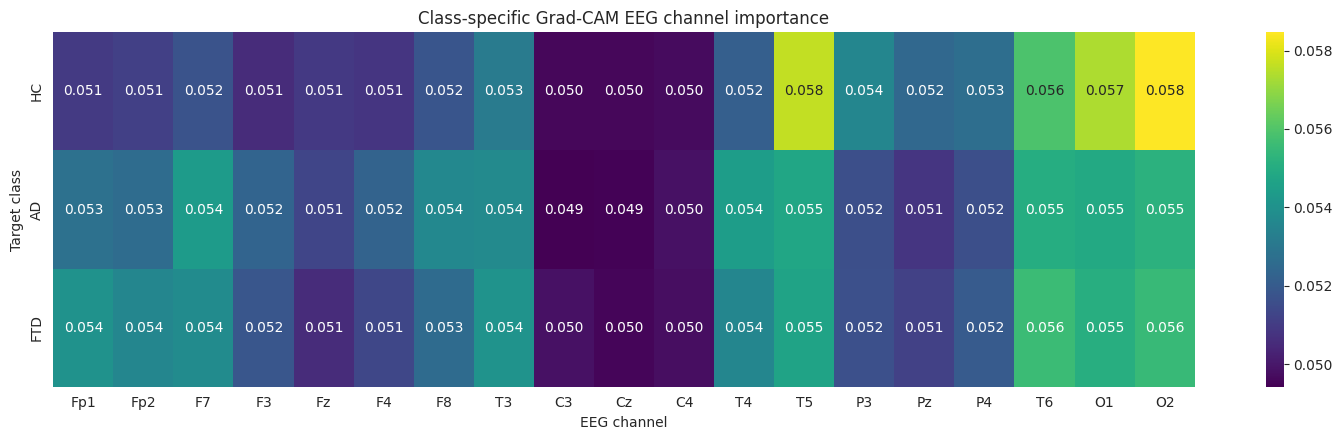

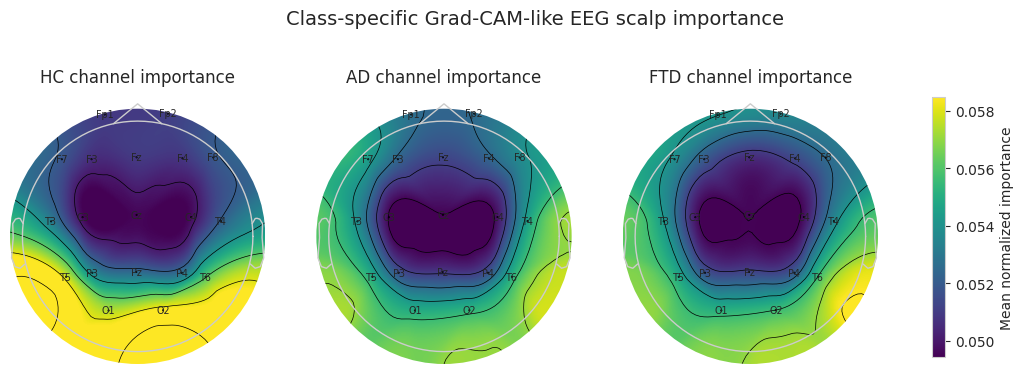

In [16]:
# ============================================================
# EXPLAINABILITY STEP 2C
# Channel-importance plots and scalp topomaps
# ============================================================

# ------------------------------------------------------------
# 1. Global channel-importance bar plot
# ------------------------------------------------------------

global_plot_df = (
    global_channel_importance_df
    .sort_values(
        "mean_importance",
        ascending=True
    )
)

plt.figure(
    figsize=(9, 7)
)

plt.barh(
    global_plot_df[
        "channel"
    ],
    global_plot_df[
        "mean_importance"
    ]
)

plt.xlabel(
    "Mean normalized Grad-CAM importance"
)

plt.ylabel(
    "EEG channel"
)

plt.title(
    "Global EEG channel importance\n"
    "Balanced sample of correctly classified test segments"
)

plt.tight_layout()

GLOBAL_CHANNEL_FIGURE_PATH = (
    SALIENCY_DIR
    / "global_channel_importance.png"
)

plt.savefig(
    GLOBAL_CHANNEL_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 2. Class × channel heatmap
# ------------------------------------------------------------

class_channel_matrix = (
    class_channel_importance_df
    .pivot(
        index="class_name",
        columns="channel",
        values="mean_importance"
    )
    .reindex(
        index=CLASS_NAMES,
        columns=TARGET_CHANNELS
    )
)

plt.figure(
    figsize=(15, 4.5)
)

sns.heatmap(
    class_channel_matrix,
    annot=True,
    fmt=".3f",
    cmap="viridis"
)

plt.xlabel(
    "EEG channel"
)

plt.ylabel(
    "Target class"
)

plt.title(
    "Class-specific Grad-CAM EEG channel importance"
)

plt.tight_layout()

CLASS_CHANNEL_HEATMAP_PATH = (
    SALIENCY_DIR
    / "class_channel_importance_heatmap.png"
)

plt.savefig(
    CLASS_CHANNEL_HEATMAP_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 3. Prepare standard 10–20 montage
#
# Older channel names are mapped only for scalp coordinates:
# T3 → T7
# T4 → T8
# T5 → P7
# T6 → P8
# ------------------------------------------------------------

TOPO_CHANNEL_NAMES = [
    "Fp1",
    "Fp2",
    "F7",
    "F3",
    "Fz",
    "F4",
    "F8",
    "T7",
    "C3",
    "Cz",
    "C4",
    "T8",
    "P7",
    "P3",
    "Pz",
    "P4",
    "P8",
    "O1",
    "O2",
]

assert len(
    TOPO_CHANNEL_NAMES
) == N_CHANNELS

topomap_info = mne.create_info(
    ch_names=TOPO_CHANNEL_NAMES,
    sfreq=TARGET_SFREQ,
    ch_types=[
        "eeg"
    ] * N_CHANNELS
)

topomap_info.set_montage(
    "standard_1020",
    on_missing="raise"
)


# ------------------------------------------------------------
# 4. Use one common scale for all class topomaps
# ------------------------------------------------------------

topomap_values_by_class = {}

for class_name in CLASS_NAMES:

    class_values = (
        class_channel_importance_df[
            class_channel_importance_df[
                "class_name"
            ]
            == class_name
        ]
        .set_index(
            "channel"
        )
        .reindex(
            TARGET_CHANNELS
        )[
            "mean_importance"
        ]
        .to_numpy(
            dtype=np.float64
        )
    )

    topomap_values_by_class[
        class_name
    ] = class_values


all_topomap_values = np.concatenate(
    list(
        topomap_values_by_class.values()
    )
)

topomap_vmin = float(
    np.min(
        all_topomap_values
    )
)

topomap_vmax = float(
    np.max(
        all_topomap_values
    )
)


# ------------------------------------------------------------
# 5. Plot class-specific topomaps
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    3,
    figsize=(14, 4.5)
)

last_image = None

for axis, class_name in zip(
    axes,
    CLASS_NAMES
):

    last_image, _ = mne.viz.plot_topomap(
        topomap_values_by_class[
            class_name
        ],
        topomap_info,
        axes=axis,
        show=False,
        contours=6,
        cmap="viridis",
        vlim=(
            topomap_vmin,
            topomap_vmax
        ),
        names=TARGET_CHANNELS,
        sensors=True
    )

    axis.set_title(
        f"{class_name} channel importance"
    )


fig.colorbar(
    last_image,
    ax=axes,
    shrink=0.75,
    label="Mean normalized importance"
)

fig.suptitle(
    "Class-specific Grad-CAM-like EEG scalp importance",
    fontsize=14
)

CLASS_TOPOMAP_PATH = (
    SALIENCY_DIR
    / "class_channel_importance_topomaps.png"
)

plt.savefig(
    CLASS_TOPOMAP_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

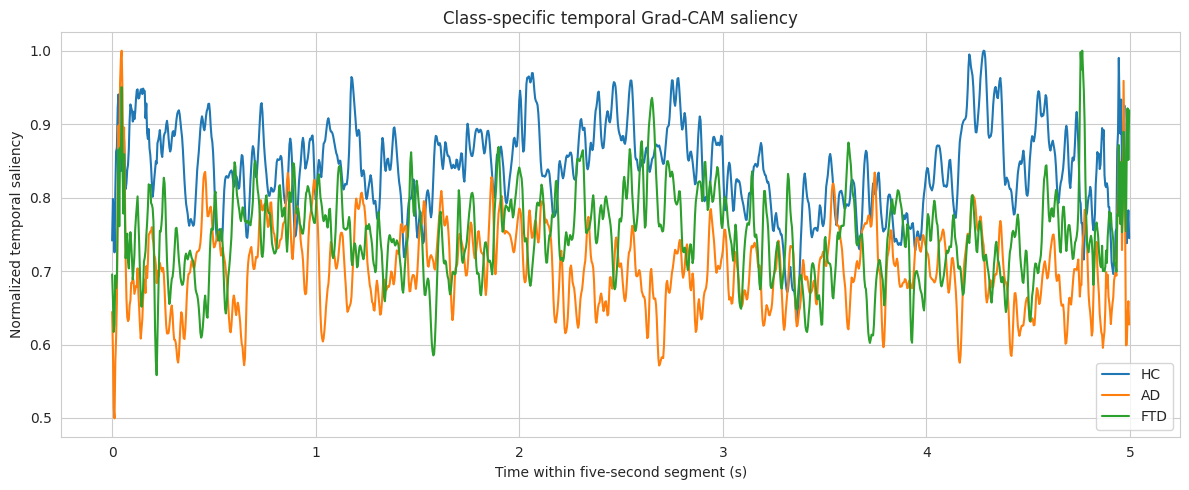

In [17]:
# ============================================================
# EXPLAINABILITY STEP 2D
# Temporal saliency by diagnostic class
# ============================================================

time_axis_seconds = (
    np.arange(
        WINDOW_SAMPLES
    )
    / TARGET_SFREQ
)

class_temporal_importance = {}

for class_label, class_name in enumerate(
    CLASS_NAMES
):

    class_mask = (
        selected_correct_df[
            "label"
        ].to_numpy()
        == class_label
    )

    class_mean_temporal_importance = np.mean(
        temporal_importance_array[
            class_mask
        ],
        axis=0
    )

    # Normalize each class curve for shape comparison.
    class_mean_temporal_importance = (
        class_mean_temporal_importance
        / (
            np.max(
                class_mean_temporal_importance
            )
            + SALIENCY_EPSILON
        )
    )

    class_temporal_importance[
        class_name
    ] = class_mean_temporal_importance


plt.figure(
    figsize=(12, 5)
)

for class_name in CLASS_NAMES:

    plt.plot(
        time_axis_seconds,
        class_temporal_importance[
            class_name
        ],
        label=class_name
    )

plt.xlabel(
    "Time within five-second segment (s)"
)

plt.ylabel(
    "Normalized temporal saliency"
)

plt.title(
    "Class-specific temporal Grad-CAM saliency"
)

plt.legend()
plt.tight_layout()

TEMPORAL_SALIENCY_PATH = (
    SALIENCY_DIR
    / "class_temporal_saliency.png"
)

plt.savefig(
    TEMPORAL_SALIENCY_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

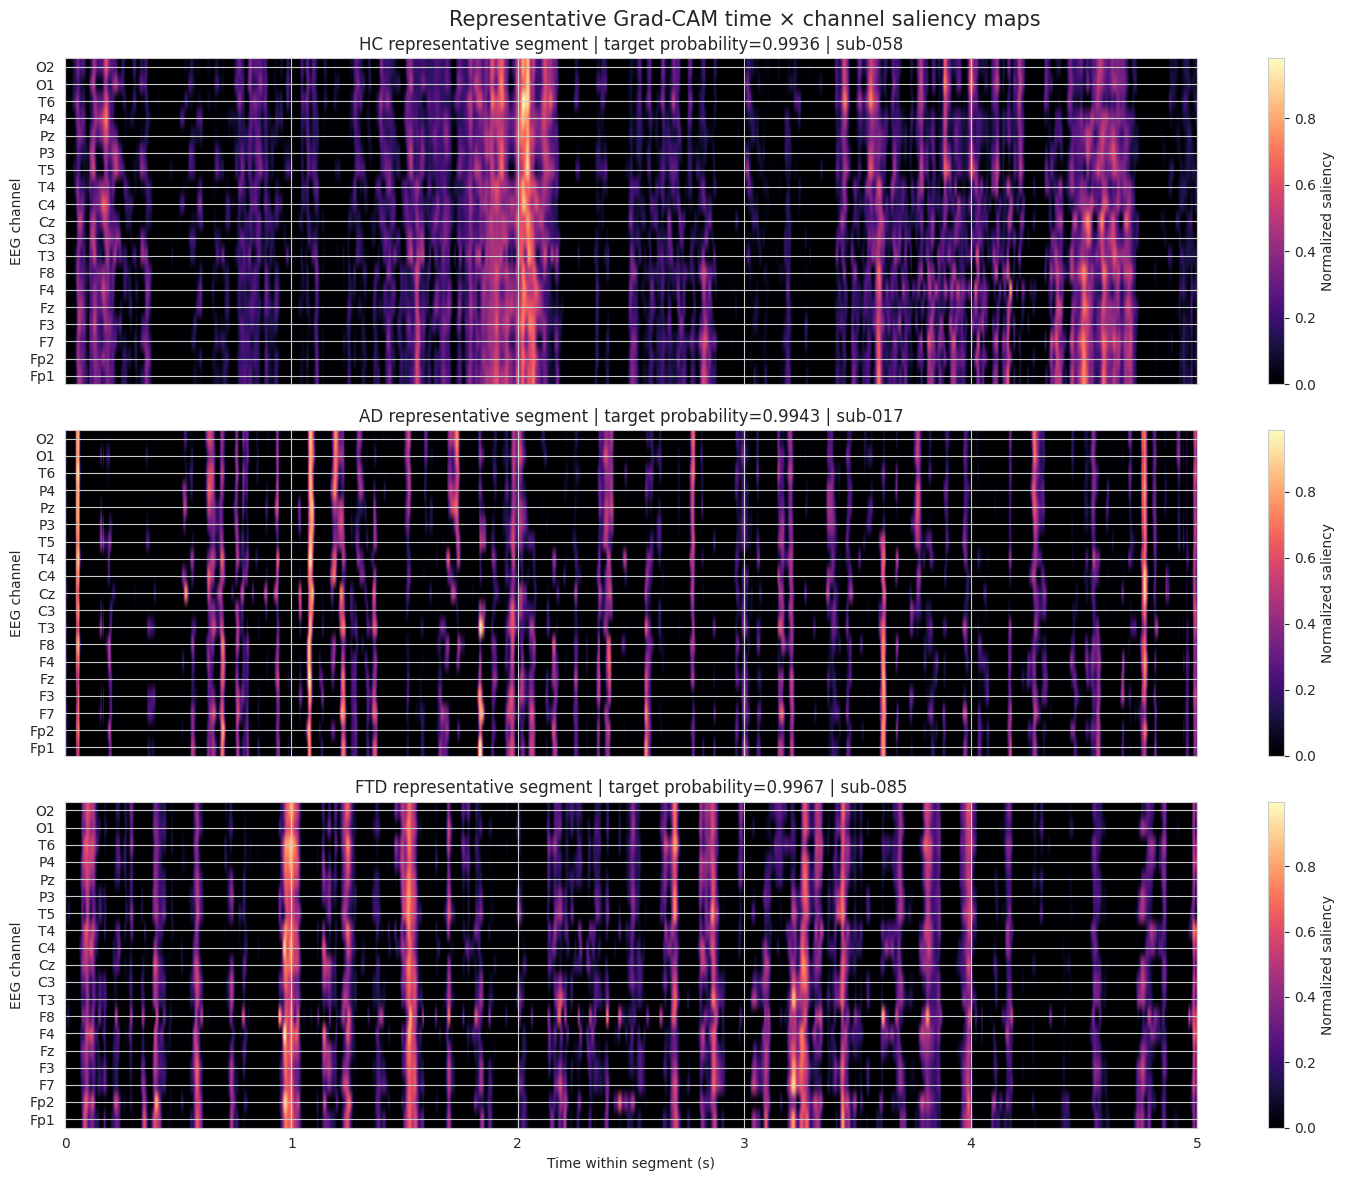

In [18]:
# ============================================================
# EXPLAINABILITY STEP 2E
# Representative time × channel saliency maps
#
# A representative example is selected near the median
# prediction confidence for each class.
# ============================================================

def calculate_single_segment_cam(
    segment_row,
    target_label
):
    single_row_df = pd.DataFrame(
        [
            segment_row
        ]
    ).reset_index(drop=True)

    single_sequence = EEGMultiInputSequence(
        dataframe=single_row_df,
        welch_path=STANDARDIZED_WELCH_PATH,
        biomarker_path=STANDARDIZED_BIOMARKER_PATH,
        batch_size=1,
        shuffle=False,
        seed=MODEL_SEED,
    )

    (
        single_inputs,
        _
    ) = single_sequence[0]

    (
        single_cam,
        single_probability
    ) = calculate_temporal_channel_gradcam(
        {
            key: tf.convert_to_tensor(
                value,
                dtype=tf.float32
            )
            for key, value
            in single_inputs.items()
        },
        tf.convert_to_tensor(
            [
                target_label
            ],
            dtype=tf.int32
        )
    )

    return (
        single_cam.numpy()[0],
        float(
            single_probability
            .numpy()[0]
        )
    )


representative_rows = []

for class_label, class_name in enumerate(
    CLASS_NAMES
):

    class_correct_df = (
        saliency_test_df[
            (
                saliency_test_df[
                    "label"
                ]
                == class_label
            )
            &
            saliency_test_df[
                "correct"
            ]
        ]
        .copy()
    )

    median_confidence = float(
        class_correct_df[
            "confidence"
        ].median()
    )

    class_correct_df[
        "distance_from_median_confidence"
    ] = np.abs(
        class_correct_df[
            "confidence"
        ]
        - median_confidence
    )

    representative_row = (
        class_correct_df
        .sort_values(
            "distance_from_median_confidence"
        )
        .iloc[0]
    )

    representative_rows.append(
        representative_row
    )


fig, axes = plt.subplots(
    3,
    1,
    figsize=(15, 12),
    sharex=True
)

for axis, representative_row in zip(
    axes,
    representative_rows
):

    class_label = int(
        representative_row[
            "label"
        ]
    )

    class_name = CLASS_NAMES[
        class_label
    ]

    representative_cam, target_probability = (
        calculate_single_segment_cam(
            representative_row,
            target_label=class_label
        )
    )

    # Transpose to:
    # channel × time
    display_cam = representative_cam.T

    image = axis.imshow(
        display_cam,
        aspect="auto",
        origin="lower",
        extent=[
            0,
            WINDOW_SECONDS,
            0,
            N_CHANNELS
        ],
        cmap="magma"
    )

    axis.set_yticks(
        np.arange(
            N_CHANNELS
        )
        + 0.5
    )

    axis.set_yticklabels(
        TARGET_CHANNELS
    )

    axis.set_ylabel(
        "EEG channel"
    )

    axis.set_title(
        f"{class_name} representative segment | "
        f"target probability={target_probability:.4f} | "
        f"{representative_row['participant_id']}"
    )

    fig.colorbar(
        image,
        ax=axis,
        label="Normalized saliency"
    )


axes[-1].set_xlabel(
    "Time within segment (s)"
)

fig.suptitle(
    "Representative Grad-CAM time × channel saliency maps",
    fontsize=15
)

plt.tight_layout()

REPRESENTATIVE_CAM_PATH = (
    SALIENCY_DIR
    / "representative_time_channel_gradcam.png"
)

plt.savefig(
    REPRESENTATIVE_CAM_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Misclassified test segments: 38
Processed 10/38 errors
Processed 20/38 errors
Processed 30/38 errors

Error saliency comparison:


,channel,predicted_target_mean,true_target_mean,predicted_minus_true
8,C3,0.050986,0.049488,0.001498
3,F3,0.052323,0.050865,0.001459
5,F4,0.052725,0.051283,0.001442
4,Fz,0.051511,0.050343,0.001169
10,C4,0.050476,0.049337,0.001139
1,Fp2,0.051807,0.050780,0.001027
0,Fp1,0.051446,0.050701,0.000745
9,Cz,0.049579,0.048873,0.000706
13,P3,0.052814,0.052306,0.000508
15,P4,0.051436,0.051646,-0.000210


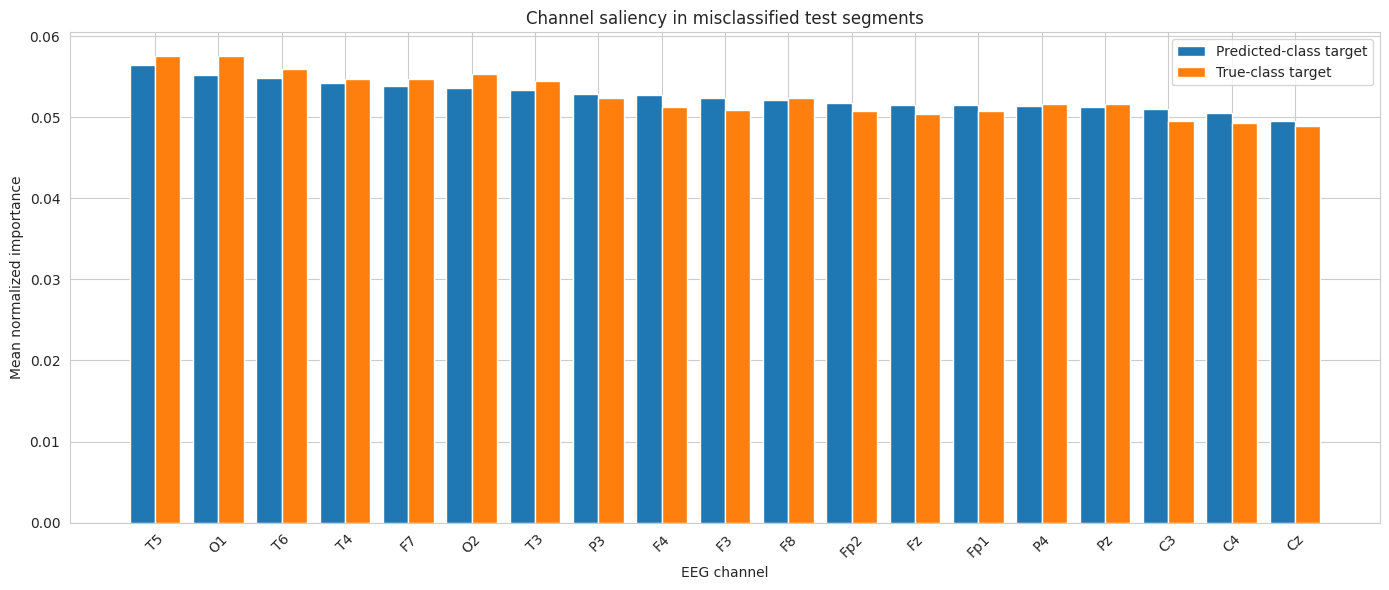

In [19]:
# ============================================================
# EXPLAINABILITY STEP 2F
# Misclassification saliency audit
# ============================================================

error_df = (
    saliency_test_df[
        ~saliency_test_df[
            "correct"
        ]
    ]
    .copy()
    .sort_values(
        "confidence",
        ascending=False
    )
    .reset_index(drop=True)
)

print(
    "Misclassified test segments:",
    len(error_df)
)

assert len(error_df) == 38


error_predicted_channel_rows = []
error_true_channel_rows = []


for error_index, error_row in (
    error_df.iterrows()
):

    true_label = int(
        error_row[
            "label"
        ]
    )

    predicted_label = int(
        error_row[
            "predicted_label"
        ]
    )

    (
        predicted_target_cam,
        predicted_target_probability
    ) = calculate_single_segment_cam(
        error_row,
        target_label=predicted_label
    )

    (
        true_target_cam,
        true_target_probability
    ) = calculate_single_segment_cam(
        error_row,
        target_label=true_label
    )

    predicted_channel_importance = np.mean(
        predicted_target_cam,
        axis=0
    )

    true_channel_importance = np.mean(
        true_target_cam,
        axis=0
    )

    predicted_channel_importance = (
        predicted_channel_importance
        / (
            np.sum(
                predicted_channel_importance
            )
            + SALIENCY_EPSILON
        )
    )

    true_channel_importance = (
        true_channel_importance
        / (
            np.sum(
                true_channel_importance
            )
            + SALIENCY_EPSILON
        )
    )

    predicted_row = {
        "participant_id": error_row[
            "participant_id"
        ],
        "segment_uid": error_row[
            "segment_uid"
        ],
        "true_class": CLASS_NAMES[
            true_label
        ],
        "predicted_class": CLASS_NAMES[
            predicted_label
        ],
        "prediction_confidence": float(
            error_row[
                "confidence"
            ]
        ),
        "gradcam_target_probability": (
            predicted_target_probability
        ),
    }

    true_row = {
        "participant_id": error_row[
            "participant_id"
        ],
        "segment_uid": error_row[
            "segment_uid"
        ],
        "true_class": CLASS_NAMES[
            true_label
        ],
        "predicted_class": CLASS_NAMES[
            predicted_label
        ],
        "prediction_confidence": float(
            error_row[
                "confidence"
            ]
        ),
        "gradcam_target_probability": (
            true_target_probability
        ),
    }

    for channel_index, channel_name in enumerate(
        TARGET_CHANNELS
    ):

        predicted_row[
            f"importance_{channel_name}"
        ] = float(
            predicted_channel_importance[
                channel_index
            ]
        )

        true_row[
            f"importance_{channel_name}"
        ] = float(
            true_channel_importance[
                channel_index
            ]
        )

    error_predicted_channel_rows.append(
        predicted_row
    )

    error_true_channel_rows.append(
        true_row
    )

    if (
        error_index + 1
    ) % 10 == 0:
        print(
            f"Processed "
            f"{error_index + 1}/"
            f"{len(error_df)} errors"
        )


error_predicted_channel_df = pd.DataFrame(
    error_predicted_channel_rows
)

error_true_channel_df = pd.DataFrame(
    error_true_channel_rows
)


# ------------------------------------------------------------
# Aggregate error-channel importance
# ------------------------------------------------------------

importance_columns = [
    f"importance_{channel}"
    for channel in TARGET_CHANNELS
]

error_comparison_df = pd.DataFrame({
    "channel": TARGET_CHANNELS,
    "predicted_target_mean": (
        error_predicted_channel_df[
            importance_columns
        ]
        .mean(
            axis=0
        )
        .to_numpy()
    ),
    "true_target_mean": (
        error_true_channel_df[
            importance_columns
        ]
        .mean(
            axis=0
        )
        .to_numpy()
    ),
})

error_comparison_df[
    "predicted_minus_true"
] = (
    error_comparison_df[
        "predicted_target_mean"
    ]
    -
    error_comparison_df[
        "true_target_mean"
    ]
)

print(
    "\nError saliency comparison:"
)

display(
    error_comparison_df
    .sort_values(
        "predicted_minus_true",
        ascending=False
    )
)


# ------------------------------------------------------------
# Plot predicted-target versus true-target channel importance
# ------------------------------------------------------------

error_plot_df = (
    error_comparison_df
    .sort_values(
        "predicted_target_mean",
        ascending=False
    )
)

x_positions = np.arange(
    N_CHANNELS
)

bar_width = 0.40

plt.figure(
    figsize=(14, 6)
)

plt.bar(
    x_positions
    - bar_width / 2,
    error_plot_df[
        "predicted_target_mean"
    ],
    width=bar_width,
    label="Predicted-class target"
)

plt.bar(
    x_positions
    + bar_width / 2,
    error_plot_df[
        "true_target_mean"
    ],
    width=bar_width,
    label="True-class target"
)

plt.xticks(
    x_positions,
    error_plot_df[
        "channel"
    ],
    rotation=45
)

plt.xlabel(
    "EEG channel"
)

plt.ylabel(
    "Mean normalized importance"
)

plt.title(
    "Channel saliency in misclassified test segments"
)

plt.legend()
plt.tight_layout()

ERROR_CHANNEL_FIGURE_PATH = (
    SALIENCY_DIR
    / "misclassification_channel_saliency.png"
)

plt.savefig(
    ERROR_CHANNEL_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [20]:
# ============================================================
# EXPLAINABILITY STEP 2G
# Save Grad-CAM saliency outputs
# ============================================================

np.save(
    SALIENCY_DIR
    / "correct_segment_channel_importance.npy",
    channel_importance_array
)

np.save(
    SALIENCY_DIR
    / "correct_segment_temporal_importance.npy",
    temporal_importance_array
)

segment_channel_importance_df.to_csv(
    SALIENCY_DIR
    / "correct_segment_channel_importance.csv",
    index=False
)

class_channel_importance_df.to_csv(
    SALIENCY_DIR
    / "class_channel_importance_summary.csv",
    index=False
)

global_channel_importance_df.to_csv(
    SALIENCY_DIR
    / "global_channel_importance_summary.csv",
    index=False
)

error_predicted_channel_df.to_csv(
    SALIENCY_DIR
    / "error_predicted_target_channel_importance.csv",
    index=False
)

error_true_channel_df.to_csv(
    SALIENCY_DIR
    / "error_true_target_channel_importance.csv",
    index=False
)

error_comparison_df.to_csv(
    SALIENCY_DIR
    / "error_channel_importance_comparison.csv",
    index=False
)


saliency_configuration = {
    "target_layer": SALIENCY_LAYER_NAME,
    "target_layer_shape": [
        None,
        WINDOW_SAMPLES,
        N_CHANNELS,
        96
    ],
    "saliency_batch_size": SALIENCY_BATCH_SIZE,
    "maximum_correct_segments_per_class": (
        MAX_CORRECT_SEGMENTS_PER_CLASS
    ),
    "correct_segments_analysed": int(
        len(
            selected_correct_df
        )
    ),
    "misclassified_segments_analysed": int(
        len(
            error_df
        )
    ),
    "random_seed": int(
        SALIENCY_RANDOM_SEED
    ),
    "channel_importance_definition": (
        "mean positive Grad-CAM saliency over time, "
        "normalized to sum to one per segment"
    ),
    "temporal_importance_definition": (
        "mean positive Grad-CAM saliency over EEG channels"
    ),
}

with open(
    SALIENCY_DIR
    / "saliency_configuration.json",
    "w"
) as file:
    json.dump(
        saliency_configuration,
        file,
        indent=2
    )


print(
    "All Grad-CAM saliency results saved in:"
)

print(
    SALIENCY_DIR
)

gc.collect()

All Grad-CAM saliency results saved in:
/kaggle/working/eeg_multiclass_final/runs/corrected_multibranch_seed_42/explainability/gradcam_channel_saliency


14006

### STEP 3A: Generate 10-fold cross-validation predictions

To address the `FileNotFoundError` and enable subsequent statistical reliability analysis, we need to generate out-of-fold (OOF) predictions. This involves training the model 10 times, each time holding out a different fold as the validation set. The predictions from these held-out folds are then combined to form the complete set of OOF predictions.

This process ensures that each segment receives a prediction from a model that was not trained on that specific segment, providing a robust estimate of generalization performance. The OOF predictions will be saved to the path expected by the next steps in the notebook.

In [21]:
from sklearn.model_selection import KFold
import gc
import json
from pathlib import Path

# ============================================================
# FIXED: Define missing Kaggle directory paths at the top
# ============================================================
CV_ROOT = Path("/kaggle/working/eeg_multiclass_final/cross_validation")
CV_ROOT.mkdir(parents=True, exist_ok=True)

# Ensure OOF_PREDICTIONS_PATH is also explicitly set inside CV_ROOT
OOF_PREDICTIONS_PATH = CV_ROOT / "oof_predictions.csv"

# Define the number of splits for cross-validation
N_SPLITS = 10

# Define the root directory for cross-validation runs
CV_RUNS_ROOT = CV_ROOT / "runs"
CV_RUNS_ROOT.mkdir(parents=True, exist_ok=True)

# Prepare to collect out-of-fold predictions
all_oof_predictions = []

kf = KFold(n_splits=N_SPLITS, shuffle=True, random_state=MODEL_SEED)

for fold_idx, (train_indices_kf, validation_indices_kf) in enumerate(kf.split(feature_metadata_df)):
    print(f"\n{'='*30}\nProcessing Fold {fold_idx + 1}/{N_SPLITS}\n{'='*30}")

    # Create dataframes for the current fold
    train_df_fold = feature_metadata_df.iloc[train_indices_kf].copy().reset_index(drop=True)
    validation_df_fold = feature_metadata_df.iloc[validation_indices_kf].copy().reset_index(drop=True)

    # Create data sequences for the current fold
    train_sequence_fold = EEGMultiInputSequence(
        train_df_fold,
        STANDARDIZED_WELCH_PATH,
        STANDARDIZED_BIOMARKER_PATH,
        BATCH_SIZE,
        shuffle=True,
        seed=MODEL_SEED,
    )
    validation_sequence_fold = EEGMultiInputSequence(
        validation_df_fold,
        STANDARDIZED_WELCH_PATH,
        STANDARDIZED_BIOMARKER_PATH,
        BATCH_SIZE,
        shuffle=False,
        seed=MODEL_SEED,
    )

    # Clear previous model and session for a fresh start
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(MODEL_SEED)

    # Build and compile the model for the current fold
    model_fold = build_model()
    steps_per_epoch_fold = math.ceil(len(train_df_fold) / BATCH_SIZE)
    schedule_fold = WarmupCosineDecay(
        peak_lr=PEAK_LEARNING_RATE,
        min_lr=MIN_LEARNING_RATE,
        warmup_steps=steps_per_epoch_fold * WARMUP_EPOCHS,
        total_steps=steps_per_epoch_fold * MAX_EPOCHS,
    )
    model_fold.compile(
        optimizer=tf.keras.optimizers.AdamW(
            learning_rate=schedule_fold,
            weight_decay=WEIGHT_DECAY,
            clipnorm=GRADIENT_CLIP_NORM,
        ),
        loss=SparseLabelSmoothedCrossentropy(
            num_classes=N_CLASSES,
            label_smoothing=LABEL_SMOOTHING,
        ),
        metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
    )

    # Define fold-specific run directory and checkpoint path
    fold_run_dir = CV_RUNS_ROOT / f"fold_{fold_idx:02d}"
    fold_run_dir.mkdir(parents=True, exist_ok=True)
    
    # FIXED Hidden Bug 3: Swapped to .keras format to stay consistent with modern Keras 3 saving
    fold_best_weights_path = fold_run_dir / "best_validation_macro_f1.keras"
    fold_history_path = fold_run_dir / "training_history.csv"

    # Define callbacks for the current fold
    validation_labels_fold = validation_df_fold["label"].to_numpy(dtype=np.int32)
    validation_callback_fold = ValidationMetrics(validation_sequence_fold, validation_labels_fold)
    checkpoint_callback_fold = BestCheckpoint(fold_best_weights_path)

    # Train the model
    history_fold = model_fold.fit(
        train_sequence_fold,
        validation_data=validation_sequence_fold,
        epochs=MAX_EPOCHS,
        callbacks=[
            TerminateOnNaN(),
            validation_callback_fold,
            checkpoint_callback_fold,
            EarlyStopping(
                monitor="val_macro_f1",
                mode="max",
                min_delta=0.001,
                patience=10,
                restore_best_weights=False,
                verbose=1,
            ),
            CSVLogger(str(fold_run_dir / "keras_log.csv"), append=False),
        ],
        verbose=1,
    )

    # Load best weights and make predictions on the validation set for OOF
    if fold_best_weights_path.exists():
        # FIXED: Use full model load method to read your modern checkpoint format seamlessly
        model_fold = tf.keras.models.load_model(fold_best_weights_path, custom_objects={
            'SparseLabelSmoothedCrossentropy': SparseLabelSmoothedCrossentropy,
            'ChannelSegmentZScoreClip': ChannelSegmentZScoreClip
        })
        fold_probabilities = model_fold.predict(validation_sequence_fold, verbose=0)

        # Store OOF predictions for the current fold
        fold_oof_df = validation_df_fold[[
            "segment_uid", "participant_id", "group", "label"
        ]].copy()
        fold_oof_df["fold"] = fold_idx
        fold_oof_df["true_label"] = fold_oof_df["label"]
        fold_oof_df["prob_HC"] = fold_probabilities[:, 0]
        fold_oof_df["prob_AD"] = fold_probabilities[:, 1]
        fold_oof_df["prob_FTD"] = fold_probabilities[:, 2]
        fold_oof_df["predicted_label"] = np.argmax(fold_probabilities, axis=1)
        all_oof_predictions.append(fold_oof_df)
    else:
        print(f"Warning: No best weights saved for fold {fold_idx + 1}.")

    # Clean up for the next fold
    del model_fold, train_sequence_fold, validation_sequence_fold
    gc.collect()

# Concatenate all OOF predictions
oof_predictions_df = pd.concat(all_oof_predictions, ignore_index=True)

# Sort by segment_uid to ensure consistent order
oof_predictions_df = oof_predictions_df.sort_values(by="segment_uid").reset_index(drop=True)

# Save the OOF predictions to CSV
oof_predictions_df.to_csv(OOF_PREDICTIONS_PATH, index=False)

print(f"\n{'='*30}\n10-Fold Cross-Validation Completed.\n{'='*30}")
print(f"OOF predictions saved to: {OOF_PREDICTIONS_PATH}")
print("First 5 rows of OOF predictions:")
display(oof_predictions_df.head())



Processing Fold 1/10
Epoch 1/50


E0000 00:00:1781588867.177276      23 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1/spatial_dropout2d_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


374/374 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step - accuracy: 0.3681 - loss: 1.4913
val_macro_f1=0.5280 | val_balanced=0.5469 | recall HC/AD/FTD=0.7732/0.7009/0.1667 | lr=0.00006667
Saved best checkpoint at epoch 1: F1=0.527958, acc=0.600752, loss=0.886975
374/374 ━━━━━━━━━━━━━━━━━━━━ 84s 181ms/step - accuracy: 0.4026 - loss: 1.3536 - val_accuracy: 0.6008 - val_loss: 0.8870 - val_macro_f1: 0.5280 - val_balanced_accuracy: 0.5469 - val_recall_HC: 0.7732 - val_recall_AD: 0.7009 - val_recall_FTD: 0.1667 - learning_rate: 6.6667e-05
Epoch 2/50
374/374 ━━━━━━━━━━━━━━━━━━━━ 0s 163ms/step - accuracy: 0.5303 - loss: 1.0084
val_macro_f1=0.6354 | val_balanced=0.6349 | recall HC/AD/FTD=0.7991/0.7369/0.3686 | lr=0.00013333
Saved best checkpoint at epoch 2: F1=0.635408, acc=0.672180, loss=0.743873
374/374 ━━━━━━━━━━━━━━━━━━━━ 67s 178ms/step - accuracy: 0.5647 - loss: 0.9540 - val_accuracy: 0.6722 - val_loss: 0.7439 - val_macro_f1: 0.6354 - val_balanced_accuracy: 0.6349 - val_recall_HC: 0.7991 - val_recall_A

E0000 00:00:1781591311.361116      23 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1/spatial_dropout2d_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


374/374 ━━━━━━━━━━━━━━━━━━━━ 0s 164ms/step - accuracy: 0.3677 - loss: 1.5071
val_macro_f1=0.5289 | val_balanced=0.5501 | recall HC/AD/FTD=0.7838/0.6920/0.1745 | lr=0.00006667
Saved best checkpoint at epoch 1: F1=0.528916, acc=0.597744, loss=0.919133
374/374 ━━━━━━━━━━━━━━━━━━━━ 84s 184ms/step - accuracy: 0.4055 - loss: 1.3565 - val_accuracy: 0.5977 - val_loss: 0.9191 - val_macro_f1: 0.5289 - val_balanced_accuracy: 0.5501 - val_recall_HC: 0.7838 - val_recall_AD: 0.6920 - val_recall_FTD: 0.1745 - learning_rate: 6.6667e-05
Epoch 2/50
374/374 ━━━━━━━━━━━━━━━━━━━━ 0s 165ms/step - accuracy: 0.5384 - loss: 1.0086
val_macro_f1=0.6083 | val_balanced=0.6121 | recall HC/AD/FTD=0.7793/0.7487/0.3084 | lr=0.00013333
Saved best checkpoint at epoch 2: F1=0.608259, acc=0.652632, loss=0.791746
374/374 ━━━━━━━━━━━━━━━━━━━━ 67s 180ms/step - accuracy: 0.5662 - loss: 0.9570 - val_accuracy: 0.6526 - val_loss: 0.7917 - val_macro_f1: 0.6083 - val_balanced_accuracy: 0.6121 - val_recall_HC: 0.7793 - val_recall_A

E0000 00:00:1781594361.265595      23 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1/spatial_dropout2d_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


... (12 outputs left out)

374/374 ━━━━━━━━━━━━━━━━━━━━ 0s 165ms/step - accuracy: 0.3762 - loss: 1.4887
val_macro_f1=0.5320 | val_balanced=0.5549 | recall HC/AD/FTD=0.6908/0.8216/0.1522 | lr=0.00006667
Saved best checkpoint at epoch 1: F1=0.532035, acc=0.607976, loss=0.876710
374/374 ━━━━━━━━━━━━━━━━━━━━ 85s 185ms/step - accuracy: 0.4149 - loss: 1.3380 - val_accuracy: 0.6080 - val_loss: 0.8767 - val_macro_f1: 0.5320 - val_balanced_accuracy: 0.5549 - val_recall_HC: 0.6908 - val_recall_AD: 0.8216 - val_recall_FTD: 0.1522 - learning_rate: 6.6667e-05
Epoch 2/50
374/374 ━━━━━━━━━━━━━━━━━━━━ 0s 166ms/step - accuracy: 0.5320 - loss: 1.0183
val_macro_f1=0.6450 | val_balanced=0.6422 | recall HC/AD/FTD=0.7368/0.8197/0.3701 | lr=0.00013333
Saved best checkpoint at epoch 2: F1=0.644958, acc=0.677953, loss=0.745638
374/374 ━━━━━━━━━━━━━━━━━━━━ 67s 180ms/step - accuracy: 0.5612 - loss: 0.9603 - val_accuracy: 0.6780 - val_loss: 0.7456 - val_macro_f1: 0.6450 - val_balanced_accuracy: 0.6422 - val_recall_HC: 0.7368 - val_recall_A

E0000 00:00:1781614270.591700      23 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1/spatial_dropout2d_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


374/374 ━━━━━━━━━━━━━━━━━━━━ 0s 164ms/step - accuracy: 0.3717 - loss: 1.5005
val_macro_f1=0.5155 | val_balanced=0.5523 | recall HC/AD/FTD=0.7610/0.7907/0.1051 | lr=0.00006667
Saved best checkpoint at epoch 1: F1=0.515458, acc=0.608728, loss=0.893439
374/374 ━━━━━━━━━━━━━━━━━━━━ 85s 185ms/step - accuracy: 0.4109 - loss: 1.3467 - val_accuracy: 0.6087 - val_loss: 0.8934 - val_macro_f1: 0.5155 - val_balanced_accuracy: 0.5523 - val_recall_HC: 0.7610 - val_recall_AD: 0.7907 - val_recall_FTD: 0.1051 - learning_rate: 6.6667e-05
Epoch 2/50
374/374 ━━━━━━━━━━━━━━━━━━━━ 0s 167ms/step - accuracy: 0.5296 - loss: 1.0048
val_macro_f1=0.6546 | val_balanced=0.6528 | recall HC/AD/FTD=0.7939/0.7500/0.4144 | lr=0.00013333
Saved best checkpoint at epoch 2: F1=0.654611, acc=0.680963, loss=0.733604
374/374 ━━━━━━━━━━━━━━━━━━━━ 68s 181ms/step - accuracy: 0.5639 - loss: 0.9499 - val_accuracy: 0.6810 - val_loss: 0.7336 - val_macro_f1: 0.6546 - val_balanced_accuracy: 0.6528 - val_recall_HC: 0.7939 - val_recall_A

,segment_uid,participant_id,group,label,fold,true_label,prob_HC,prob_AD,prob_FTD,predicted_label
0,sub-001__clean_0000,sub-001,AD,1,1,1,0.003853,0.994244,0.001903,1
1,sub-001__clean_0001,sub-001,AD,1,8,1,0.002967,0.994630,0.002403,1
2,sub-001__clean_0002,sub-001,AD,1,6,1,0.002766,0.993513,0.003722,1
3,sub-001__clean_0003,sub-001,AD,1,2,1,0.004523,0.986636,0.008841,1
4,sub-001__clean_0004,sub-001,AD,1,9,1,0.002703,0.993185,0.004112,1


In [22]:
# ============================================================
# STEP 3A
# LOAD AND VERIFY 10-FOLD OUT-OF-FOLD PREDICTIONS
# ============================================================

import json
import math
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

CLASS_NAMES = ["HC", "AD", "FTD"]
N_CLASSES = 3

CV_ROOT = Path(
    "/kaggle/working/eeg_multiclass_final/cross_validation"
)

CV_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

OOF_PREDICTIONS_PATH = (
    CV_ROOT
    / "oof_predictions.csv"
)

RELIABILITY_ROOT = (
    CV_ROOT
    / "statistical_reliability"
)

RELIABILITY_ROOT.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# Load OOF predictions
# ------------------------------------------------------------

if "oof_predictions_df" in globals():

    oof_predictions_df = (
        oof_predictions_df
        .copy()
        .reset_index(drop=True)
    )

elif OOF_PREDICTIONS_PATH.exists():

    oof_predictions_df = pd.read_csv(
        OOF_PREDICTIONS_PATH
    )

else:

    raise FileNotFoundError(
        "Out-of-fold predictions were not found.\n\n"
        "Expected either:\n"
        "1. oof_predictions_df in memory, or\n"
        f"2. {OOF_PREDICTIONS_PATH}"
    )


# ------------------------------------------------------------
# Support common alternative column names
# ------------------------------------------------------------

column_aliases = {
    "label": "true_label",
    "y_true": "true_label",
    "y_pred": "predicted_label",
    "fold_id": "fold",
}

for old_name, new_name in column_aliases.items():

    if (
        old_name in oof_predictions_df.columns
        and new_name not in oof_predictions_df.columns
    ):
        oof_predictions_df = (
            oof_predictions_df.rename(
                columns={
                    old_name: new_name
                }
            )
        )


required_columns = {
    "fold",
    "true_label",
    "prob_HC",
    "prob_AD",
    "prob_FTD",
}

missing_columns = (
    required_columns
    - set(oof_predictions_df.columns)
)

if missing_columns:

    raise RuntimeError(
        "OOF predictions are missing columns: "
        f"{sorted(missing_columns)}"
    )


# ------------------------------------------------------------
# Standardize types
# ------------------------------------------------------------

oof_predictions_df["fold"] = (
    oof_predictions_df["fold"]
    .astype(int)
)

oof_predictions_df["true_label"] = (
    oof_predictions_df["true_label"]
    .astype(int)
)

probability_columns = [
    "prob_HC",
    "prob_AD",
    "prob_FTD",
]

oof_probabilities = (
    oof_predictions_df[
        probability_columns
    ]
    .to_numpy(
        dtype=np.float64
    )
)

oof_true_labels = (
    oof_predictions_df[
        "true_label"
    ]
    .to_numpy(
        dtype=np.int32
    )
)


# ------------------------------------------------------------
# Validate probabilities
# ------------------------------------------------------------

if not np.isfinite(
    oof_probabilities
).all():

    raise RuntimeError(
        "OOF probabilities contain NaN or Inf."
    )

if (
    np.min(oof_probabilities) < -1e-6
    or np.max(oof_probabilities) > 1.0 + 1e-6
):

    raise RuntimeError(
        "OOF probabilities fall outside [0, 1]."
    )

oof_probabilities = np.clip(
    oof_probabilities,
    0.0,
    1.0
)

probability_sums = np.sum(
    oof_probabilities,
    axis=1
)

if not np.allclose(
    probability_sums,
    1.0,
    atol=1e-4
):

    if np.any(
        probability_sums <= 0
    ):
        raise RuntimeError(
            "At least one probability row has a "
            "non-positive total."
        )

    print(
        "Small probability-sum differences detected; "
        "rows are being renormalized."
    )

    oof_probabilities = (
        oof_probabilities
        / probability_sums[:, None]
    )

    oof_predictions_df[
        probability_columns
    ] = oof_probabilities


# ------------------------------------------------------------
# Derive predictions from probabilities
# ------------------------------------------------------------

derived_predictions = np.argmax(
    oof_probabilities,
    axis=1
).astype(np.int32)

if (
    "predicted_label"
    in oof_predictions_df.columns
):

    supplied_predictions = (
        oof_predictions_df[
            "predicted_label"
        ]
        .to_numpy(
            dtype=np.int32
        )
    )

    mismatch_count = int(
        np.sum(
            supplied_predictions
            != derived_predictions
        )
    )

    if mismatch_count > 0:

        print(
            f"Warning: {mismatch_count} supplied predictions "
            "differ from probability argmax. "
            "Probability argmax will be used."
        )

oof_predictions_df[
    "predicted_label"
] = derived_predictions


# ------------------------------------------------------------
# Verify 10 folds
# ------------------------------------------------------------

fold_values = np.sort(
    oof_predictions_df[
        "fold"
    ].unique()
)

assert len(fold_values) == 10, (
    f"Expected exactly 10 folds, found "
    f"{len(fold_values)}: {fold_values}"
)

assert set(
    np.unique(
        oof_true_labels
    )
) == {0, 1, 2}


# Every segment should appear once in OOF predictions.
if "segment_uid" in oof_predictions_df.columns:

    duplicate_segment_count = int(
        oof_predictions_df[
            "segment_uid"
        ]
        .duplicated()
        .sum()
    )

    assert duplicate_segment_count == 0, (
        f"Found {duplicate_segment_count} duplicate "
        "OOF segment IDs."
    )


print("OOF prediction rows:", len(oof_predictions_df))
print("Folds:", fold_values)

print("\nFold sizes:")

display(
    oof_predictions_df[
        "fold"
    ]
    .value_counts()
    .sort_index()
    .rename("segments")
    .to_frame()
)

print("\nClass counts:")

display(
    oof_predictions_df[
        "true_label"
    ]
    .map(
        dict(
            enumerate(
                CLASS_NAMES
            )
        )
    )
    .value_counts()
    .reindex(
        CLASS_NAMES
    )
    .rename("segments")
    .to_frame()
)

OOF prediction rows: 13293
Folds: [0 1 2 3 4 5 6 7 8 9]

Fold sizes:


,segments
fold,
0,1330
1,1330
2,1330
3,1329
4,1329
5,1329
6,1329
7,1329
8,1329



Class counts:


,segments
true_label,
HC,4572
AD,5553
FTD,3168


In [23]:
# ============================================================
# STEP 3B
# CALCULATE FOLD-WISE PERFORMANCE
# ============================================================

def safe_divide(
    numerator,
    denominator
):
    if denominator == 0:
        return np.nan

    return float(
        numerator / denominator
    )


def calculate_fold_metrics(
    fold_frame
):
    true_labels = (
        fold_frame[
            "true_label"
        ]
        .to_numpy(
            dtype=np.int32
        )
    )

    probabilities = (
        fold_frame[
            probability_columns
        ]
        .to_numpy(
            dtype=np.float64
        )
    )

    predictions = np.argmax(
        probabilities,
        axis=1
    ).astype(np.int32)

    confusion = confusion_matrix(
        true_labels,
        predictions,
        labels=[0, 1, 2]
    )

    class_rows = []

    class_sensitivities = []
    class_specificities = []
    class_f1_scores = []
    class_auc_scores = []

    total_samples = int(
        np.sum(
            confusion
        )
    )

    for class_label, class_name in enumerate(
        CLASS_NAMES
    ):

        true_positive = int(
            confusion[
                class_label,
                class_label
            ]
        )

        false_negative = int(
            np.sum(
                confusion[
                    class_label,
                    :
                ]
            )
            - true_positive
        )

        false_positive = int(
            np.sum(
                confusion[
                    :,
                    class_label
                ]
            )
            - true_positive
        )

        true_negative = int(
            total_samples
            - true_positive
            - false_negative
            - false_positive
        )

        sensitivity = safe_divide(
            true_positive,
            true_positive
            + false_negative
        )

        specificity = safe_divide(
            true_negative,
            true_negative
            + false_positive
        )

        binary_true = (
            true_labels
            == class_label
        ).astype(int)

        binary_prediction = (
            predictions
            == class_label
        ).astype(int)

        class_f1 = f1_score(
            binary_true,
            binary_prediction,
            zero_division=0
        )

        if (
            np.unique(
                binary_true
            ).size
            == 2
        ):
            class_auc = roc_auc_score(
                binary_true,
                probabilities[
                    :,
                    class_label
                ]
            )
        else:
            class_auc = np.nan

        support = int(
            true_positive
            + false_negative
        )

        class_sensitivities.append(
            sensitivity
        )

        class_specificities.append(
            specificity
        )

        class_f1_scores.append(
            class_f1
        )

        class_auc_scores.append(
            class_auc
        )

        class_rows.append({
            "class_label": class_label,
            "class_name": class_name,
            "support": support,

            "true_positive": true_positive,
            "false_negative": false_negative,
            "false_positive": false_positive,
            "true_negative": true_negative,

            "sensitivity": sensitivity,
            "specificity": specificity,
            "f1": float(
                class_f1
            ),
            "auc_ovr": float(
                class_auc
            ),
        })


    try:
        macro_auc = roc_auc_score(
            true_labels,
            probabilities,
            labels=[0, 1, 2],
            multi_class="ovr",
            average="macro"
        )
    except ValueError:
        macro_auc = np.nan


    overall_row = {
        "segments": len(
            fold_frame
        ),

        "errors": int(
            np.sum(
                predictions
                != true_labels
            )
        ),

        "accuracy": accuracy_score(
            true_labels,
            predictions
        ),

        "balanced_accuracy": (
            balanced_accuracy_score(
                true_labels,
                predictions
            )
        ),

        "macro_sensitivity": float(
            np.nanmean(
                class_sensitivities
            )
        ),

        "macro_specificity": float(
            np.nanmean(
                class_specificities
            )
        ),

        "macro_f1": f1_score(
            true_labels,
            predictions,
            average="macro",
            zero_division=0
        ),

        "weighted_f1": f1_score(
            true_labels,
            predictions,
            average="weighted",
            zero_division=0
        ),

        "macro_auc_ovr": float(
            macro_auc
        ),
    }

    return (
        overall_row,
        class_rows,
        confusion
    )


fold_overall_rows = []
fold_class_rows = []
fold_confusion_matrices = {}


for fold_value in fold_values:

    fold_frame = (
        oof_predictions_df[
            oof_predictions_df[
                "fold"
            ]
            == fold_value
        ]
        .copy()
        .reset_index(drop=True)
    )

    (
        overall_row,
        class_rows,
        fold_confusion
    ) = calculate_fold_metrics(
        fold_frame
    )

    overall_row[
        "fold"
    ] = int(
        fold_value
    )

    fold_overall_rows.append(
        overall_row
    )

    for class_row in class_rows:

        class_row[
            "fold"
        ] = int(
            fold_value
        )

        fold_class_rows.append(
            class_row
        )

    fold_confusion_matrices[
        int(
            fold_value
        )
    ] = fold_confusion


fold_overall_metrics_df = (
    pd.DataFrame(
        fold_overall_rows
    )
    .sort_values(
        "fold"
    )
    .reset_index(drop=True)
)

fold_class_metrics_df = (
    pd.DataFrame(
        fold_class_rows
    )
    .sort_values(
        [
            "fold",
            "class_label"
        ]
    )
    .reset_index(drop=True)
)


print("Fold-wise overall results:")

display(
    fold_overall_metrics_df
)

print("\nFold-wise class results:")

display(
    fold_class_metrics_df
)

Fold-wise overall results:


,segments,errors,accuracy,balanced_accuracy,macro_sensitivity,macro_specificity,macro_f1,weighted_f1,macro_auc_ovr,fold
0,1330,16,0.987970,0.987335,0.987335,0.994008,0.987109,0.987973,0.999641,0
1,1330,10,0.992481,0.992433,0.992433,0.996137,0.992353,0.992480,0.999614,1
2,1330,14,0.989474,0.990546,0.990546,0.994735,0.989554,0.989468,0.999464,2
3,1329,13,0.990218,0.989515,0.989515,0.994873,0.990033,0.990220,0.999455,3
4,1329,14,0.989466,0.989109,0.989109,0.994688,0.988658,0.989472,0.999762,4
5,1329,17,0.987208,0.987164,0.987164,0.993425,0.986975,0.987210,0.999338,5
6,1329,13,0.990218,0.991334,0.991334,0.995154,0.990154,0.990219,0.999788,6
7,1329,13,0.990218,0.990238,0.990238,0.995008,0.990191,0.990216,0.999690,7
8,1329,12,0.990971,0.990618,0.990618,0.995327,0.990788,0.990976,0.999637,8
9,1329,13,0.990218,0.989176,0.989176,0.994805,0.990001,0.990209,0.998972,9



Fold-wise class results:


,class_label,class_name,support,true_positive,false_negative,false_positive,true_negative,sensitivity,specificity,f1,auc_ovr,fold
0,0,HC,463,457,6,6,861,0.987041,0.993080,0.987041,0.999771,0
1,1,AD,555,550,5,4,771,0.990991,0.994839,0.991885,0.999677,0
2,2,FTD,312,307,5,6,1012,0.983974,0.994106,0.982400,0.999474,0
3,0,HC,444,442,2,3,883,0.995495,0.996614,0.994376,0.999896,1
4,1,AD,565,560,5,4,761,0.991150,0.994771,0.992028,0.999581,1
5,2,FTD,321,318,3,3,1006,0.990654,0.997027,0.990654,0.999364,1
6,0,HC,472,471,1,8,850,0.997881,0.990676,0.990536,0.999420,2
7,1,AD,570,559,11,2,758,0.980702,0.997368,0.988506,0.999324,2
8,2,FTD,288,286,2,4,1038,0.993056,0.996161,0.989619,0.999650,2
9,0,HC,462,457,5,2,865,0.989177,0.997693,0.992400,0.999606,3


In [24]:
# ============================================================
# STEP 3C
# STATISTICAL SUMMARY ACROSS THE 10 FOLDS
# ============================================================

def summarize_fold_values(
    values
):
    values = np.asarray(
        values,
        dtype=np.float64
    )

    values = values[
        np.isfinite(
            values
        )
    ]

    number_of_folds = len(
        values
    )

    if number_of_folds == 0:

        return {
            "folds": 0,
            "mean": np.nan,
            "std": np.nan,
            "sem": np.nan,
            "ci95_lower": np.nan,
            "ci95_upper": np.nan,
            "minimum": np.nan,
            "maximum": np.nan,
            "median": np.nan,
        }

    mean_value = float(
        np.mean(
            values
        )
    )

    if number_of_folds > 1:

        standard_deviation = float(
            np.std(
                values,
                ddof=1
            )
        )

        standard_error = float(
            stats.sem(
                values,
                ddof=1
            )
        )

        critical_value = float(
            stats.t.ppf(
                0.975,
                df=number_of_folds - 1
            )
        )

        confidence_margin = (
            critical_value
            * standard_error
        )

        ci_lower = max(
            0.0,
            mean_value
            - confidence_margin
        )

        ci_upper = min(
            1.0,
            mean_value
            + confidence_margin
        )

    else:

        standard_deviation = np.nan
        standard_error = np.nan
        ci_lower = np.nan
        ci_upper = np.nan


    return {
        "folds": number_of_folds,

        "mean": mean_value,

        "std": standard_deviation,

        "sem": standard_error,

        "ci95_lower": float(
            ci_lower
        ),

        "ci95_upper": float(
            ci_upper
        ),

        "minimum": float(
            np.min(
                values
            )
        ),

        "maximum": float(
            np.max(
                values
            )
        ),

        "median": float(
            np.median(
                values
            )
        ),
    }


overall_metric_names = [
    "accuracy",
    "balanced_accuracy",
    "macro_sensitivity",
    "macro_specificity",
    "macro_f1",
    "weighted_f1",
    "macro_auc_ovr",
]

overall_summary_rows = []

for metric_name in overall_metric_names:

    summary = summarize_fold_values(
        fold_overall_metrics_df[
            metric_name
        ]
    )

    overall_summary_rows.append({
        "metric": metric_name,
        **summary
    })


overall_reliability_summary_df = pd.DataFrame(
    overall_summary_rows
)

overall_reliability_summary_df[
    "mean_plus_minus_std"
] = (
    overall_reliability_summary_df[
        "mean"
    ].map(
        lambda value: f"{value:.4f}"
    )
    + " ± "
    + overall_reliability_summary_df[
        "std"
    ].map(
        lambda value: f"{value:.4f}"
    )
)

overall_reliability_summary_df[
    "ci95"
] = (
    "["
    + overall_reliability_summary_df[
        "ci95_lower"
    ].map(
        lambda value: f"{value:.4f}"
    )
    + ", "
    + overall_reliability_summary_df[
        "ci95_upper"
    ].map(
        lambda value: f"{value:.4f}"
    )
    + "]"
)


print("=" * 90)
print("10-FOLD OVERALL RELIABILITY")
print("=" * 90)

display(
    overall_reliability_summary_df[
        [
            "metric",
            "mean_plus_minus_std",
            "ci95",
            "minimum",
            "maximum",
            "median",
        ]
    ]
)


# ------------------------------------------------------------
# Class-wise summaries
# ------------------------------------------------------------

class_metric_names = [
    "sensitivity",
    "specificity",
    "f1",
    "auc_ovr",
]

class_summary_rows = []

for class_name in CLASS_NAMES:

    class_frame = (
        fold_class_metrics_df[
            fold_class_metrics_df[
                "class_name"
            ]
            == class_name
        ]
    )

    for metric_name in class_metric_names:

        summary = summarize_fold_values(
            class_frame[
                metric_name
            ]
        )

        class_summary_rows.append({
            "class_name": class_name,
            "metric": metric_name,
            **summary
        })


class_reliability_summary_df = pd.DataFrame(
    class_summary_rows
)

class_reliability_summary_df[
    "mean_plus_minus_std"
] = (
    class_reliability_summary_df[
        "mean"
    ].map(
        lambda value: f"{value:.4f}"
    )
    + " ± "
    + class_reliability_summary_df[
        "std"
    ].map(
        lambda value: f"{value:.4f}"
    )
)

class_reliability_summary_df[
    "ci95"
] = (
    "["
    + class_reliability_summary_df[
        "ci95_lower"
    ].map(
        lambda value: f"{value:.4f}"
    )
    + ", "
    + class_reliability_summary_df[
        "ci95_upper"
    ].map(
        lambda value: f"{value:.4f}"
    )
    + "]"
)


print("\n" + "=" * 90)
print("10-FOLD CLASS-WISE RELIABILITY")
print("=" * 90)

display(
    class_reliability_summary_df[
        [
            "class_name",
            "metric",
            "mean_plus_minus_std",
            "ci95",
            "minimum",
            "maximum",
        ]
    ]
)

10-FOLD OVERALL RELIABILITY


,metric,mean_plus_minus_std,ci95,minimum,maximum,median
0,accuracy,0.9898 ± 0.0015,"[0.9888, 0.9909]",0.987208,0.992481,0.990218
1,balanced_accuracy,0.9897 ± 0.0017,"[0.9886, 0.9909]",0.987164,0.992433,0.989877
2,macro_sensitivity,0.9897 ± 0.0017,"[0.9886, 0.9909]",0.987164,0.992433,0.989877
3,macro_specificity,0.9948 ± 0.0007,"[0.9943, 0.9953]",0.993425,0.996137,0.994839
4,macro_f1,0.9896 ± 0.0016,"[0.9884, 0.9907]",0.986975,0.992353,0.990017
5,weighted_f1,0.9898 ± 0.0015,"[0.9888, 0.9909]",0.987210,0.992480,0.990213
6,macro_auc_ovr,0.9995 ± 0.0002,"[0.9994, 0.9997]",0.998972,0.999788,0.999625



10-FOLD CLASS-WISE RELIABILITY


,class_name,metric,mean_plus_minus_std,ci95,minimum,maximum
0,HC,sensitivity,0.9924 ± 0.0041,"[0.9894, 0.9953]",0.987041,0.997881
1,HC,specificity,0.9955 ± 0.0024,"[0.9938, 0.9973]",0.990676,0.998855
2,HC,f1,0.9919 ± 0.0029,"[0.9898, 0.9940]",0.987041,0.995624
3,HC,auc_ovr,0.9997 ± 0.0002,"[0.9996, 0.9999]",0.999299,0.999962
4,AD,sensitivity,0.9891 ± 0.0039,"[0.9863, 0.9919]",0.980702,0.994382
5,AD,specificity,0.9931 ± 0.0026,"[0.9912, 0.9949]",0.989861,0.997368
6,AD,f1,0.9896 ± 0.0017,"[0.9884, 0.9908]",0.987319,0.992028
7,AD,auc_ovr,0.9994 ± 0.0002,"[0.9993, 0.9996]",0.999064,0.999685
8,FTD,sensitivity,0.9878 ± 0.0049,"[0.9843, 0.9913]",0.978979,0.996656
9,FTD,specificity,0.9959 ± 0.0013,"[0.9950, 0.9968]",0.994106,0.997992


In [25]:
# ============================================================
# STEP 3D
# RED-FLAG FOLD AUDIT
# ============================================================

PAPER_HOLDOUT_TARGET = 0.9570

MINIMUM_ACCEPTABLE_MACRO_F1 = 0.950
MINIMUM_ACCEPTABLE_MACRO_AUC = 0.950

MINIMUM_CLASS_SENSITIVITY = 0.900
MINIMUM_CLASS_SPECIFICITY = 0.950
MINIMUM_CLASS_F1 = 0.900
MINIMUM_CLASS_AUC = 0.950

MINIMUM_CLASS_SUPPORT = 20


# ------------------------------------------------------------
# Tukey lower fences for statistical fold outliers
# ------------------------------------------------------------

def lower_tukey_fence(
    values
):
    values = np.asarray(
        values,
        dtype=np.float64
    )

    first_quartile = np.quantile(
        values,
        0.25
    )

    third_quartile = np.quantile(
        values,
        0.75
    )

    interquartile_range = (
        third_quartile
        - first_quartile
    )

    return float(
        first_quartile
        - 1.5
        * interquartile_range
    )


accuracy_lower_fence = lower_tukey_fence(
    fold_overall_metrics_df[
        "accuracy"
    ]
)

macro_f1_lower_fence = lower_tukey_fence(
    fold_overall_metrics_df[
        "macro_f1"
    ]
)


red_flag_rows = []


for _, fold_row in (
    fold_overall_metrics_df.iterrows()
):

    fold_value = int(
        fold_row[
            "fold"
        ]
    )

    fold_class_frame = (
        fold_class_metrics_df[
            fold_class_metrics_df[
                "fold"
            ]
            == fold_value
        ]
    )

    hard_flags = []
    warning_flags = []


    if (
        fold_row[
            "accuracy"
        ]
        < PAPER_HOLDOUT_TARGET
    ):
        hard_flags.append(
            "accuracy_below_paper_95.70"
        )


    if (
        fold_row[
            "macro_f1"
        ]
        < MINIMUM_ACCEPTABLE_MACRO_F1
    ):
        hard_flags.append(
            "macro_f1_below_threshold"
        )


    if (
        fold_row[
            "macro_auc_ovr"
        ]
        < MINIMUM_ACCEPTABLE_MACRO_AUC
    ):
        hard_flags.append(
            "macro_auc_below_threshold"
        )


    if (
        fold_row[
            "accuracy"
        ]
        < accuracy_lower_fence
    ):
        warning_flags.append(
            "accuracy_tukey_outlier"
        )


    if (
        fold_row[
            "macro_f1"
        ]
        < macro_f1_lower_fence
    ):
        warning_flags.append(
            "macro_f1_tukey_outlier"
        )


    for _, class_row in (
        fold_class_frame.iterrows()
    ):

        class_name = class_row[
            "class_name"
        ]

        if (
            class_row[
                "support"
            ]
            < MINIMUM_CLASS_SUPPORT
        ):
            hard_flags.append(
                f"{class_name}_low_support"
            )

        if (
            class_row[
                "sensitivity"
            ]
            < MINIMUM_CLASS_SENSITIVITY
        ):
            hard_flags.append(
                f"{class_name}_low_sensitivity"
            )

        if (
            class_row[
                "specificity"
            ]
            < MINIMUM_CLASS_SPECIFICITY
        ):
            hard_flags.append(
                f"{class_name}_low_specificity"
            )

        if (
            class_row[
                "f1"
            ]
            < MINIMUM_CLASS_F1
        ):
            hard_flags.append(
                f"{class_name}_low_f1"
            )

        if (
            class_row[
                "auc_ovr"
            ]
            < MINIMUM_CLASS_AUC
        ):
            hard_flags.append(
                f"{class_name}_low_auc"
            )


    if hard_flags:
        audit_status = "RED"

    elif warning_flags:
        audit_status = "WARNING"

    else:
        audit_status = "PASS"


    all_flags = (
        hard_flags
        + warning_flags
    )

    red_flag_rows.append({
        "fold": fold_value,

        "status": audit_status,

        "accuracy": float(
            fold_row[
                "accuracy"
            ]
        ),

        "macro_f1": float(
            fold_row[
                "macro_f1"
            ]
        ),

        "macro_auc_ovr": float(
            fold_row[
                "macro_auc_ovr"
            ]
        ),

        "hard_flag_count": len(
            hard_flags
        ),

        "warning_count": len(
            warning_flags
        ),

        "flags": (
            "; ".join(
                all_flags
            )
            if all_flags
            else "none"
        ),
    })


red_flag_fold_audit_df = (
    pd.DataFrame(
        red_flag_rows
    )
    .sort_values(
        [
            "status",
            "fold"
        ]
    )
    .reset_index(drop=True)
)


print("=" * 90)
print("RED-FLAG FOLD AUDIT")
print("=" * 90)

display(
    red_flag_fold_audit_df
)


print("\nAudit status counts:")

display(
    red_flag_fold_audit_df[
        "status"
    ]
    .value_counts()
    .rename("folds")
    .to_frame()
)


if (
    red_flag_fold_audit_df[
        "status"
    ]
    .eq(
        "RED"
    )
    .any()
):

    print(
        "\nRED FLAG: at least one fold failed "
        "a prespecified reliability threshold."
    )

else:

    print(
        "\nNo fold failed the prespecified "
        "hard reliability thresholds."
    )

RED-FLAG FOLD AUDIT


,fold,status,accuracy,macro_f1,macro_auc_ovr,hard_flag_count,warning_count,flags
0,1,PASS,0.992481,0.992353,0.999614,0,0,none
1,2,PASS,0.989474,0.989554,0.999464,0,0,none
2,3,PASS,0.990218,0.990033,0.999455,0,0,none
3,4,PASS,0.989466,0.988658,0.999762,0,0,none
4,6,PASS,0.990218,0.990154,0.999788,0,0,none
5,7,PASS,0.990218,0.990191,0.999690,0,0,none
6,8,PASS,0.990971,0.990788,0.999637,0,0,none
7,9,PASS,0.990218,0.990001,0.998972,0,0,none
8,0,WARNING,0.987970,0.987109,0.999641,0,1,accuracy_tukey_outlier
9,5,WARNING,0.987208,0.986975,0.999338,0,1,accuracy_tukey_outlier



Audit status counts:


,folds
status,
PASS,8
WARNING,2



No fold failed the prespecified hard reliability thresholds.


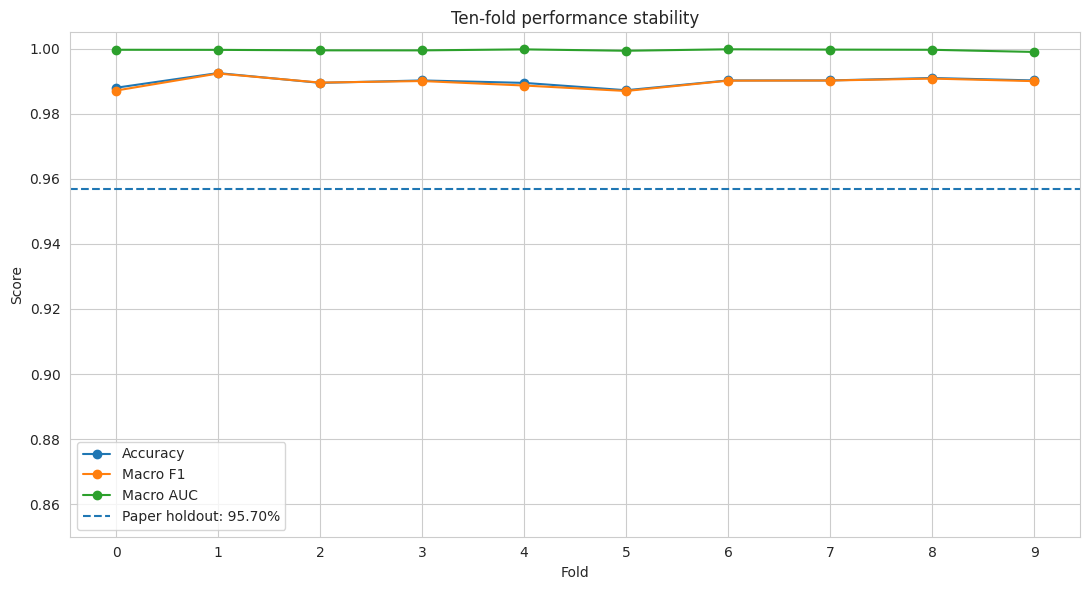

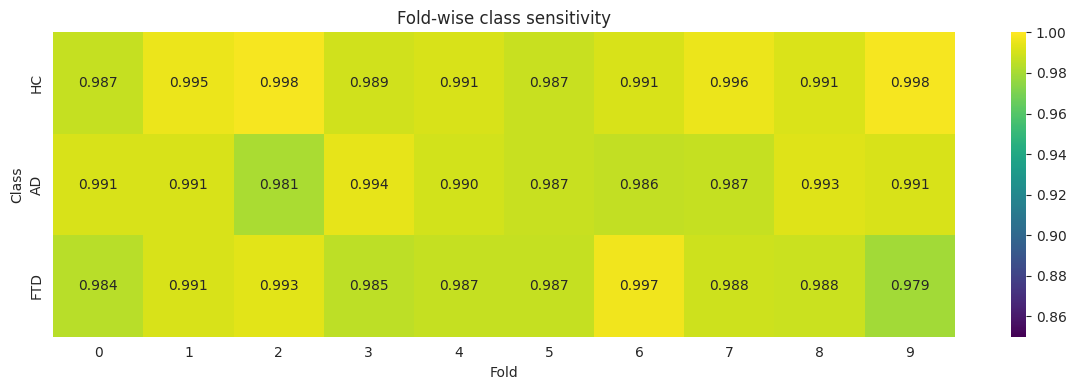

Reliability outputs saved in:
/kaggle/working/eeg_multiclass_final/cross_validation/statistical_reliability


In [26]:
# ============================================================
# STEP 3E
# RELIABILITY PLOTS AND SAVED TABLES
# ============================================================

plt.figure(
    figsize=(11, 6)
)

plt.plot(
    fold_overall_metrics_df[
        "fold"
    ],
    fold_overall_metrics_df[
        "accuracy"
    ],
    marker="o",
    label="Accuracy"
)

plt.plot(
    fold_overall_metrics_df[
        "fold"
    ],
    fold_overall_metrics_df[
        "macro_f1"
    ],
    marker="o",
    label="Macro F1"
)

plt.plot(
    fold_overall_metrics_df[
        "fold"
    ],
    fold_overall_metrics_df[
        "macro_auc_ovr"
    ],
    marker="o",
    label="Macro AUC"
)

plt.axhline(
    PAPER_HOLDOUT_TARGET,
    linestyle="--",
    label="Paper holdout: 95.70%"
)

plt.xticks(
    fold_values
)

plt.ylim(
    0.85,
    1.005
)

plt.xlabel(
    "Fold"
)

plt.ylabel(
    "Score"
)

plt.title(
    "Ten-fold performance stability"
)

plt.legend()
plt.tight_layout()

plt.savefig(
    RELIABILITY_ROOT
    / "fold_performance_stability.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# Per-class sensitivity heatmap
# ------------------------------------------------------------

sensitivity_heatmap = (
    fold_class_metrics_df
    .pivot(
        index="class_name",
        columns="fold",
        values="sensitivity"
    )
    .reindex(
        index=CLASS_NAMES,
        columns=fold_values
    )
)

plt.figure(
    figsize=(12, 4)
)

sns.heatmap(
    sensitivity_heatmap,
    annot=True,
    fmt=".3f",
    cmap="viridis",
    vmin=0.85,
    vmax=1.0
)

plt.xlabel(
    "Fold"
)

plt.ylabel(
    "Class"
)

plt.title(
    "Fold-wise class sensitivity"
)

plt.tight_layout()

plt.savefig(
    RELIABILITY_ROOT
    / "fold_class_sensitivity_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# Save outputs
# ------------------------------------------------------------

fold_overall_metrics_df.to_csv(
    RELIABILITY_ROOT
    / "fold_overall_metrics.csv",
    index=False
)

fold_class_metrics_df.to_csv(
    RELIABILITY_ROOT
    / "fold_class_metrics.csv",
    index=False
)

overall_reliability_summary_df.to_csv(
    RELIABILITY_ROOT
    / "overall_reliability_summary.csv",
    index=False
)

class_reliability_summary_df.to_csv(
    RELIABILITY_ROOT
    / "class_reliability_summary.csv",
    index=False
)

red_flag_fold_audit_df.to_csv(
    RELIABILITY_ROOT
    / "red_flag_fold_audit.csv",
    index=False
)


print(
    "Reliability outputs saved in:"
)

print(
    RELIABILITY_ROOT
)

In [27]:
# ============================================================
# STEP 4A
# MULTICLASS BRIER SCORE AND ECE
# ============================================================

from sklearn.metrics import log_loss

CALIBRATION_ROOT = (
    CV_ROOT
    / "calibration_analysis"
)

CALIBRATION_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

NUMBER_OF_CALIBRATION_BINS = 15
CALIBRATION_EPSILON = 1e-12


def multiclass_brier_score(
    true_labels,
    probabilities,
    number_of_classes=3
):
    true_labels = np.asarray(
        true_labels,
        dtype=np.int32
    )

    probabilities = np.asarray(
        probabilities,
        dtype=np.float64
    )

    one_hot_labels = np.eye(
        number_of_classes,
        dtype=np.float64
    )[
        true_labels
    ]

    # Standard multiclass Brier score.
    # Its theoretical range is 0 to 2.
    brier_score = np.mean(
        np.sum(
            np.square(
                probabilities
                - one_hot_labels
            ),
            axis=1
        )
    )

    # Dividing by two maps the score to approximately [0, 1].
    scaled_brier_score = (
        brier_score
        / 2.0
    )

    return (
        float(
            brier_score
        ),
        float(
            scaled_brier_score
        )
    )


def build_calibration_bins(
    predicted_probabilities,
    observed_outcomes,
    number_of_bins=15,
    strategy="uniform"
):
    predicted_probabilities = np.asarray(
        predicted_probabilities,
        dtype=np.float64
    )

    observed_outcomes = np.asarray(
        observed_outcomes,
        dtype=np.float64
    )

    if strategy == "uniform":

        bin_edges = np.linspace(
            0.0,
            1.0,
            number_of_bins + 1
        )

    elif strategy == "quantile":

        bin_edges = np.quantile(
            predicted_probabilities,
            np.linspace(
                0.0,
                1.0,
                number_of_bins + 1
            )
        )

        bin_edges[0] = 0.0
        bin_edges[-1] = 1.0

        bin_edges = np.unique(
            bin_edges
        )

        if len(
            bin_edges
        ) < 3:
            raise RuntimeError(
                "Too few unique probability values "
                "for quantile calibration bins."
            )

    else:

        raise ValueError(
            "strategy must be 'uniform' or 'quantile'."
        )


    rows = []
    total_samples = len(
        predicted_probabilities
    )


    for bin_index in range(
        len(
            bin_edges
        )
        - 1
    ):

        lower_edge = bin_edges[
            bin_index
        ]

        upper_edge = bin_edges[
            bin_index + 1
        ]

        if (
            bin_index
            == len(
                bin_edges
            )
            - 2
        ):

            bin_mask = (
                predicted_probabilities
                >= lower_edge
            ) & (
                predicted_probabilities
                <= upper_edge
            )

        else:

            bin_mask = (
                predicted_probabilities
                >= lower_edge
            ) & (
                predicted_probabilities
                < upper_edge
            )


        bin_count = int(
            np.sum(
                bin_mask
            )
        )

        if bin_count == 0:
            continue


        mean_confidence = float(
            np.mean(
                predicted_probabilities[
                    bin_mask
                ]
            )
        )

        observed_frequency = float(
            np.mean(
                observed_outcomes[
                    bin_mask
                ]
            )
        )

        absolute_gap = abs(
            observed_frequency
            - mean_confidence
        )

        rows.append({
            "bin_index": bin_index + 1,

            "lower_edge": float(
                lower_edge
            ),

            "upper_edge": float(
                upper_edge
            ),

            "count": bin_count,

            "weight": float(
                bin_count
                / total_samples
            ),

            "mean_confidence": mean_confidence,

            "observed_frequency": (
                observed_frequency
            ),

            "absolute_gap": float(
                absolute_gap
            ),
        })


    return pd.DataFrame(
        rows
    )


def calculate_ece(
    predicted_probabilities,
    observed_outcomes,
    number_of_bins=15,
    strategy="uniform"
):
    calibration_table = build_calibration_bins(
        predicted_probabilities=(
            predicted_probabilities
        ),

        observed_outcomes=(
            observed_outcomes
        ),

        number_of_bins=(
            number_of_bins
        ),

        strategy=strategy
    )

    expected_calibration_error = float(
        np.sum(
            calibration_table[
                "weight"
            ]
            * calibration_table[
                "absolute_gap"
            ]
        )
    )

    maximum_calibration_error = float(
        calibration_table[
            "absolute_gap"
        ].max()
    )

    return (
        expected_calibration_error,
        maximum_calibration_error,
        calibration_table
    )


def calculate_calibration_metrics(
    true_labels,
    probabilities
):
    true_labels = np.asarray(
        true_labels,
        dtype=np.int32
    )

    probabilities = np.asarray(
        probabilities,
        dtype=np.float64
    )

    predicted_labels = np.argmax(
        probabilities,
        axis=1
    )

    confidence = np.max(
        probabilities,
        axis=1
    )

    correctness = (
        predicted_labels
        == true_labels
    ).astype(float)


    (
        brier_score,
        scaled_brier_score
    ) = multiclass_brier_score(
        true_labels,
        probabilities,
        number_of_classes=N_CLASSES
    )


    (
        uniform_ece,
        uniform_mce,
        uniform_table
    ) = calculate_ece(
        confidence,
        correctness,
        number_of_bins=(
            NUMBER_OF_CALIBRATION_BINS
        ),
        strategy="uniform"
    )


    (
        quantile_ece,
        quantile_mce,
        quantile_table
    ) = calculate_ece(
        confidence,
        correctness,
        number_of_bins=(
            NUMBER_OF_CALIBRATION_BINS
        ),
        strategy="quantile"
    )


    negative_log_likelihood = log_loss(
        true_labels,
        probabilities,
        labels=[0, 1, 2]
    )


    return {
        "multiclass_brier": (
            brier_score
        ),

        "scaled_brier_0_1": (
            scaled_brier_score
        ),

        "top_label_ece_uniform": (
            uniform_ece
        ),

        "top_label_mce_uniform": (
            uniform_mce
        ),

        "top_label_ece_quantile": (
            quantile_ece
        ),

        "top_label_mce_quantile": (
            quantile_mce
        ),

        "negative_log_likelihood": float(
            negative_log_likelihood
        ),

        "uniform_table": (
            uniform_table
        ),

        "quantile_table": (
            quantile_table
        ),
    }

In [28]:
# ============================================================
# STEP 4B
# OOF AND FOLD-WISE CALIBRATION RESULTS
# ============================================================

overall_calibration_result = (
    calculate_calibration_metrics(
        true_labels=oof_true_labels,
        probabilities=oof_probabilities
    )
)


overall_calibration_metrics_df = pd.DataFrame([
    {
        "samples": len(
            oof_true_labels
        ),

        "multiclass_brier": (
            overall_calibration_result[
                "multiclass_brier"
            ]
        ),

        "scaled_brier_0_1": (
            overall_calibration_result[
                "scaled_brier_0_1"
            ]
        ),

        "top_label_ece_uniform": (
            overall_calibration_result[
                "top_label_ece_uniform"
            ]
        ),

        "top_label_mce_uniform": (
            overall_calibration_result[
                "top_label_mce_uniform"
            ]
        ),

        "top_label_ece_quantile": (
            overall_calibration_result[
                "top_label_ece_quantile"
            ]
        ),

        "top_label_mce_quantile": (
            overall_calibration_result[
                "top_label_mce_quantile"
            ]
        ),

        "negative_log_likelihood": (
            overall_calibration_result[
                "negative_log_likelihood"
            ]
        ),
    }
])


print("=" * 90)
print("OVERALL OUT-OF-FOLD CALIBRATION")
print("=" * 90)

display(
    overall_calibration_metrics_df
)


# ------------------------------------------------------------
# Fold-wise calibration
# ------------------------------------------------------------

fold_calibration_rows = []


for fold_value in fold_values:

    fold_frame = (
        oof_predictions_df[
            oof_predictions_df[
                "fold"
            ]
            == fold_value
        ]
    )

    fold_true = (
        fold_frame[
            "true_label"
        ]
        .to_numpy(
            dtype=np.int32
        )
    )

    fold_probabilities = (
        fold_frame[
            probability_columns
        ]
        .to_numpy(
            dtype=np.float64
        )
    )

    fold_result = calculate_calibration_metrics(
        fold_true,
        fold_probabilities
    )

    fold_calibration_rows.append({
        "fold": int(
            fold_value
        ),

        "samples": len(
            fold_frame
        ),

        "multiclass_brier": (
            fold_result[
                "multiclass_brier"
            ]
        ),

        "scaled_brier_0_1": (
            fold_result[
                "scaled_brier_0_1"
            ]
        ),

        "top_label_ece_uniform": (
            fold_result[
                "top_label_ece_uniform"
            ]
        ),

        "top_label_mce_uniform": (
            fold_result[
                "top_label_mce_uniform"
            ]
        ),

        "top_label_ece_quantile": (
            fold_result[
                "top_label_ece_quantile"
            ]
        ),

        "top_label_mce_quantile": (
            fold_result[
                "top_label_mce_quantile"
            ]
        ),

        "negative_log_likelihood": (
            fold_result[
                "negative_log_likelihood"
            ]
        ),
    })


fold_calibration_metrics_df = pd.DataFrame(
    fold_calibration_rows
)


print("\nFold-wise calibration:")

display(
    fold_calibration_metrics_df
)

OVERALL OUT-OF-FOLD CALIBRATION


,samples,multiclass_brier,scaled_brier_0_1,top_label_ece_uniform,top_label_mce_uniform,top_label_ece_quantile,top_label_mce_quantile,negative_log_likelihood
0,13293,0.017718,0.008859,0.006724,0.619119,0.006577,0.017542,0.039785



Fold-wise calibration:


,fold,samples,multiclass_brier,scaled_brier_0_1,top_label_ece_uniform,top_label_mce_uniform,top_label_ece_quantile,top_label_mce_quantile,negative_log_likelihood
0,0,1330,0.019568,0.009784,0.009211,0.642138,0.009303,0.056976,0.041510
1,1,1330,0.014215,0.007107,0.008801,0.688809,0.006104,0.010087,0.033454
2,2,1330,0.020122,0.010061,0.006580,0.495959,0.005623,0.009573,0.046562
3,3,1329,0.017377,0.008689,0.012512,0.467951,0.008966,0.053117,0.037905
4,4,1329,0.016785,0.008392,0.010290,0.439387,0.007911,0.025661,0.034537
5,5,1329,0.021895,0.010947,0.008877,0.520238,0.009366,0.062513,0.048082
6,6,1329,0.015661,0.007831,0.005969,0.229086,0.010815,0.064074,0.035415
7,7,1329,0.016631,0.008316,0.010589,0.625898,0.008492,0.030137,0.036788
8,8,1329,0.016579,0.008289,0.007443,0.489403,0.006262,0.018633,0.038932
9,9,1329,0.018344,0.009172,0.007703,0.383894,0.007805,0.048281,0.044669


In [29]:
# ============================================================
# STEP 4C
# CALIBRATION RELIABILITY ACROSS FOLDS
# ============================================================

calibration_metric_names = [
    "multiclass_brier",
    "scaled_brier_0_1",
    "top_label_ece_uniform",
    "top_label_mce_uniform",
    "top_label_ece_quantile",
    "top_label_mce_quantile",
    "negative_log_likelihood",
]


calibration_summary_rows = []


for metric_name in calibration_metric_names:

    summary = summarize_fold_values(
        fold_calibration_metrics_df[
            metric_name
        ]
    )

    calibration_summary_rows.append({
        "metric": metric_name,
        **summary
    })


calibration_fold_summary_df = pd.DataFrame(
    calibration_summary_rows
)


calibration_fold_summary_df[
    "mean_plus_minus_std"
] = (
    calibration_fold_summary_df[
        "mean"
    ].map(
        lambda value: f"{value:.5f}"
    )
    + " ± "
    + calibration_fold_summary_df[
        "std"
    ].map(
        lambda value: f"{value:.5f}"
    )
)


calibration_fold_summary_df[
    "ci95"
] = (
    "["
    + calibration_fold_summary_df[
        "ci95_lower"
    ].map(
        lambda value: f"{value:.5f}"
    )
    + ", "
    + calibration_fold_summary_df[
        "ci95_upper"
    ].map(
        lambda value: f"{value:.5f}"
    )
    + "]"
)


print("=" * 90)
print("CALIBRATION STABILITY ACROSS 10 FOLDS")
print("=" * 90)

display(
    calibration_fold_summary_df[
        [
            "metric",
            "mean_plus_minus_std",
            "ci95",
            "minimum",
            "maximum",
        ]
    ]
)

CALIBRATION STABILITY ACROSS 10 FOLDS


,metric,mean_plus_minus_std,ci95,minimum,maximum
0,multiclass_brier,0.01772 ± 0.00229,"[0.01608, 0.01935]",0.014215,0.021895
1,scaled_brier_0_1,0.00886 ± 0.00114,"[0.00804, 0.00968]",0.007107,0.010947
2,top_label_ece_uniform,0.00880 ± 0.00198,"[0.00738, 0.01022]",0.005969,0.012512
3,top_label_mce_uniform,0.49828 ± 0.13490,"[0.40177, 0.59478]",0.229086,0.688809
4,top_label_ece_quantile,0.00806 ± 0.00166,"[0.00687, 0.00926]",0.005623,0.010815
5,top_label_mce_quantile,0.03791 ± 0.02148,"[0.02254, 0.05327]",0.009573,0.064074
6,negative_log_likelihood,0.03979 ± 0.00518,"[0.03608, 0.04349]",0.033454,0.048082


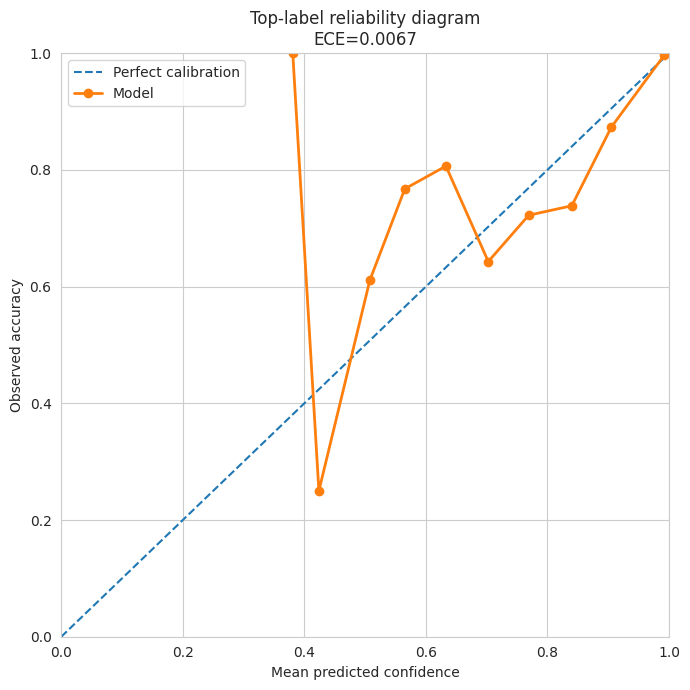

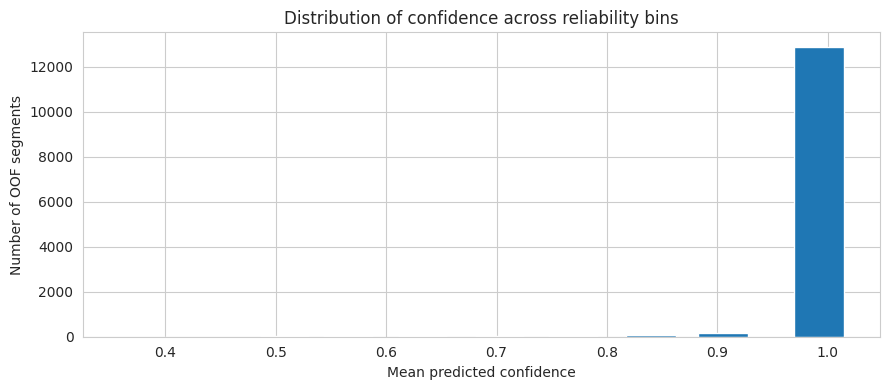

In [30]:
# ============================================================
# STEP 4D
# TOP-LABEL RELIABILITY DIAGRAM
# ============================================================

top_label_uniform_table = (
    overall_calibration_result[
        "uniform_table"
    ]
)


plt.figure(
    figsize=(7, 7)
)

plt.plot(
    [
        0,
        1
    ],
    [
        0,
        1
    ],
    linestyle="--",
    label="Perfect calibration"
)

plt.plot(
    top_label_uniform_table[
        "mean_confidence"
    ],
    top_label_uniform_table[
        "observed_frequency"
    ],
    marker="o",
    linewidth=2,
    label="Model"
)

plt.xlabel(
    "Mean predicted confidence"
)

plt.ylabel(
    "Observed accuracy"
)

plt.title(
    "Top-label reliability diagram\n"
    f"ECE={overall_calibration_result['top_label_ece_uniform']:.4f}"
)

plt.xlim(
    0,
    1
)

plt.ylim(
    0,
    1
)

plt.legend()
plt.tight_layout()

plt.savefig(
    CALIBRATION_ROOT
    / "top_label_reliability_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# Confidence-bin counts
# ------------------------------------------------------------

plt.figure(
    figsize=(9, 4)
)

plt.bar(
    top_label_uniform_table[
        "mean_confidence"
    ],
    top_label_uniform_table[
        "count"
    ],
    width=0.045
)

plt.xlabel(
    "Mean predicted confidence"
)

plt.ylabel(
    "Number of OOF segments"
)

plt.title(
    "Distribution of confidence across reliability bins"
)

plt.tight_layout()

plt.savefig(
    CALIBRATION_ROOT
    / "top_label_confidence_histogram.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

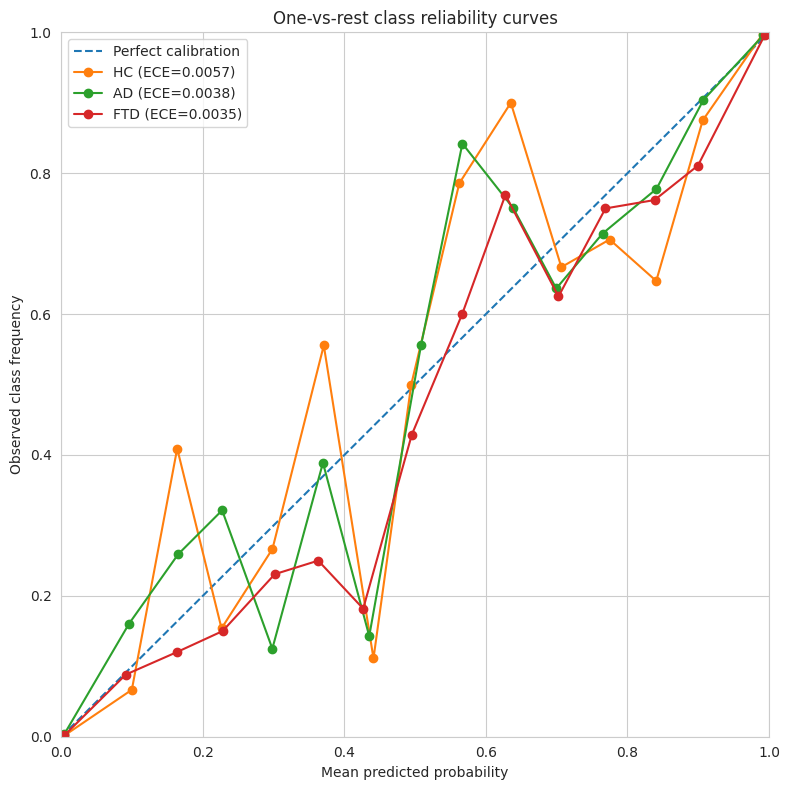

Class-wise calibration:


,class_label,class_name,one_vs_rest_brier,one_vs_rest_ece,one_vs_rest_mce
0,0,HC,0.004776,0.005680,0.330034
1,1,AD,0.007651,0.003794,0.292294
2,2,FTD,0.005290,0.003528,0.244791


In [31]:
# ============================================================
# STEP 4E
# CLASS-WISE ONE-VS-REST RELIABILITY CURVES
# ============================================================

class_calibration_rows = []
class_calibration_tables = {}


plt.figure(
    figsize=(8, 8)
)

plt.plot(
    [
        0,
        1
    ],
    [
        0,
        1
    ],
    linestyle="--",
    label="Perfect calibration"
)


for class_label, class_name in enumerate(
    CLASS_NAMES
):

    binary_true = (
        oof_true_labels
        == class_label
    ).astype(float)

    class_probabilities = (
        oof_probabilities[
            :,
            class_label
        ]
    )


    (
        class_ece,
        class_mce,
        class_table
    ) = calculate_ece(
        predicted_probabilities=(
            class_probabilities
        ),

        observed_outcomes=(
            binary_true
        ),

        number_of_bins=(
            NUMBER_OF_CALIBRATION_BINS
        ),

        strategy="uniform"
    )


    class_brier = float(
        np.mean(
            np.square(
                class_probabilities
                - binary_true
            )
        )
    )


    class_calibration_rows.append({
        "class_label": class_label,

        "class_name": class_name,

        "one_vs_rest_brier": (
            class_brier
        ),

        "one_vs_rest_ece": (
            class_ece
        ),

        "one_vs_rest_mce": (
            class_mce
        ),
    })


    class_calibration_tables[
        class_name
    ] = class_table


    plt.plot(
        class_table[
            "mean_confidence"
        ],
        class_table[
            "observed_frequency"
        ],
        marker="o",
        label=(
            f"{class_name} "
            f"(ECE={class_ece:.4f})"
        )
    )


plt.xlabel(
    "Mean predicted probability"
)

plt.ylabel(
    "Observed class frequency"
)

plt.title(
    "One-vs-rest class reliability curves"
)

plt.xlim(
    0,
    1
)

plt.ylim(
    0,
    1
)

plt.legend()
plt.tight_layout()

plt.savefig(
    CALIBRATION_ROOT
    / "classwise_reliability_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


class_calibration_metrics_df = pd.DataFrame(
    class_calibration_rows
)


print(
    "Class-wise calibration:"
)

display(
    class_calibration_metrics_df
)

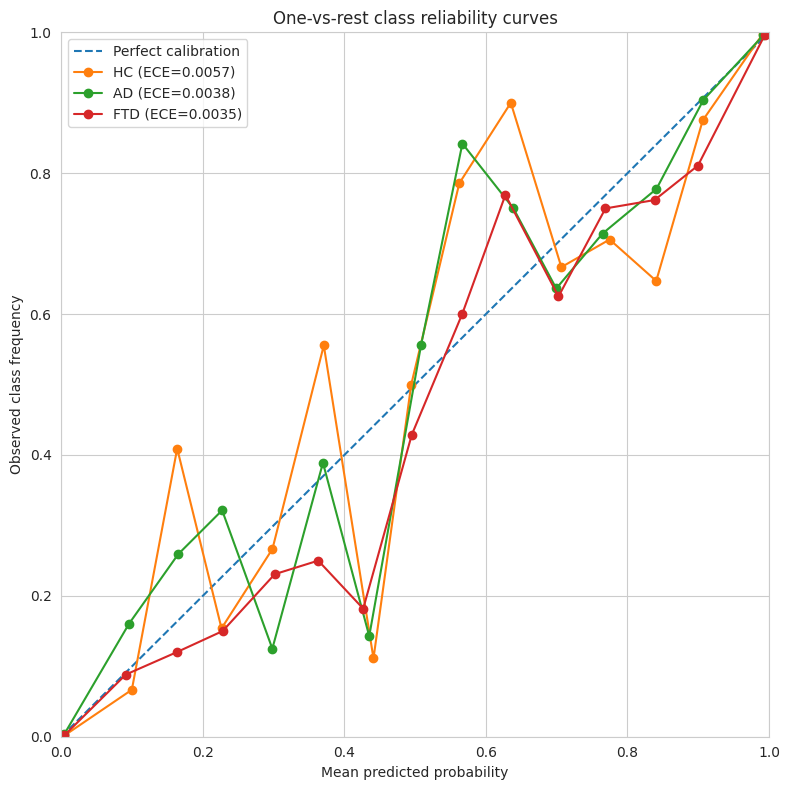

Class-wise calibration:


,class_label,class_name,one_vs_rest_brier,one_vs_rest_ece,one_vs_rest_mce
0,0,HC,0.004776,0.005680,0.330034
1,1,AD,0.007651,0.003794,0.292294
2,2,FTD,0.005290,0.003528,0.244791


In [32]:
# ============================================================
# STEP 4E
# CLASS-WISE ONE-VS-REST RELIABILITY CURVES
# ============================================================

class_calibration_rows = []
class_calibration_tables = {}


plt.figure(
    figsize=(8, 8)
)

plt.plot(
    [
        0,
        1
    ],
    [
        0,
        1
    ],
    linestyle="--",
    label="Perfect calibration"
)


for class_label, class_name in enumerate(
    CLASS_NAMES
):

    binary_true = (
        oof_true_labels
        == class_label
    ).astype(float)

    class_probabilities = (
        oof_probabilities[
            :,
            class_label
        ]
    )


    (
        class_ece,
        class_mce,
        class_table
    ) = calculate_ece(
        predicted_probabilities=(
            class_probabilities
        ),

        observed_outcomes=(
            binary_true
        ),

        number_of_bins=(
            NUMBER_OF_CALIBRATION_BINS
        ),

        strategy="uniform"
    )


    class_brier = float(
        np.mean(
            np.square(
                class_probabilities
                - binary_true
            )
        )
    )


    class_calibration_rows.append({
        "class_label": class_label,

        "class_name": class_name,

        "one_vs_rest_brier": (
            class_brier
        ),

        "one_vs_rest_ece": (
            class_ece
        ),

        "one_vs_rest_mce": (
            class_mce
        ),
    })


    class_calibration_tables[
        class_name
    ] = class_table


    plt.plot(
        class_table[
            "mean_confidence"
        ],
        class_table[
            "observed_frequency"
        ],
        marker="o",
        label=(
            f"{class_name} "
            f"(ECE={class_ece:.4f})"
        )
    )


plt.xlabel(
    "Mean predicted probability"
)

plt.ylabel(
    "Observed class frequency"
)

plt.title(
    "One-vs-rest class reliability curves"
)

plt.xlim(
    0,
    1
)

plt.ylim(
    0,
    1
)

plt.legend()
plt.tight_layout()

plt.savefig(
    CALIBRATION_ROOT
    / "classwise_reliability_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


class_calibration_metrics_df = pd.DataFrame(
    class_calibration_rows
)


print(
    "Class-wise calibration:"
)

display(
    class_calibration_metrics_df
)